# Sigma Cas - 19/09/2025 - Line measures

In [1]:
import math
import os
import random as rnd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.optimize import curve_fit
from scipy.special import voigt_profile
from joblib import Parallel, delayed

import warnings
warnings.filterwarnings('ignore')

## Initial configuration

In [2]:
SPECTRUM_FILE_NAME = "_sigmacas_20250919_785.fit"

##########################
# Continuum fitting related constants
##########################

EXCLUDED_REGIONS = [(3720,3725),(3730,3740),(3745,3752),(3767,3773),(3795,3805),(3820,3850),(3880,3900),(3950,3990),(4060,4130),(4330,4355),(4840,4870),(6450,6500),(6515,6590)]

SIGMALO_RANGE=(1.70, 2.2)
SIGMAHI_RANGE=(9.90,10.10)
DEGREE_RANGE = (6,14)

##########################
# Noise evaluation related constants
##########################

NOISE_EVALUATION_WINDOW = (6000,6200)
NOISE_CONTINUUM_WINDOW = (5600,6400)

NOISE_CONTINUUM_DEGREE = 10 # Degree of the polynomial used to fit the continuum in the noise evaluation window

##########################
# Line fitting related constants
##########################

GAUSS_FIT_WINDOW = 3 # in FWHM units
VOIGT_FIT_WINDOW = 3 # in FWHM units

GAUSSIAN_FIT_PLOT_WINDOW = 2.25    # In FWHM units
VOIGT_FIT_PLOT_WINDOW = 4.0        # In FWHM units

#############################
# Lines fit bounds
#############################

GAUSS_LAMBDA_WIN = 3.0  # In angstrom
VOIGT_LAMBDA_WIN = 3.0  # In angstrom

GAUSS_AMP_MIN = -1.5
GAUSS_AMP_MAX = 0.0

GAUSS_SIGMA_MIN = 0.5  # Respect to the expected value (for single lines) or sigma instr (for blended lines)
GAUSS_SIGMA_MAX = 4.0  # Respect to the expected value (for single lines) or sigma instr (for blended lines)

VOIGT_SIGMA_MIN = 0.5  # Respect to the expected value (for single lines) or sigma instr (for blended lines)
VOIGT_SIGMA_MAX = 4.0  # Respect to the expected value (for single lines) or sigma instr (for blended lines)

INSTR_RESOLUTION = 850    # R = lambda/delta_lambda

#############################
# Blend fitting window
#############################

BLEND_SPAN_MARGIN_FACTOR = 1.25  # margin >= factor * (lam_max - lam_min)
BLEND_FWHM_MARGIN = 3.0          # margin >= this * FWHM of the broadest significant component
BLEND_MIN_EW_FRACTION = 0.1      # ignore components with EW < fraction * max EW
BLEND_WINDOW_MAX_ITER = 5
BLEND_WINDOW_TOL = 1.0           # Angstrom
VOIGT_GAMMA_MAX = 4.0            # voigt gamma upper bound, in units of sigma_instr

MONTECARLO_SAMPLES = 2500

ADD_NOISE = True

REMOVE_WORST_FITS = True
WORST_FIT_SIGMA_TO_REMOVE = 0.655 * math.log10(MONTECARLO_SAMPLES) + 1.27  # After this there should be (roughly) less than half an event
#WORST_FIT_PERC_TO_REMOVE = 50

SHOW_PARAM_DEPENDENCIES = False

## List of lines

In [3]:
measuring_lines = [{
    "name": "H beta",
    "model": "voigt",
    "central_wl": 4861.0,
    "winlo_range":(4550.0,4700.0),
    "winhi_range":(5100.0,5350.0)
    },
                   {
    "name": "He I 4009",
    "model": "gauss",
    "central_wl": 4009.0,
    "winlo_range":(3800.0,3925.0),
    "winhi_range":(4075.0,4200.0)
    },
                   {
    "name": "He I 4026",
    "model": "gauss",
    "central_wl": 4026.0,
    "winlo_range":(3800.0,3925.0),
    "winhi_range":(4100.0,4250.0)
    },
                   {
    "name": "He I 4388",
    "model": "gauss",
    "central_wl": 4388.0,
    "winlo_range":(4050.0,4225.0),
    "winhi_range":(4400.0,4550.0)
    },
                   {
    "name": "He I 4922",
    "model": "gauss",
    "central_wl": 4922.0,
    "winlo_range":(4650.0,4800.0),
    "winhi_range":(5000.0,5150.0)
    },
                   {
    "name": "He I 6678",
    "model": "gauss",
    "central_wl": 6678.0,
    "winlo_range":(6350.0,6630.0),
    "winhi_range":(6750.0,6875.0)
    }
]

In [4]:
measuring_blends = [{
    "name": "He I/Mg II 4471-81",
    "central_wls": [{"name": "He I 4471",    "wavelength": 4471.0}, 
                    {"name": "Mg II 4481",   "wavelength": 4481.0}, 
                    {"name": "Unknown 4490", "wavelength": 4490.0}],
    "winlo_range":(4175.0,4300.0),
    "winhi_range":(4525.0,4650.0)
    },
                    {
    "name": "He I 4713",
    "central_wls": [{"name": "O II 4699",    "wavelength": 4699.0}, 
                    {"name": "O II 4705",    "wavelength": 4705.0}, 
                    {"name": "He I 4713",    "wavelength": 4713.0}],
    "winlo_range":(4500.0,4625.0),
    "winhi_range":(4800.0,5050.0)
    },
                    {
    "name": "H delta / He I 4121-4144",
    "central_wls": [{"name": "O II 4072",    "wavelength": 4072.0}, 
                    {"name": "O II 4076",    "wavelength": 4076.0},
                    {"name": "O II 4089",    "wavelength": 4089.0},
                    {"name": "H delta",      "wavelength": 4101.0, "model": "voigt"},
                    {"name": "He I 4121",    "wavelength": 4121.0}, 
                    {"name": "O II 4133",    "wavelength": 4133.0}, 
                    {"name": "He I 4144",    "wavelength": 4144.0},
                    {"name": "Unknown 4153", "wavelength": 4153.0}],
    "winlo_range":(3800.0,3950.0),
    "winhi_range":(4200.0,4350.0)
    },
                    {
    "name": "H gamma",
    "central_wls": [{"name": "O II 4320",       "wavelength": 4320.0},
                    {"name": "H gamma",         "wavelength": 4341.0, "model": "voigt"}, 
                    {"name": "O II 4349",       "wavelength": 4349.0},
                    {"name": "O II 4367",       "wavelength": 4367.0}],
    "winlo_range":(4000.0,4225.0),
    "winhi_range":(4475.0,4600.0)
    },
                    {
    "name": "H alfa",
    "central_wls": [{"name": "Unknown 6535",   "wavelength": 6535.0},
                    {"name": "H alfa",         "wavelength": 6563.0, "model": "voigt"}, 
                    {"name": "C II 6578",      "wavelength": 6578.0},
                    {"name": "C II 6583",      "wavelength": 6583.0}],
    "winlo_range":(6300.0,6400.0),
    "winhi_range":(6675.0,6775.0)
    },
                    {
    "name": "S III 4254 / C II 4267",
    "central_wls": [{"name": "Unknown 4242",    "wavelength": 4242.0},
                    {"name": "S III 4254",      "wavelength": 4254.0},
                    {"name": "C II 4267",       "wavelength": 4267.0},
                    {"name": "Unknown 4277",    "wavelength": 4277.0},
                    {"name": "Unknown 4286",    "wavelength": 4286.0}],
    "winlo_range":(4000.0,4150.0),
    "winhi_range":(4400.0,4550.0)
    },
                   {
    "name": "He I 5016",
    "central_wls": [{"name": "N II 5005",      "wavelength": 5005.0},
                    {"name": "He I 5016",      "wavelength": 5016.0},
                    {"name": "Unknown 5025",   "wavelength": 5025.0},
                    {"name": "Unknown 5035",   "wavelength": 5035.0},
                    {"name": "He I 5048",      "wavelength": 5048.0},
                    {"name": "He I 5055",      "wavelength": 5055.0}],
    "winlo_range":(4800.0,4900.0),
    "winhi_range":(5100.0,5200.0)
    }
]

## Load spectrum

In [5]:
def load_spectrum(path):
    with fits.open(path) as hdul:
        hdr = hdul[0].header
        flux = hdul[0].data.astype(float)
        wl = hdr['CRVAL1'] + hdr['CDELT1'] * np.arange(hdr['NAXIS1'])
    good = flux > 0                      # drop the zeroed/bad pixels
    return wl[good], flux[good]

In [6]:
wl, flux = load_spectrum(SPECTRUM_FILE_NAME)

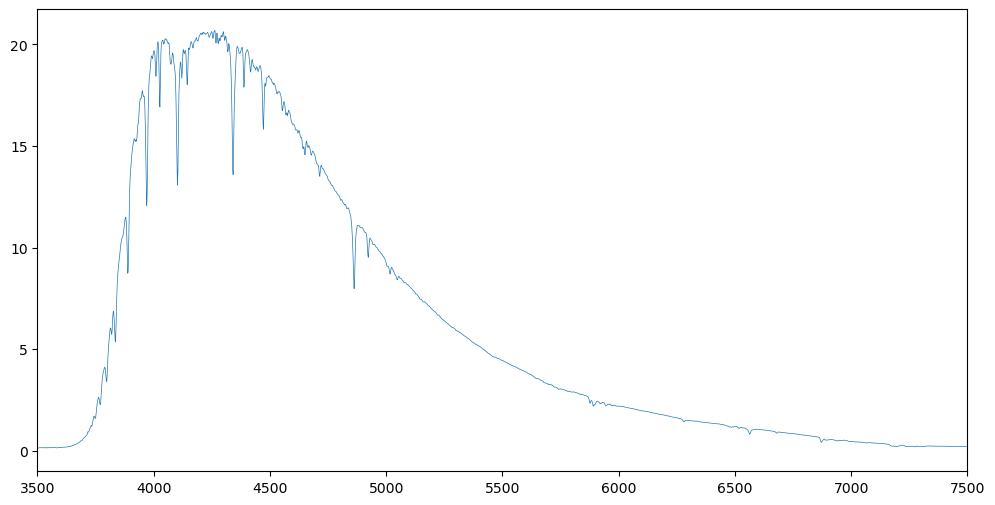

In [7]:
plt.figure(figsize=(12,6))
plt.plot(wl, flux, lw=0.5)
#plt.ylim(ymin, ymax)
plt.xlim(3500,7500)
plt.show()

## Continuum related procedures

In [8]:
def robust_continuum_fit(x, y, exclude_windows, degree, sigma_lo=3.0, sigma_hi=3.0, max_iter=20):
    seed = np.ones(len(x), dtype=bool)
    for lo, hi in exclude_windows:
        seed &= ~((x >= lo) & (x <= hi))
    xc = x - x.mean()
    mask = seed.copy()
    for i in range(max_iter):
        p = np.polyfit(xc[mask], y[mask], degree)
        resid = y - np.polyval(p, xc)
        s = resid[mask].std()
        new_mask = seed & (resid > -sigma_lo * s) & (resid < sigma_hi * s)
        if np.array_equal(new_mask, mask):
            break
        mask = new_mask
    return p, x.mean(), mask

In [9]:
def rectify_zone(wl, flux, zone, plot=False, degree=7, max_iter=20, sigma_lo=1.5, sigma_hi=10.0):
    zone_min, zone_max = zone
    enlarged_zone_min = zone_min - 50
    enlarged_zone_max = zone_max + 50

    mw = (wl >= enlarged_zone_min) & (wl <= enlarged_zone_max)
    p, wlmean, mask = robust_continuum_fit(wl[mw], flux[mw], EXCLUDED_REGIONS, degree, max_iter=max_iter, sigma_lo=sigma_lo, sigma_hi=sigma_hi)
    cont = np.polyval(p, wl - wlmean)[mw]

    if plot:
        plt.figure(figsize=(12,6))
        plt.plot(wl[mw], flux[mw], lw=0.5)
        plt.plot(wl[mw], cont, lw=0.5)
        #plt.ylim(ymin, ymax)
        plt.xlim(enlarged_zone_min,enlarged_zone_max)
        plt.title("Continuum fit")
        plt.show()    

    rect3 = flux[mw] / cont
    wl3 = wl[mw]
    mw = (wl3 >= zone_min) & (wl3 <= zone_max)
    rect3 = rect3[mw]
    wl3 = wl3[mw]  

    if plot:
        plt.figure(figsize=(12,6))
        plt.plot(wl3, rect3, lw=0.5)
        #plt.ylim(0.7, 1.05)
        plt.xlim(enlarged_zone_min,enlarged_zone_max)
        plt.title("Continuum calibrated spectrum")
        plt.show()

    return wl3, rect3

## Noise evaluation

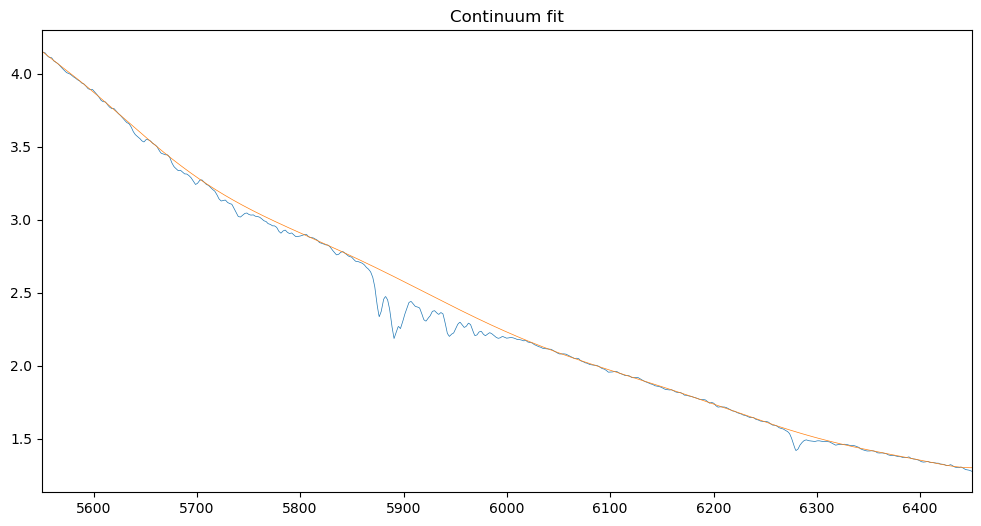

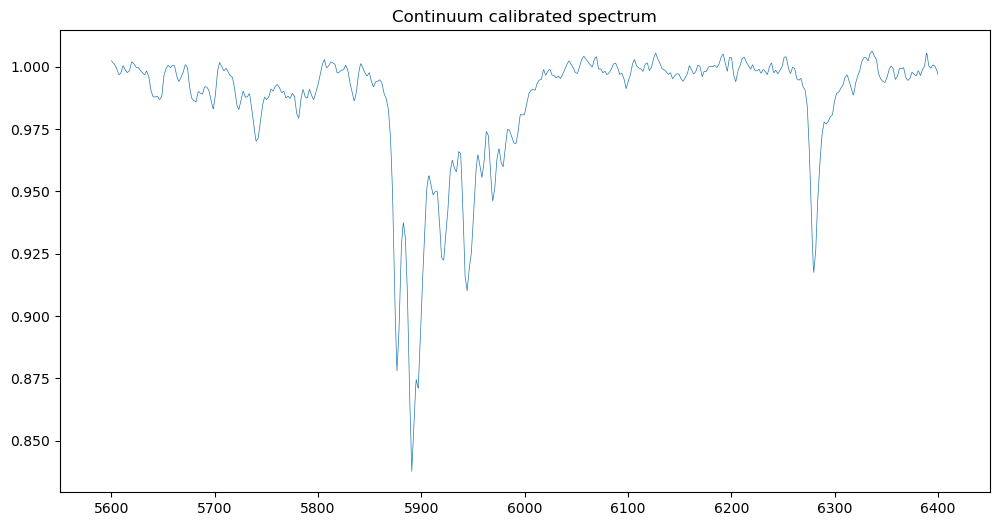

Noise =  0.0027476585714953324 Flux at eval window =  1.9612427949905396 SNR =  713.7869367529136


In [10]:
continuum_mask = (wl > NOISE_CONTINUUM_WINDOW[0]) & (wl < NOISE_CONTINUUM_WINDOW[1])
wlzone, rectzone = rectify_zone(wl, flux, NOISE_CONTINUUM_WINDOW, degree=NOISE_CONTINUUM_DEGREE, plot=True)
evaluation_mask = (wlzone > NOISE_EVALUATION_WINDOW[0]) & (wlzone < NOISE_EVALUATION_WINDOW[1])
noise = 1.4826 * np.median(
        np.abs(rectzone[evaluation_mask] - np.median(rectzone[evaluation_mask]))
    )
noise_evaluation_flux = np.median(flux[continuum_mask][evaluation_mask])
snr = noise_evaluation_flux / noise
print("Noise = ",noise, "Flux at eval window = ", noise_evaluation_flux, "SNR = ", snr)

## Line Fitting procedures

In [11]:
def gaussian_model(x, amp, mu, sigma, offset):
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2) + offset
    
    

def voigt_model(x, amp, mean, sigma, gamma, offset):
    # voigt_profile(x - mean, sigma, gamma) è normalizzata a area = 1
    return amp * voigt_profile(x - mean, sigma, gamma) + offset

In [12]:
def plot_gauss_fit(w, f, popt, name):
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, gaussian_model(w, *popt), "r", label="Gaussian fit")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [13]:
def calc_gaussian_chi2(w, f, amp, mu, sigma, offset, fwhm):
    wl_min = mu - fwhm
    wl_max = mu + fwhm
    mask = (w > wl_min) & (w < wl_max)
    res_w = w[mask]
    res_f = f[mask]
    return (((res_f - gaussian_model(res_w, amp, mu, sigma, offset)) ** 2)/gaussian_model(res_w, amp, mu, sigma, offset)).sum()

In [14]:
def fit_line_gaussian(wavelength, flux, lam_expected, fwhm_expected, plot=False, name=""):    
    peak_idx = np.argmin(np.abs(wavelength - lam_expected))
    amp0 = max(1.0 - flux[peak_idx], 0.0)
    offset = 1.0
    #p0 = [-amp0, lam_expected, fwhm_expected / 2.355, median_continuum]
    p0 = [-amp0, lam_expected, fwhm_expected / 2.355]
    #if plot:
    #    print("initial guess", p0)
    fit_wl_min = lam_expected - GAUSS_FIT_WINDOW * fwhm_expected
    fit_wl_max = lam_expected + GAUSS_FIT_WINDOW * fwhm_expected
    fit_window_mask = (wavelength > fit_wl_min) & (wavelength < fit_wl_max) 
    w = wavelength[fit_window_mask]
    f = flux[fit_window_mask]
    try:
        # popt, _ = curve_fit(gaussian_model, w, f, p0=p0)
        bounds_lo = [ GAUSS_AMP_MIN * amp0, lam_expected - GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MIN * fwhm_expected / 2.355]
        bounds_hi = [ GAUSS_AMP_MAX * amp0, lam_expected + GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MAX * fwhm_expected / 2.355]
        popt, _ = curve_fit(
            lambda x, a, m, s: gaussian_model(x, a, m, s, offset),
            w,
            f,
            p0 = p0,
            bounds = (bounds_lo, bounds_hi))
        #amp, mu, sigma, offset = popt
        amp, mu, sigma = popt
            
        sigma_nom = abs(sigma)
        fwhm_fit = 2.355 * sigma_nom
        fwhm_nom = fwhm_fit #np.clip(fwhm_fit, 0.7 * fwhm_instr, 1.5 * fwhm_instr)
        ew_nom = np.sqrt(2 * np.pi) * abs(amp) * sigma_nom / offset

        chi2 = calc_gaussian_chi2(w, f, amp, mu, sigma, offset, fwhm_nom)
        
        if plot:
            print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\noffset =",offset,"\nchi2 = ",chi2)
            plot_mask = (w >= mu-GAUSSIAN_FIT_PLOT_WINDOW*fwhm_nom) & (w <= mu+GAUSSIAN_FIT_PLOT_WINDOW*fwhm_nom)
            plot_gauss_fit(w[plot_mask], f[plot_mask], (amp, mu, sigma, offset), name)
    except RuntimeError:
        fwhm_nom = np.nan
        ew_nom = np.nan
        mu = np.nan
        amp = np.nan
        chi2 = np.nan

    return (mu, ew_nom, fwhm_nom, amp, chi2)

In [15]:
def plot_voigt_fit(w, f, popt, name):
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, voigt_model(w, *popt), "r", label="Voigt fit")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [16]:
def calc_voigt_chi2(w, f, amp, mu, sigma, gam, offset, fwhm):
    wl_min = mu - 2 * fwhm
    wl_max = mu + 2 * fwhm
    mask = (w > wl_min) & (w < wl_max)
    res_w = w[mask]
    res_f = f[mask]
    return (((res_f - voigt_model(res_w, amp, mu, sigma, gam, offset))**2)/voigt_model(res_w, amp, mu, sigma, gam, offset)).sum()

In [17]:
def fit_line_voigt(wavelength, flux, lam_expected, fwhm_expected, plot=False, name=""):
    
    peak_idx = np.argmin(np.abs(wavelength - lam_expected))
    amp0 = max(1.0 - flux[peak_idx], 0.0)
    offset = 1.0
    p0 = [-amp0, lam_expected, fwhm_expected / 2.355, fwhm_expected / 2.355]
    #p0 = [-amp0, lam_expected, fwhm_expected / 2.355, fwhm_expected / 2.355, offset]
    fit_wl_min = lam_expected - VOIGT_FIT_WINDOW * fwhm_expected
    fit_wl_max = lam_expected + VOIGT_FIT_WINDOW * fwhm_expected
    fit_window_mask = (wavelength > fit_wl_min) & (wavelength < fit_wl_max) 
    w = wavelength[fit_window_mask]
    f = flux[fit_window_mask]
    #if plot:
    #    print("initial guess", p0)
    try:
        #popt, _ = curve_fit(voigt_model, w, f, p0=p0)
        popt, _ = curve_fit(
            lambda x, a, m, s, g: voigt_model(x, a, m, s, g, offset),
            w,
            f,
            p0 = p0)
        #amp, mu, sigma, gam, offset = popt
        amp, mu, sigma, gam = popt
        #sigma_nom = abs(sigma)

        intensity = amp * voigt_profile(0.0, sigma, gam)
        
        f_g = 2 * sigma * np.sqrt(2 * np.log(2))
        f_l = 2 * gam
        fwhm_nom = 0.5346 * f_l + np.sqrt(0.2166 * f_l**2 + f_g**2)
        
        ew_nom = abs(amp)/offset

        chi2 = calc_voigt_chi2(w, f, amp, mu, sigma, gam, offset, fwhm_nom)
        
        if plot:
            print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\ngamma =",gam,"\noffset =",offset,"\nchi2 =",chi2)
            plot_mask = (w >= mu-VOIGT_FIT_PLOT_WINDOW*fwhm_nom) & (w <= mu+VOIGT_FIT_PLOT_WINDOW*fwhm_nom)
            plot_voigt_fit(w[plot_mask], f[plot_mask], (amp, mu, sigma, gam, offset), name)
    except RuntimeError:
        fwhm_nom = np.nan
        ew_nom = np.nan
        mu = np.nan
        intensity = np.nan
        chi2 = np.nan

    return (mu, ew_nom, fwhm_nom, intensity, chi2)

In [18]:
# Number of fit parameters used by each component model:
#   gauss : amp (line depth), mu, sigma
#   voigt : amp (area),       mu, sigma, gamma
PARAMS_PER_MODEL = {"gauss": 3, "voigt": 4}


def normalize_model_name(line):
    """Return 'gauss' or 'voigt' for a blend component dict (default: 'gauss')."""
    model = str(line.get("model", "gauss")).strip().lower()
    if model in ("gauss", "gaussian"):
        return "gauss"
    if model == "voigt":
        return "voigt"
    raise ValueError(f"Unknown model '{line.get('model')}' for blend component "
                     f"'{line.get('name')}': use 'gauss' or 'voigt'")


def voigt_fwhm(sigma, gamma):
    # Olivero & Longbothum approximation (same formula used by fit_line_voigt)
    f_g = 2 * sigma * np.sqrt(2 * np.log(2))
    f_l = 2 * gamma
    return 0.5346 * f_l + np.sqrt(0.2166 * f_l**2 + f_g**2)


def component_profile(x, model, params):
    """Profile of a single blend component, WITHOUT the continuum offset."""
    if model == "voigt":
        amp, mu, sigma, gamma = params
        return amp * voigt_profile(x - mu, sigma, gamma)
    amp, mu, sigma = params
    return amp * np.exp(-0.5 * ((x - mu) / sigma) ** 2)


def split_blend_params(models, params):
    """Split the flat parameter vector into one tuple per component."""
    result = []
    k = 0
    for model in models:
        n = PARAMS_PER_MODEL[model]
        result.append(tuple(params[k:k + n]))
        k += n
    return result


def multi_line_model(x, offset, models, *params):
    """Sum of gaussian / voigt components (one entry of `models` per component) + continuum."""
    model = np.zeros_like(x, dtype=float)
    for m, p in zip(models, split_blend_params(models, params)):
        model += component_profile(x, m, p)
    return model + offset

In [19]:
def multi_line_initial_guess(lines, wavelength, flux):
    """Initial guess and bounds for a blend of gaussian / voigt components.

    `lines` is the list of component dicts ("wavelength" and optionally "model").
    """
    p0 = []
    bounds_lo = []
    bounds_hi = []
    for line in lines:
        model = normalize_model_name(line)
        lam0 = line["wavelength"]
        peak_index = np.argmin(np.abs(wavelength - lam0))
        depth0 = min(flux[peak_index] - 1.0, 0.0)
        fwhm_instr = lam0 / INSTR_RESOLUTION
        sigma_instr = fwhm_instr / 2.355

        if model == "gauss":
            p0 += [depth0, lam0, sigma_instr]
            bounds_lo += [GAUSS_AMP_MIN, lam0 - GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MIN * sigma_instr]
            bounds_hi += [GAUSS_AMP_MAX, lam0 + GAUSS_LAMBDA_WIN, GAUSS_SIGMA_MAX * sigma_instr]
        else:
            # Voigt amplitude is the (normalised) area, i.e. -EW for a continuum of 1.
            # Convert the observed depth to an area using the starting profile shape.
            gamma0 = 0.5 * sigma_instr
            amp0 = depth0 / voigt_profile(0.0, sigma_instr, gamma0)
            # Same limits as the gaussian, expressed as areas (depth * width)
            area_scale = np.sqrt(2 * np.pi) * 4.0 * sigma_instr
            amp_lo, amp_hi = -1.5 * area_scale, 0.5 * area_scale
            p0 += [float(np.clip(amp0, amp_lo, amp_hi)), lam0, sigma_instr, gamma0]
            bounds_lo += [amp_lo, lam0 - VOIGT_LAMBDA_WIN, VOIGT_SIGMA_MIN * sigma_instr, 0.0]
            bounds_hi += [amp_hi, lam0 + VOIGT_LAMBDA_WIN, VOIGT_SIGMA_MAX * sigma_instr, VOIGT_GAMMA_MAX * sigma_instr]

    return (p0, bounds_lo, bounds_hi)

In [20]:
def plot_multi_line_fit(w, f, popt, models, component, name):
    """Plot data, total blend fit and the component called `name`.

    `component` is the (model, params) pair of the component to highlight.
    """
    comp_model, comp_params = component
    plt.figure(figsize=(6,4))
    plt.plot(w, f, "k", label="Data")
    plt.plot(w, multi_line_model(w, 1.0, models, *popt), "r", label="Blend fit")
    plt.plot(w, component_profile(w, comp_model, comp_params) + 1.0, "y",
             label=f"{name} ({comp_model})")
    plt.legend()
    plt.xlabel("Wavelength")
    plt.title(name)
    plt.show()

In [21]:
def blend_initial_fwhm(line):
    """FWHM assumed only for the FIRST pass, before any fit exists.
    gauss: instrumental FWHM. voigt: widest profile the fit bounds allow (generous first window)."""
    sigma_instr = line["wavelength"] / INSTR_RESOLUTION / 2.355
    if normalize_model_name(line) == "voigt":
        return voigt_fwhm(VOIGT_SIGMA_MAX * sigma_instr, VOIGT_GAMMA_MAX * sigma_instr)
    return 2.355 * sigma_instr


def blend_fit_window(lines, fwhms, limits=None):
    """margin = max(span margin, BLEND_FWHM_MARGIN * max(fwhms)), applied on both sides of the outermost components."""
    lams = [l["wavelength"] for l in lines]
    lam_min, lam_max = min(lams), max(lams)
    margin = max(BLEND_SPAN_MARGIN_FACTOR * (lam_max - lam_min), BLEND_FWHM_MARGIN * max(fwhms))
    lo, hi = lam_min - margin, lam_max + margin
    if limits is not None:
        lo, hi = max(lo, limits[0]), min(hi, limits[1])
    return lo, hi


def fit_blend_adaptive(wavelength, flux, lines, limits=None):
    """Fit, rebuild the window from the fitted FWHMs, refit until the window is stable.
    Returns (results, window). `limits` = (lo, hi) range that must never be exceeded."""
    window = blend_fit_window(lines, [blend_initial_fwhm(l) for l in lines], limits)
    results = None
    for _ in range(BLEND_WINDOW_MAX_ITER):
        try:
            new_results = fit_blend_group(wavelength, flux, lines, fit_window=window)
        except RuntimeError:
            if results is None:
                raise
            break                      # keep the last window that worked
        results = new_results
        ews = np.array([r[2] for r in results])
        fwhms = np.array([r[3] for r in results])
        significant = ews >= BLEND_MIN_EW_FRACTION * ews.max()
        new_window = blend_fit_window(lines, fwhms[significant], limits)
        converged = max(abs(new_window[0] - window[0]), abs(new_window[1] - window[1])) < BLEND_WINDOW_TOL
        window = new_window
        if converged:
            break
    return results, window

In [22]:
def fit_blend_group(wavelength, flux, lines, plot=False, fit_window=None):
    models = [normalize_model_name(l) for l in lines]
    if fit_window is None:   # fallback when called without a precomputed window
        fit_window = blend_fit_window(lines, [blend_initial_fwhm(l) for l in lines])
    wl_min, wl_max = fit_window
    
    mask = (wavelength > wl_min) & (wavelength < wl_max)
    
    w = wavelength[mask]
    f = flux[mask]
    offset = 1.0
    
    p0, bounds_lo, bounds_hi = multi_line_initial_guess(lines, w, f)
    
    popt, _ = curve_fit(
            lambda x, *params: multi_line_model(x, offset, models, *params),
            w,
            f,
            p0 = p0,
            bounds = (bounds_lo, bounds_hi))
    
    # One parameter tuple per component (3 values for gauss, 4 for voigt)
    component_results = split_blend_params(models, popt)

    chi2 = (((multi_line_model(w, offset, models, *popt) - f) ** 2)/multi_line_model(w, offset, models, *popt)).sum()
    
    final_results = []
    
    for line, model, params in zip(lines, models, component_results):
        if model == "voigt":
            amp, mu, sigma, gam = params
            fwhm_nom = voigt_fwhm(sigma, gam)
            ew_nom = abs(amp) / offset
            intensity = amp * voigt_profile(0.0, sigma, gam)
        else:
            amp, mu, sigma = params
            fwhm_nom = 2.355 * abs(sigma)
            ew_nom = np.sqrt(2 * np.pi) * abs(amp) * abs(sigma) / offset
            intensity = amp
        
        final_results.append((line["name"], mu, ew_nom, fwhm_nom, intensity, chi2))
        
        if plot:
            print(line["name"], f"({model})")
            if model == "voigt":
                print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\ngamma =",gam,"\noffset =",offset,"\nchi2 =",chi2)
            else:
                print("amp =",amp,"\nmu =",mu,"\nsigma =",sigma,"\noffset =",offset,"\nchi2 =",chi2)
            plot_multi_line_fit(w, f, popt, models, (model, params), line["name"])
        
    return final_results

## Functions for error on continuum placement

In [23]:
# ---------------------------------------------------------------- configuration
N_JOBS  = max(1, (os.cpu_count() or 2) - 2)   # worker processes; leave 2 logical CPUs free
MC_SEED = None                                 # set e.g. to 12345 for reproducible Monte Carlo runs


# ---------------------------------------------------------------- helpers
def _draw_trials(rng, n, sigma_lo_range, sigma_hi_range, degree_range, maxiter_range, winlo_range, winhi_range):
    """Draw all the random continuum parameters up front (same distributions as before)."""
    trials = []
    for i in range(1, n):                       # same count as the original loop
        trials.append(dict(
            i=i,
            sigma_lo=float(rng.uniform(*sigma_lo_range)),
            sigma_hi=float(rng.uniform(*sigma_hi_range)),
            degree=int(rng.integers(*degree_range)),
            maxiter=int(rng.integers(*maxiter_range)),
            win_lo=float(rng.uniform(*winlo_range)),
            win_hi=float(rng.uniform(*winhi_range)),
            seed=int(rng.integers(0, 2**63 - 1)),   # private seed for this trial's noise
        ))
    return trials


def _rectify_trial(wl, flux, t, add_noise, noise, noise_evaluation_flux):
    win = (t["win_lo"], t["win_hi"])
    if add_noise:
        win_mask = (wl > win[0]) & (wl < win[1])
        rescaled_noise = noise * np.sqrt(np.median(flux[win_mask]) * noise_evaluation_flux)
        flux = flux + np.random.default_rng(t["seed"]).normal(0, rescaled_noise, size=len(flux))
    return rectify_zone(wl, flux, win, plot=False, sigma_lo=t["sigma_lo"], sigma_hi=t["sigma_hi"],
                        degree=t["degree"], max_iter=t["maxiter"])


def _run_parallel(chunk_worker, trials, **common):
    """Split the trials in chunks (so the spectrum is shipped once per chunk, not once per trial),
    run them on N_JOBS processes, and return (records, errors)."""
    if N_JOBS == 1:
        outs = [chunk_worker(trials, **common)]
    else:
        n_chunks = min(len(trials), N_JOBS * 4)          # a few chunks per worker -> good load balancing
        chunks = [list(c) for c in np.array_split(np.array(trials, dtype=object), n_chunks)]
        outs = Parallel(n_jobs=N_JOBS)(delayed(chunk_worker)(c, **common) for c in chunks)
    records = [r for o in outs for r in o[0]]
    errors  = [e for o in outs for e in o[1]]
    if errors:
        print(f"{len(errors)} trials failed; first error: {errors[0]}")
    return records, errors

In [24]:
def _single_line_chunk(trials, wl, flux, model, expected_lam, expected_width, add_noise, noise, noise_evaluation_flux):
    records, errors = [], []
    for t in trials:
        try:
            wlzone, rectzone = _rectify_trial(wl, flux, t, add_noise, noise, noise_evaluation_flux)
            if model == "voigt":
                lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, expected_lam, expected_width, plot=False)
            else:
                lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, expected_lam, expected_width, plot=False)
            records.append({"sigma_lo": t["sigma_lo"], "sigma_hi": t["sigma_hi"], "degree": t["degree"],
                            "maxiter": t["maxiter"], "win_lo": t["win_lo"], "win_hi": t["win_hi"],
                            "wavelength": lam, "ew": ew, "fwhm": fwhm, "intensity": amp, "chi2": chi2})
        except Exception as e:
            errors.append(repr(e))
    return records, errors

def remove_worst_fits_from_results(results):
    removed = 100
    while removed > 0:
        m_res = results["chi2"].mean()
        s_res = results["chi2"].std()
        filtered_results = results[(results["chi2"]-m_res).abs() <= WORST_FIT_SIGMA_TO_REMOVE*s_res]
        removed = len(results) - len(filtered_results)
        # print(f"Removed {removed}")
        results = filtered_results
    return results

def fit_varying_continuum(wl, flux, model, expected_lam, expected_width, add_noise=False, noise=0.0, noise_evaluation_flux=1.0, sigma_lo_range=(1.5,2.0), sigma_hi_range=(9.9,10.1), degree_range=(6,14), maxiter_range=(10,30), winlo_range=None, winhi_range=None):
    rng = np.random.default_rng(MC_SEED)
    trials = _draw_trials(rng, MONTECARLO_SAMPLES, sigma_lo_range, sigma_hi_range, degree_range, maxiter_range, winlo_range, winhi_range)
    records, _ = _run_parallel(_single_line_chunk, trials, wl=wl, flux=flux, model=model,
                               expected_lam=expected_lam, expected_width=expected_width,
                               add_noise=add_noise, noise=noise, noise_evaluation_flux=noise_evaluation_flux)
    cols = ["sigma_lo","sigma_hi","degree","maxiter","win_lo","win_hi","wavelength","ew","fwhm","intensity","chi2"]
    results = pd.DataFrame(records, columns=cols)

    if REMOVE_WORST_FITS:
        results = remove_worst_fits_from_results(results)

    m = results["ew"].mean()
    results["ew_dist"] = abs(results["ew"] - m)
    
    return results

In [25]:
def refit_with_best(column, results, wl, flux, model, expected_lam, expected_width, plot=False, name=""):
    sort_col = column + "_dist"
    sorted_results = results.sort_values(by=[sort_col], ascending=True)
    best = sorted_results.iloc[0]
    sigma_lo = best["sigma_lo"]
    sigma_hi = best["sigma_hi"]
    degree = int(best["degree"])
    maxiter = int(best["maxiter"])
    win = (best["win_lo"], best["win_hi"])
    wlzone, rectzone = rectify_zone(wl, flux, win, plot=plot, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
    if (model == "voigt"):
        lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, expected_lam, expected_width, plot=plot, name=name)
    else:
        lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, expected_lam, expected_width, plot=plot, name=name)
    return (lam, ew, fwhm, amp)

In [26]:
def _blend_chunk(trials, wl, flux, blended_lines, fit_window, add_noise, noise, noise_evaluation_flux):
    records, errors = [], []
    for t in trials:
        try:
            wlzone, rectzone = _rectify_trial(wl, flux, t, add_noise, noise, noise_evaluation_flux)
            blend_results = fit_blend_group(wlzone, rectzone, blended_lines, plot=False, fit_window=fit_window)
            for name, lam_detected, ew, fwhm, amp, chi2 in blend_results:
                records.append({"sigma_lo": t["sigma_lo"], "sigma_hi": t["sigma_hi"], "degree": t["degree"],
                                "maxiter": t["maxiter"], "win_lo": t["win_lo"], "win_hi": t["win_hi"],
                                "record": t["i"], "line": name, "wavelength": lam_detected, "ew": ew,
                                "fwhm": fwhm, "intensity": amp, "chi2": chi2})
        except Exception as e:
            errors.append(repr(e))
    return records, errors


def fit_blend_varying_continuum(wl, flux, blended_lines, add_noise=False, noise=0.0, noise_evaluation_flux=1.0, sigma_lo_range=(1.5,2.0), sigma_hi_range=(9.9,10.1), degree_range=(6,14), maxiter_range=(10,30), winlo_range=None, winhi_range=None, fit_window=None):
    rng = np.random.default_rng(MC_SEED)
    trials = _draw_trials(rng, MONTECARLO_SAMPLES, sigma_lo_range, sigma_hi_range, degree_range, maxiter_range, winlo_range, winhi_range)
    records, _ = _run_parallel(_blend_chunk, trials, wl=wl, flux=flux, blended_lines=blended_lines,
                               fit_window=fit_window, add_noise=add_noise, noise=noise,
                               noise_evaluation_flux=noise_evaluation_flux)
    cols = ["sigma_lo","sigma_hi","degree","maxiter","win_lo","win_hi","record","line","wavelength","ew","fwhm","intensity","chi2"]
    results = pd.DataFrame(records, columns=cols)

    if REMOVE_WORST_FITS:
        results = remove_worst_fits_from_results(results)

    results["ew_dist"] = (results["ew"] - results.groupby("line")["ew"].transform("mean")).abs()
    results["ew_dist_ssq"] = (results["ew_dist"]**2).groupby(results["record"]).transform("sum")

    return results

In [27]:
def refit_blend_with_best(column, results, wl, flux, blended_lines, expected_width, plot=False, name="", fit_window=None):
    sort_col = column + "_dist_ssq"
    sorted_results = results.sort_values(by=[sort_col], ascending=True)
    best = sorted_results.iloc[0]
    sigma_lo = best["sigma_lo"]
    sigma_hi = best["sigma_hi"]
    degree = int(best["degree"])
    maxiter = int(best["maxiter"])
    win = (best["win_lo"], best["win_hi"])
    wlzone, rectzone = rectify_zone(wl, flux, win, plot=True, sigma_lo=sigma_lo, sigma_hi=sigma_hi, degree=degree, max_iter=maxiter)
    blend_results = fit_blend_group(wlzone, rectzone, blended_lines, plot=True, fit_window=fit_window)

## Complete measure procedures

In [28]:
def round_measurement(value, error):
    exponent = math.floor(math.log10(error))
    first_digit = int(error / (10 ** exponent))

    sig_figs = 2 if first_digit in (1,2) else 1

    decimals = sig_figs - exponent - 1

    value_rounded = round (value, decimals)
    error_rounded = round(error, decimals)

    return value_rounded, error_rounded

In [29]:
from IPython.display import Markdown
from IPython.display import display

def measure_line(wl, flux, measuring_line, show_param_dependencies=False):
    name = measuring_line["name"]
    
    display(Markdown(f"### Measuring {name}"))
    model = measuring_line["model"]
    central_wl = measuring_line["central_wl"]
    winlo_range = measuring_line["winlo_range"]
    winhi_range = measuring_line["winhi_range"]
    
    display(Markdown(f"#### {name} preliminary fit"))
    rect_win = (winlo_range[1], winhi_range[0])
    wlzone, rectzone = rectify_zone(wl, flux, rect_win, plot=True)
    if model == "voigt":
        lam, ew, fwhm, amp, chi2 = fit_line_voigt(wlzone, rectzone, central_wl, 5.0, plot=True, name=name)
    else:
        lam, ew, fwhm, amp, chi2 = fit_line_gaussian(wlzone, rectzone, central_wl, 5.0, plot=True, name=name)
    print("Lambda = ", lam, "Eq Width =", ew, "FWHM = ", fwhm, "Intensity = ", amp)
    
    display(Markdown(f"#### {name} optimization"))
    results = fit_varying_continuum(wl, flux, model, central_wl, fwhm, winlo_range=winlo_range, winhi_range=winhi_range, degree_range=DEGREE_RANGE, sigma_lo_range=SIGMALO_RANGE, sigma_hi_range=SIGMAHI_RANGE, add_noise=ADD_NOISE, noise=noise, noise_evaluation_flux=noise_evaluation_flux)

    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12,6))
    plt.subplots_adjust(wspace=0.5, hspace=0.5)
    
    m_ew = results["ew"].mean()
    s_ew = results["ew"].std()
    results.plot.hist(column=["ew"], title="EW mean=%g std dev=%g" % round_measurement(m_ew,s_ew), ax=axes[0,0])
    
    m_fwhm = results["fwhm"].mean()
    s_fwhm = results["fwhm"].std()
    results.plot.hist(column=["fwhm"], title="FWHM mean=%g std dev=%g" % round_measurement(m_fwhm,s_fwhm), ax=axes[0,1])
    
    m_wl = results["wavelength"].mean()
    s_wl = results["wavelength"].std()
    results.plot.hist(column=["wavelength"], title="Central wavelength mean=%g std dev=%g" % round_measurement(m_wl,s_wl), ax=axes[1,0])
    
    m_amp = results["intensity"].mean()
    s_amp = results["intensity"].std()
    results.plot.hist(column=["intensity"], title="Intensity mean=%g std dev=%g" % round_measurement(m_amp,s_amp), ax=axes[1,1])
    
    plt.show()

    display(Markdown(f"#### {name} re-fit with best parameters"))
    lam, ew, fwhm, amp = refit_with_best("ew", results, wl, flux, model, central_wl, m_fwhm, plot=True, name=name)
    print("Lambda = ", lam, "Eq Width =", ew, "FWHM = ", fwhm, "Intensity = ", amp)

    if show_param_dependencies:
        display(Markdown(f"#### {name} continuum parameters dependencies"))
        results["win_size"] = results["win_hi"] - results["win_lo"]
        results["dist"] = abs(results["ew"] - m_ew)

        results.plot.hist(column=["chi2"], figsize=(12,6), title="Chi quadro")
        
        sorted_results = results.sort_values(by=["dist"], ascending=True)
        sorted_results.plot(x="dist", y="sigma_lo", ylim=(0,6))
        sorted_results.plot(x="dist", y="degree", ylim=(2,15))
        sorted_results.plot(x="dist", y="maxiter", ylim=(8,32))
        sorted_results.plot(x="dist", y="win_size", ylim=(400,800))
        
        results.sort_values(by=["sigma_lo"], ascending=True).plot(x="sigma_lo", y="dist", ylim=(0,8))
        results.sort_values(by=["win_size"], ascending=True).plot(x="win_size", y="dist", ylim=(0,8))
        
        sorted_results.plot.scatter(x="degree", y="win_size", c="dist")
        sorted_results.plot.scatter(x="win_lo", y="win_hi", c="dist")
        plt.show()
    
    return pd.Series({"line_name":name, "wavelength":m_wl, "delta_wavelength":s_wl, "ew":m_ew, "delta_ew":s_ew, "fwhm":m_fwhm, "delta_fwhm":s_fwhm, "intensity": m_amp, "delta_intensity": s_amp})

In [30]:
def measure_blend(wl, flux, measuring_blend, show_param_dependencies=False):
    name = measuring_blend["name"]
    
    display(Markdown(f"### Measuring {name}"))
    blended_lines = measuring_blend["central_wls"]
    winlo_range = measuring_blend["winlo_range"]
    winhi_range = measuring_blend["winhi_range"]
    print("Blended lines=", blended_lines)
    display(Markdown(f"#### {name} preliminary fit"))
    rect_win = (winlo_range[1], winhi_range[0])
    wlzone, rectzone = rectify_zone(wl, flux, rect_win, plot=True)
    prelim_results, fit_window = fit_blend_adaptive(wlzone, rectzone, blended_lines, limits=rect_win)
    print("Fit window = (%.1f, %.1f)" % fit_window)
    fit_blend_group(wlzone, rectzone, blended_lines, plot=True, fit_window=fit_window)
    
    display(Markdown(f"#### {name} optimization"))
    results = fit_blend_varying_continuum(wl, flux, blended_lines, degree_range=DEGREE_RANGE, sigma_lo_range=SIGMALO_RANGE, sigma_hi_range=SIGMAHI_RANGE, add_noise=ADD_NOISE, noise=noise, noise_evaluation_flux=noise_evaluation_flux, winlo_range=winlo_range, winhi_range=winhi_range, fit_window=fit_window)

    blend_results = pd.DataFrame(columns=("line_name","wavelength","delta_wavelength","ew","delta_ew","fwhm","delta_fwhm","intensity","delta_intensity"))
    i = 0
    for line in blended_lines:
        line_name = line["name"]
        display(Markdown(f"#### Plotting results for {line_name}"))
        line_results = results[results["line"] == line["name"]]

        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12,6))
        plt.subplots_adjust(wspace=0.5, hspace=0.5)
        
        m_ew = line_results["ew"].mean()
        s_ew = line_results["ew"].std()
        line_results.plot.hist(column=["ew"], figsize=(12,6), title="EW mean=%g std dev=%g" % round_measurement(m_ew,s_ew), ax=axes[0,0])
    
        m_fwhm = line_results["fwhm"].mean()
        s_fwhm = line_results["fwhm"].std()
        line_results.plot.hist(column=["fwhm"], figsize=(12,6), title="FWHM mean=%g std dev=%g" % round_measurement(m_fwhm,s_fwhm), ax=axes[0,1])
        
        m_wl = line_results["wavelength"].mean()
        s_wl = line_results["wavelength"].std()
        line_results.plot.hist(column=["wavelength"], figsize=(12,6), title="Central wavelength mean=%g std dev=%g" % round_measurement(m_wl,s_wl), ax=axes[1,0])

        m_amp = line_results["intensity"].mean()
        s_amp = line_results["intensity"].std()
        line_results.plot.hist(column=["intensity"], figsize=(12,6), title="Intensity mean=%g std dev=%g" % round_measurement(m_amp,s_amp), ax=axes[1,1])
        plt.show()
    
        # print("Mean:", m_ew)
        # print("Std Dev:",s_ew)

        line_results = pd.Series({"line_name":line_name, "wavelength":m_wl, "delta_wavelength":s_wl, "ew":m_ew, "delta_ew":s_ew, "fwhm":m_fwhm, "delta_fwhm":s_fwhm, "intensity":m_amp, "delta_intensity":s_amp})
        blend_results.loc[i] = line_results
        i = i + 1

    display(Markdown(f"#### {name} re-fit with best parameters"))
    refit_blend_with_best("ew", results, wl, flux, blended_lines, m_fwhm, plot=True, name=name, fit_window=fit_window)

    if show_param_dependencies:
        display(Markdown(f"#### {name} continuum parameters dependencies"))

        results.plot.hist(column=["chi2"], figsize=(12,6), title="Chi quadro")
        
        for line in blended_lines:
            print("Plotting results for ",line["name"])
            line_results = results[results["line"] == line["name"]]
        
            m = line_results["ew"].mean()
            
            line_results["win_size"] = line_results["win_hi"] - line_results["win_lo"]
            line_results["dist"] = abs(line_results["ew"] - m)
            
            sorted_results = line_results.sort_values(by=["dist"], ascending=True)
            sorted_results.plot(x="dist", y="sigma_lo", ylim=(0,6))
            sorted_results.plot(x="dist", y="degree", ylim=(2,15))
            sorted_results.plot(x="dist", y="maxiter", ylim=(8,32))
            sorted_results.plot(x="dist", y="win_size", ylim=(250,800))
            
            line_results.sort_values(by=["sigma_lo"], ascending=True).plot(x="sigma_lo", y="dist", ylim=(0,8))
            line_results.sort_values(by=["win_size"], ascending=True).plot(x="win_size", y="dist", ylim=(0,8))
            
            sorted_results.plot.scatter(x="degree", y="win_size", c="dist")
            sorted_results.plot.scatter(x="win_lo", y="win_hi", c="dist")
            plt.show()
            
    return blend_results

## Measure All Lines

### Measuring H beta

#### H beta preliminary fit

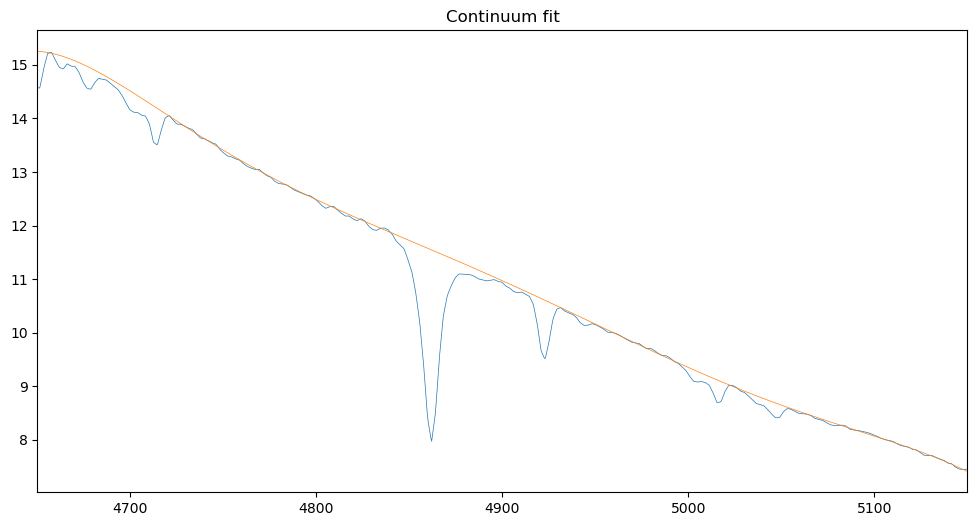

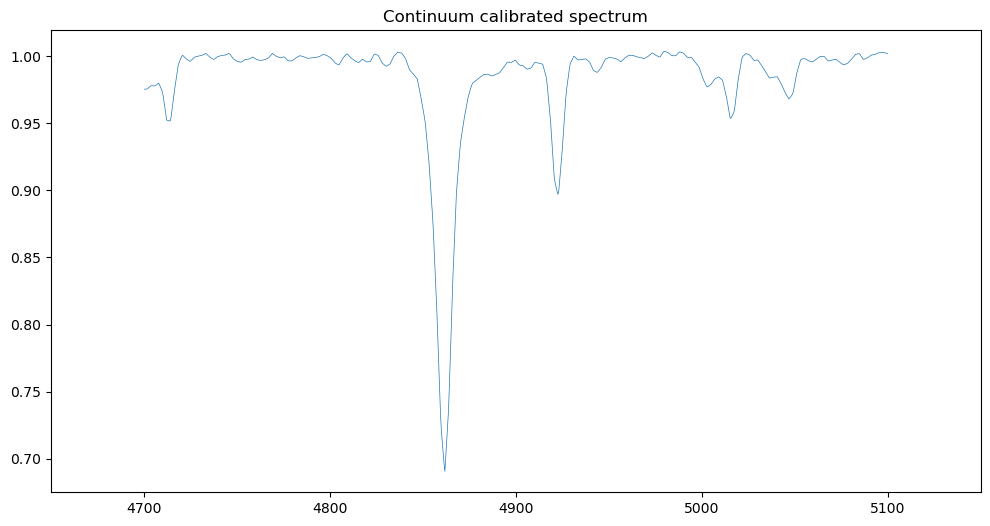

amp = -4.389424985118699 
mu = 4861.569418757136 
sigma = 2.2637267795426514 
gamma = 3.663746949733922 
offset = 1.0 
chi2 = 0.0009228222264948063


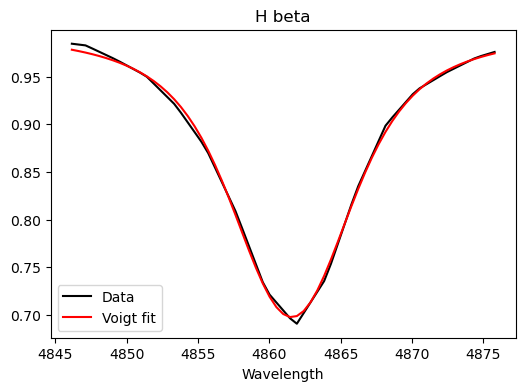

Lambda =  4861.569418757136 Eq Width = 4.389424985118699 FWHM =  10.245449967220772 Intensity =  -0.30255621270184374


#### H beta optimization

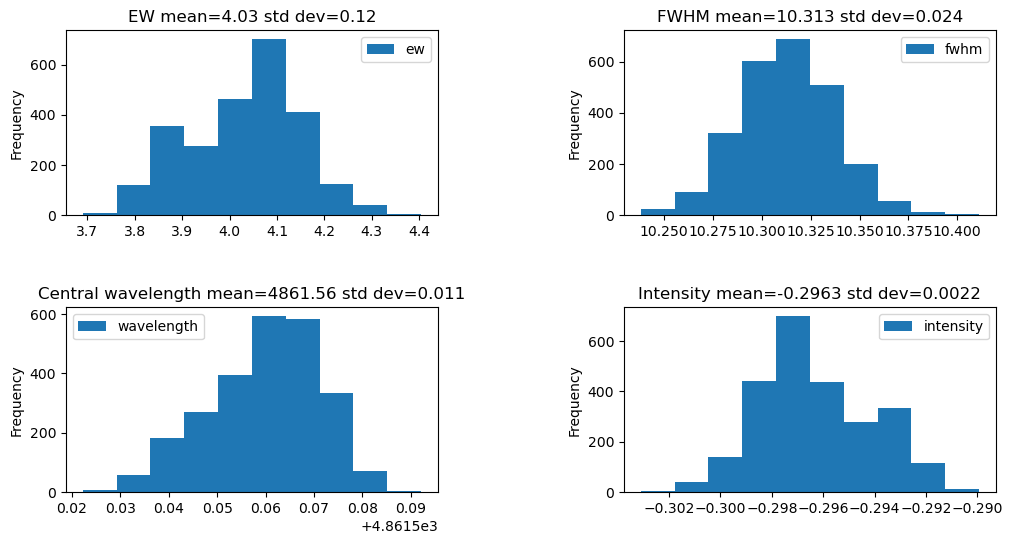

#### H beta re-fit with best parameters

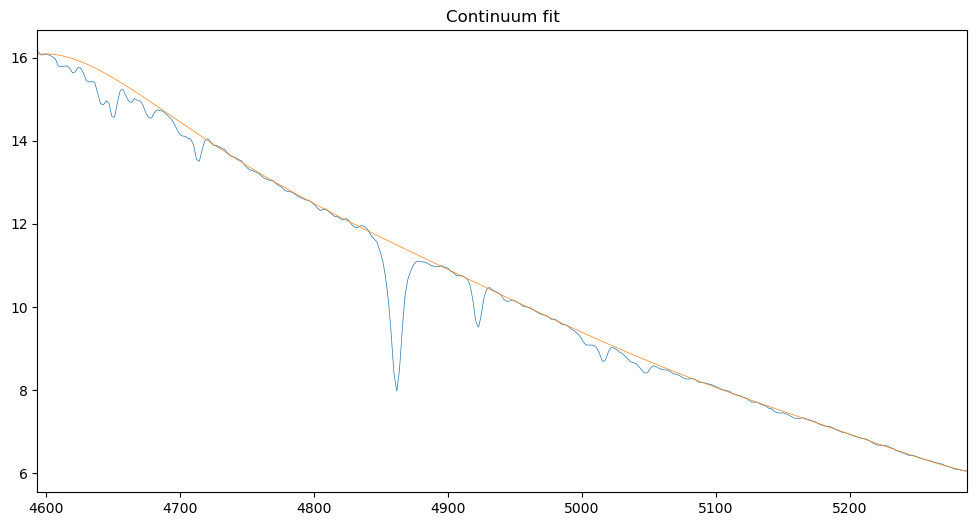

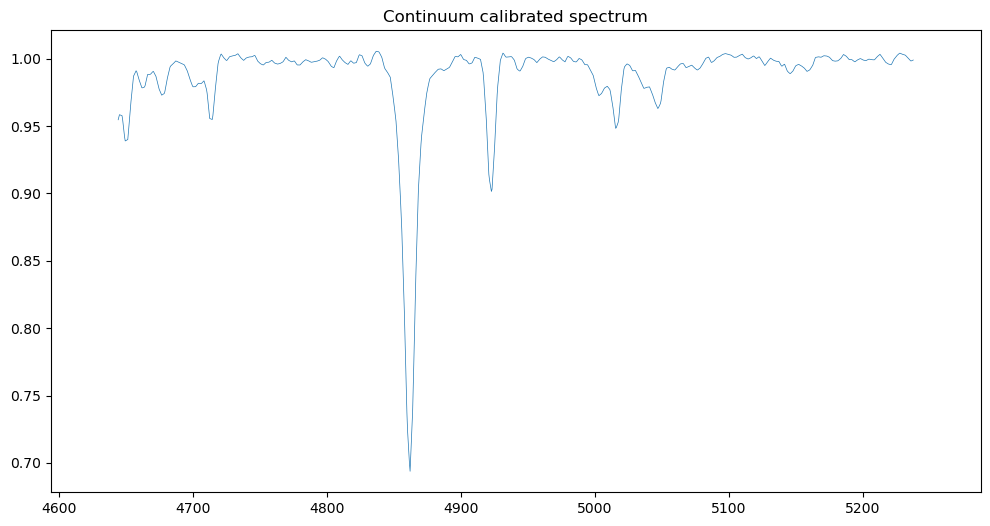

amp = -4.050483786595477 
mu = 4861.555609354778 
sigma = 2.8996010619635957 
gamma = 2.804492384293238 
offset = 1.0 
chi2 = 0.0016959774233088144


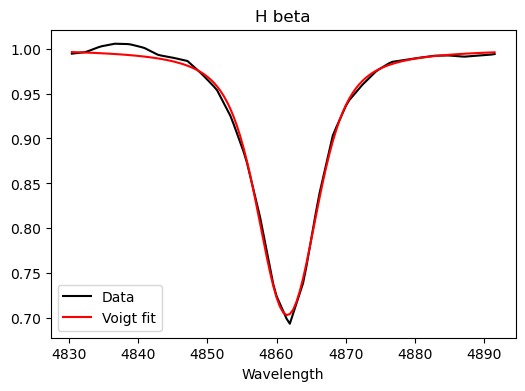

Lambda =  4861.555609354778 Eq Width = 4.050483786595477 FWHM =  10.308590777679466 Intensity =  -0.2966455514340696


### Measuring He I 4009

#### He I 4009 preliminary fit

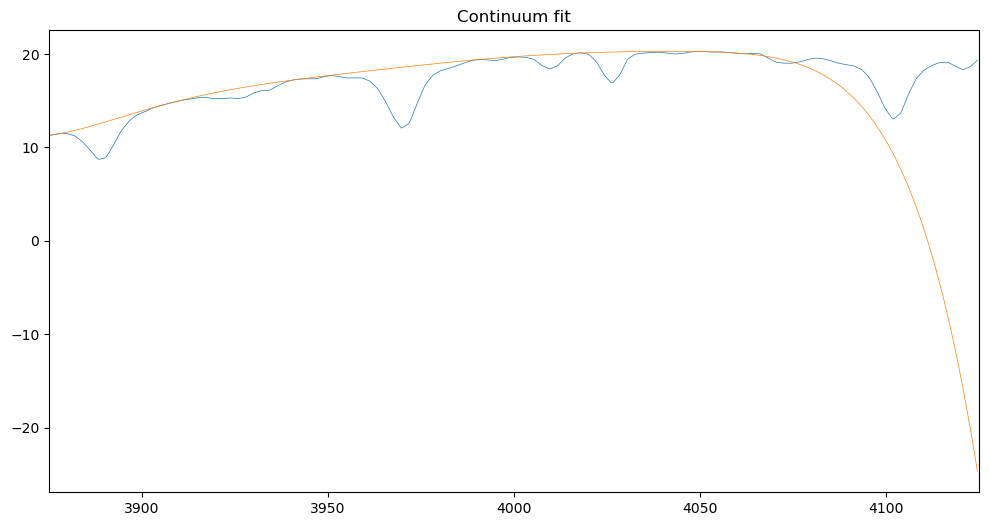

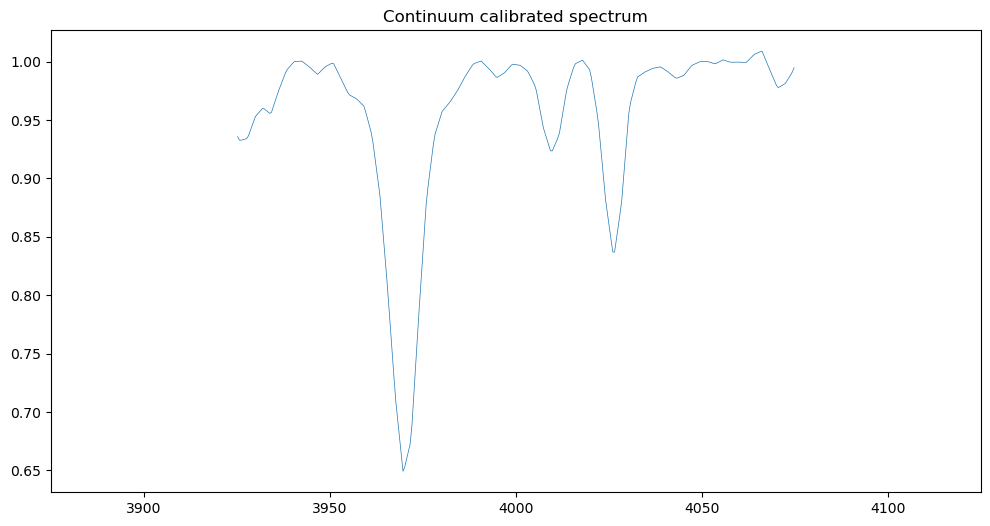

amp = -0.07589776786109924 
mu = 4009.6258777457524 
sigma = 2.8126604814778746 
offset = 1.0 
chi2 =  0.00011129937331327272


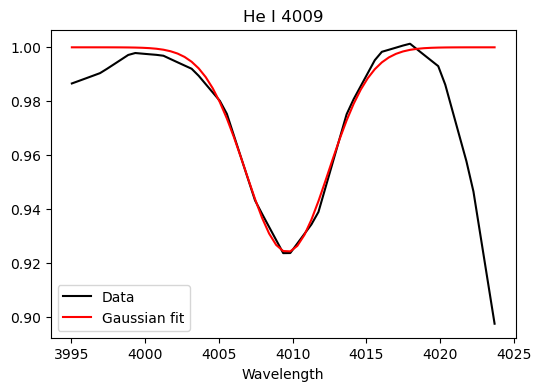

Lambda =  4009.6258777457524 Eq Width = 0.5351015993604089 FWHM =  6.623815433880394 Intensity =  -0.07589776786109924


#### He I 4009 optimization

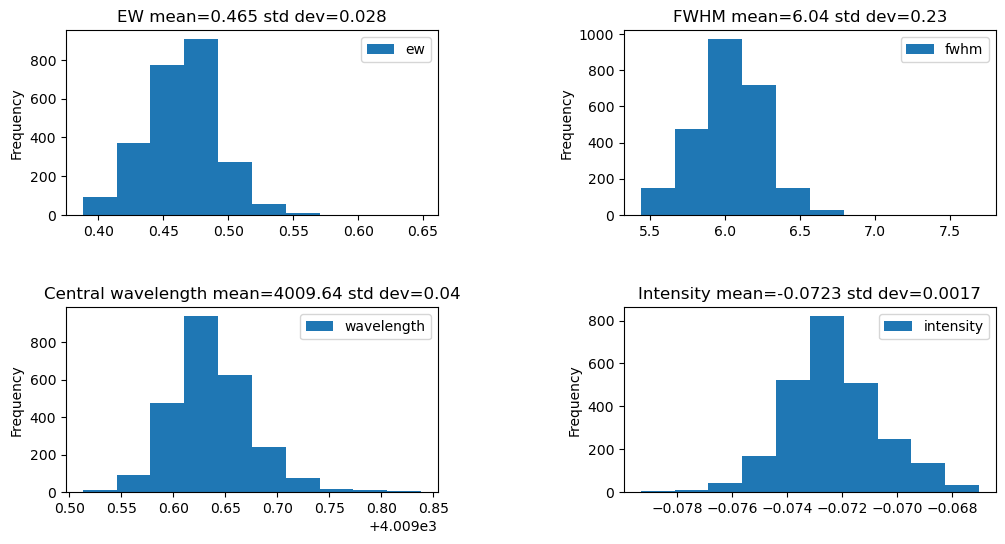

#### He I 4009 re-fit with best parameters

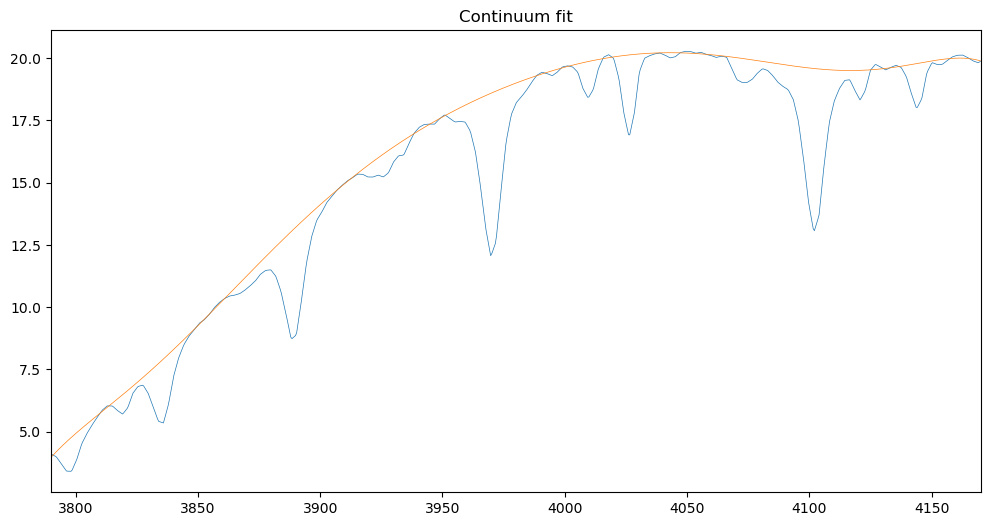

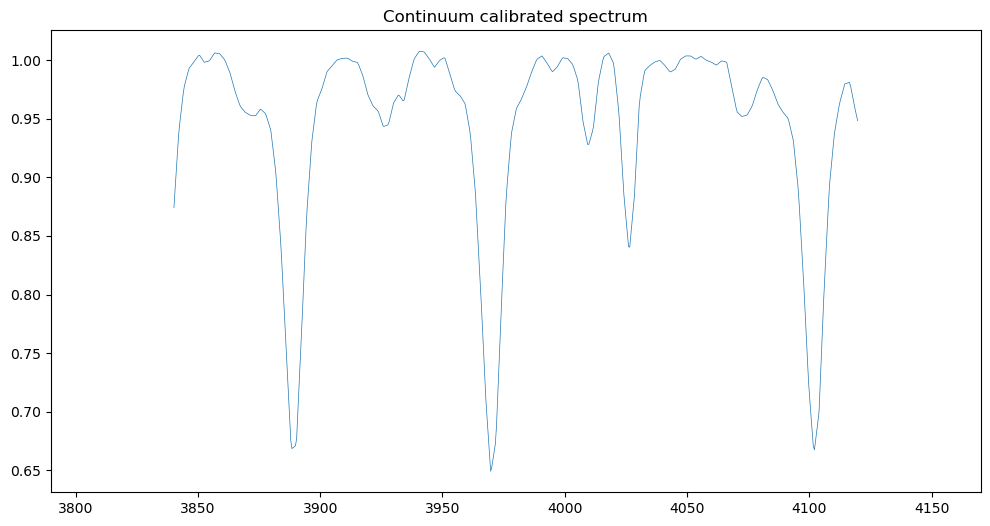

amp = -0.07276335195093012 
mu = 4009.636656786469 
sigma = 2.5893465061606644 
offset = 1.0 
chi2 =  0.00012344132230670114


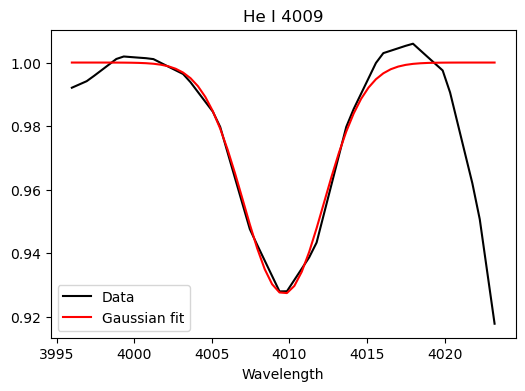

Lambda =  4009.636656786469 Eq Width = 0.47227265799226387 FWHM =  6.097911022008365 Intensity =  -0.07276335195093012


### Measuring He I 4026

#### He I 4026 preliminary fit

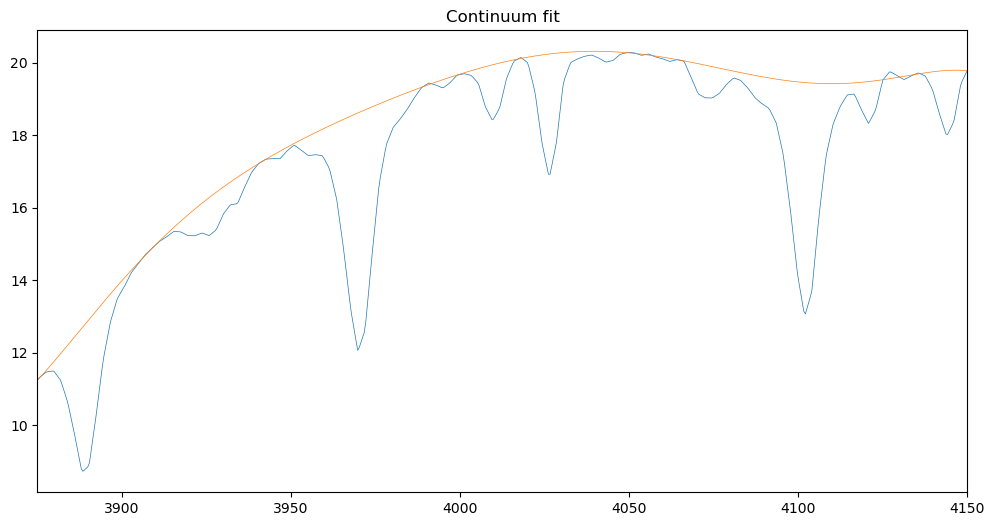

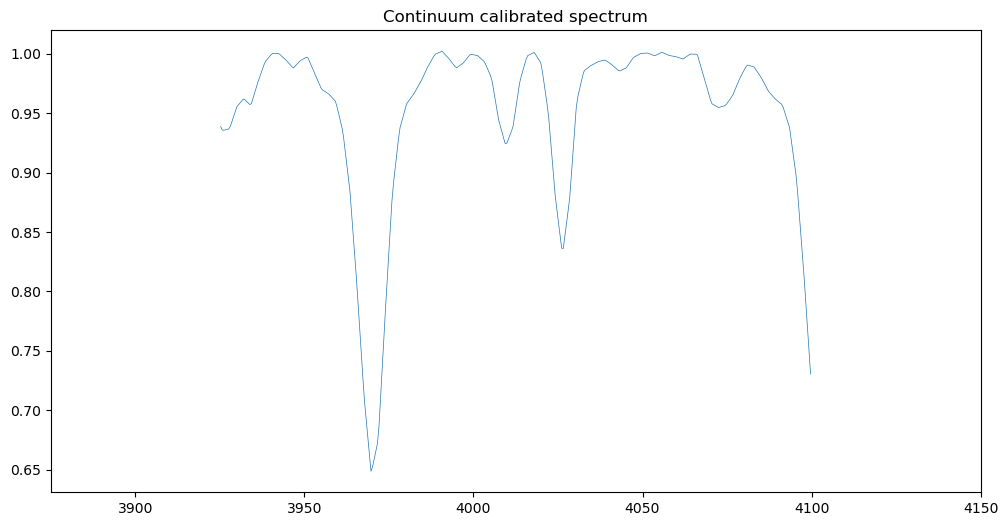

amp = -0.1596836429941971 
mu = 4026.298693855647 
sigma = 2.7598659420592373 
offset = 1.0 
chi2 =  0.00026278288506797836


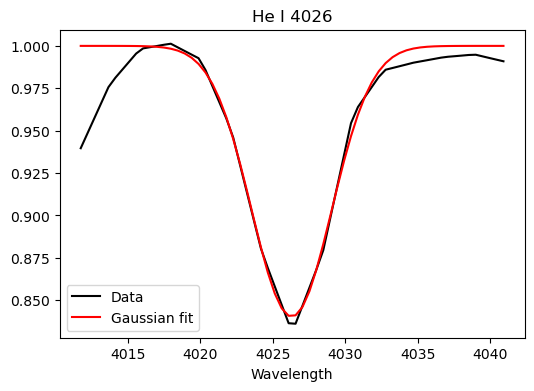

Lambda =  4026.298693855647 Eq Width = 1.104684736248497 FWHM =  6.499484293549504 Intensity =  -0.1596836429941971


#### He I 4026 optimization

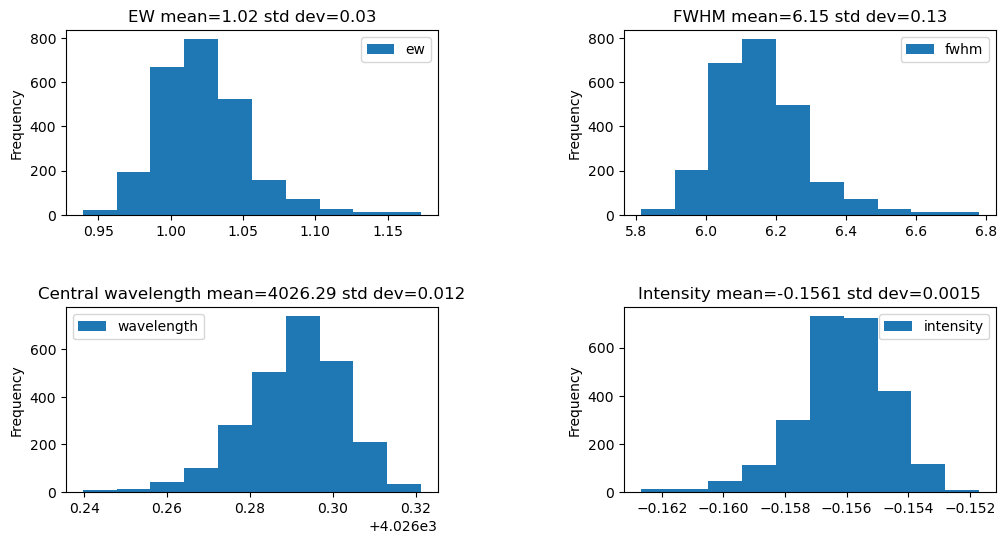

#### He I 4026 re-fit with best parameters

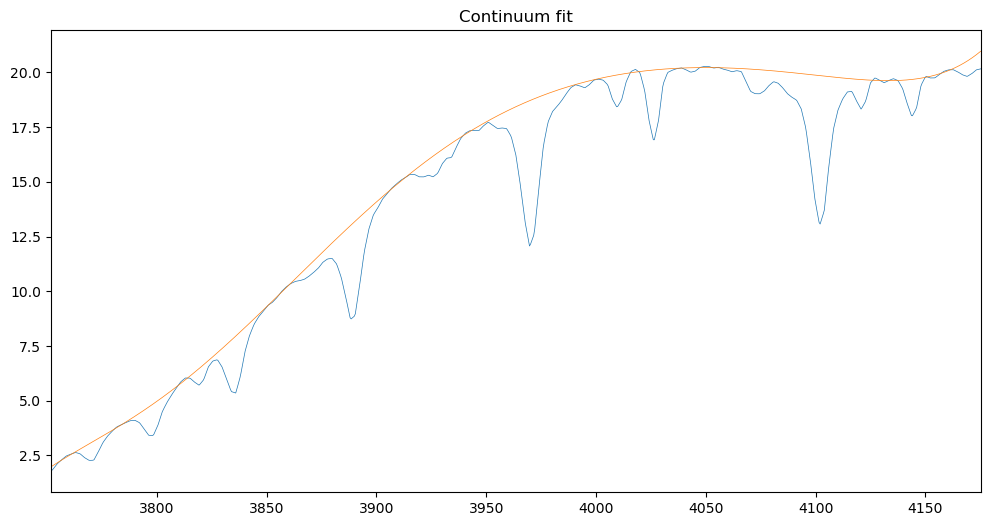

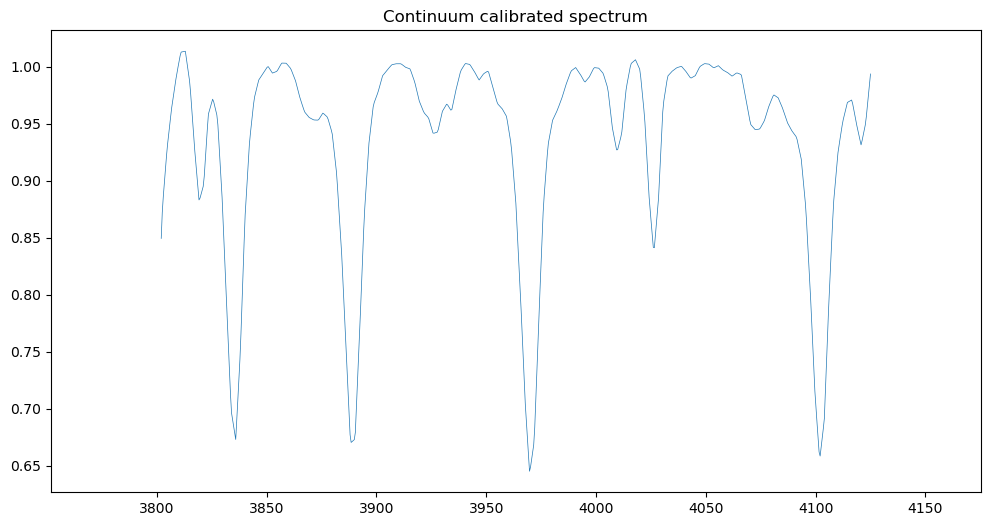

amp = -0.15624087284062724 
mu = 4026.2878235928215 
sigma = 2.619530710609046 
offset = 1.0 
chi2 =  0.000228432097987111


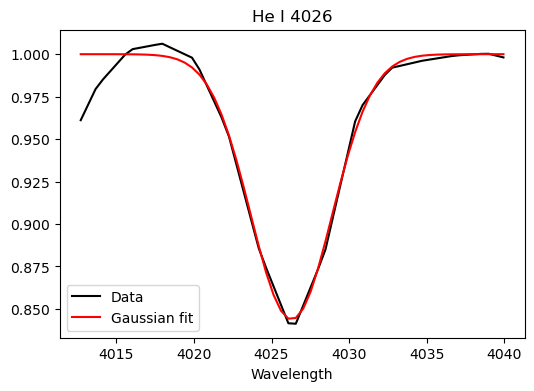

Lambda =  4026.2878235928215 Eq Width = 1.0259072170704824 FWHM =  6.1689948234843035 Intensity =  -0.15624087284062724


### Measuring He I 4388

#### He I 4388 preliminary fit

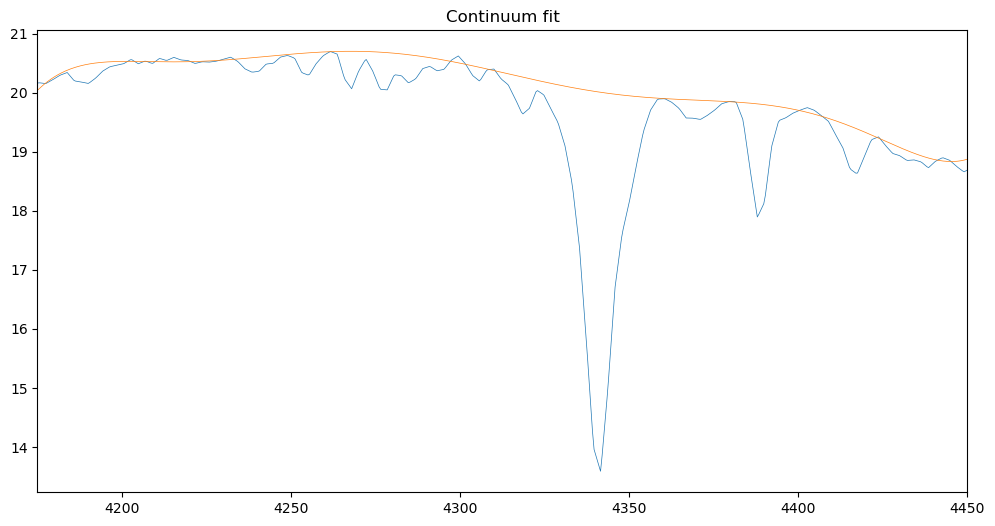

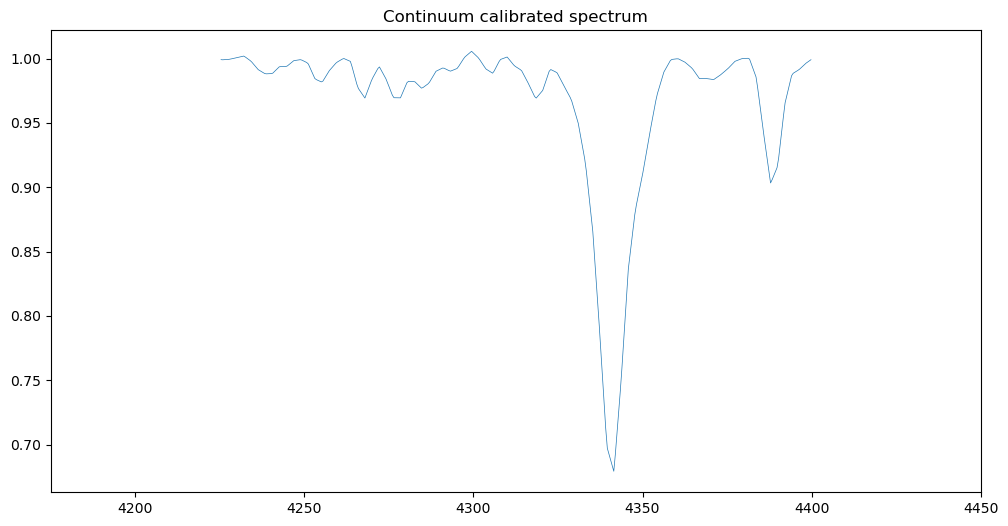

amp = -0.09400799707113316 
mu = 4388.499657857634 
sigma = 2.7128247270987447 
offset = 1.0 
chi2 =  0.00012740977469101664


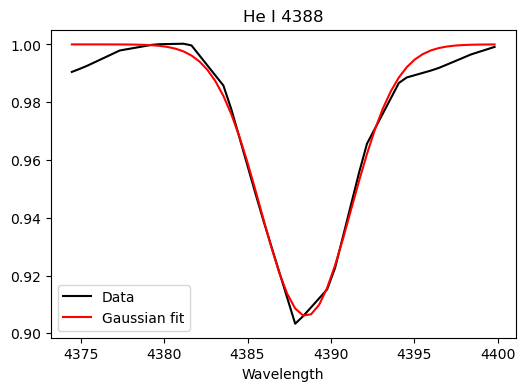

Lambda =  4388.499657857634 Eq Width = 0.6392584379449006 FWHM =  6.388702232317543 Intensity =  -0.09400799707113316


#### He I 4388 optimization

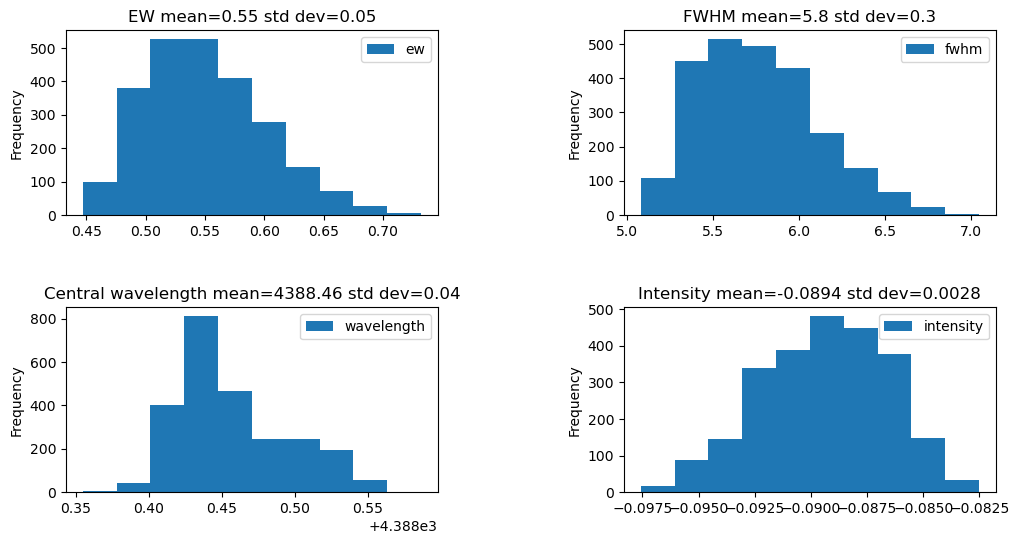

#### He I 4388 re-fit with best parameters

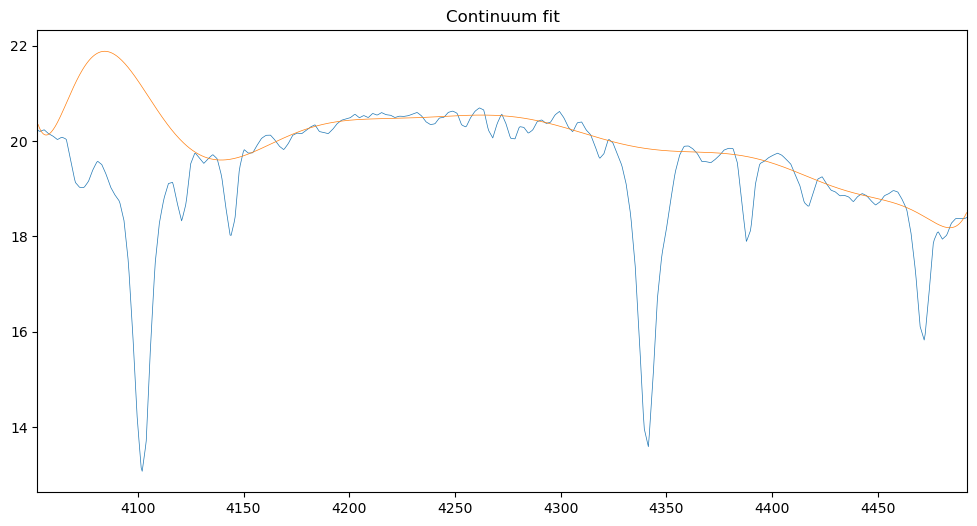

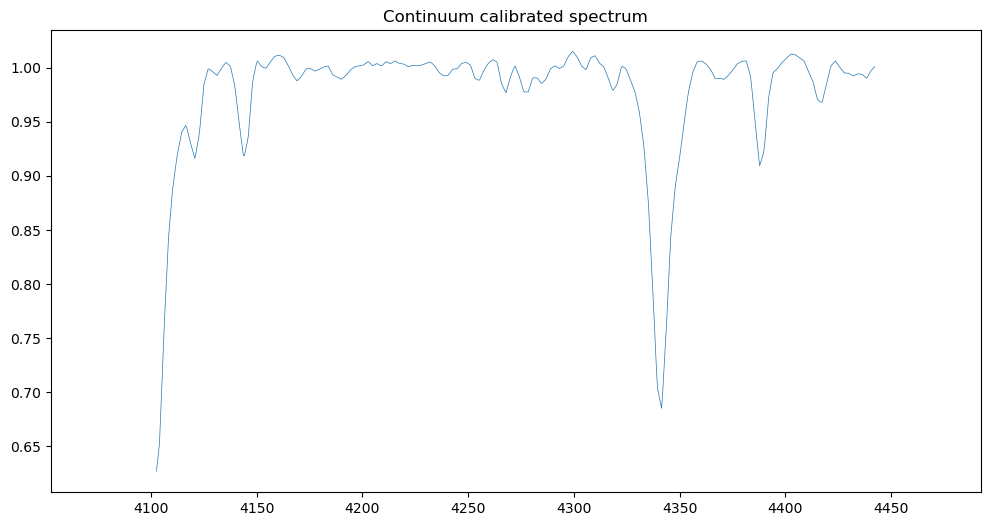

amp = -0.08978173453364527 
mu = 4388.459009144744 
sigma = 2.4448141306981492 
offset = 1.0 
chi2 =  0.00011467931796621681


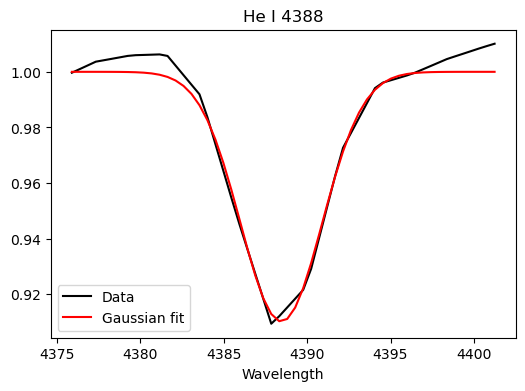

Lambda =  4388.459009144744 Eq Width = 0.5502040371493743 FWHM =  5.757537277794142 Intensity =  -0.08978173453364527


### Measuring He I 4922

#### He I 4922 preliminary fit

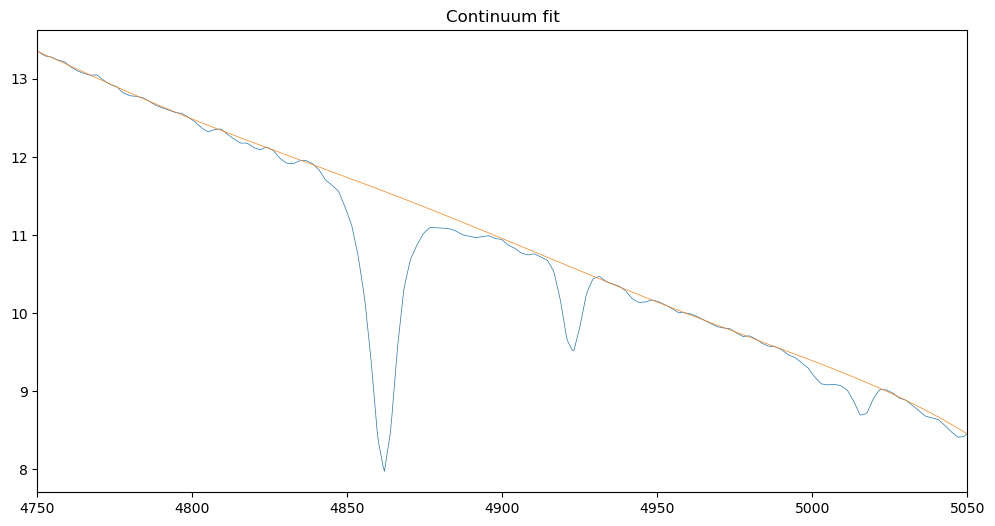

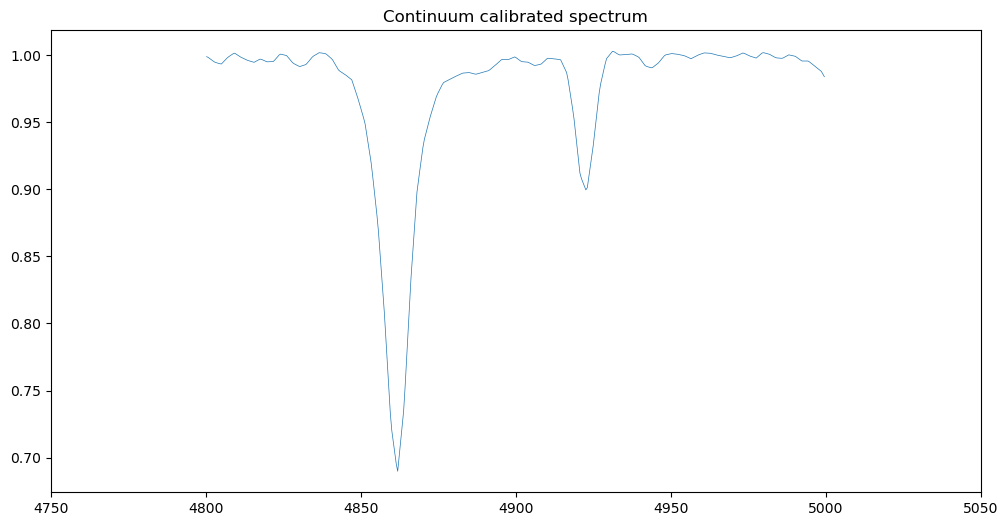

amp = -0.09985712755858073 
mu = 4922.3212425938 
sigma = 2.942278294670085 
offset = 1.0 
chi2 =  5.052437198075499e-05


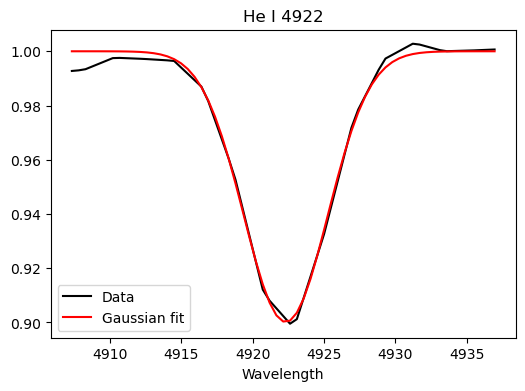

Lambda =  4922.3212425938 Eq Width = 0.7364660839860655 FWHM =  6.929065383948051 Intensity =  -0.09985712755858073


#### He I 4922 optimization

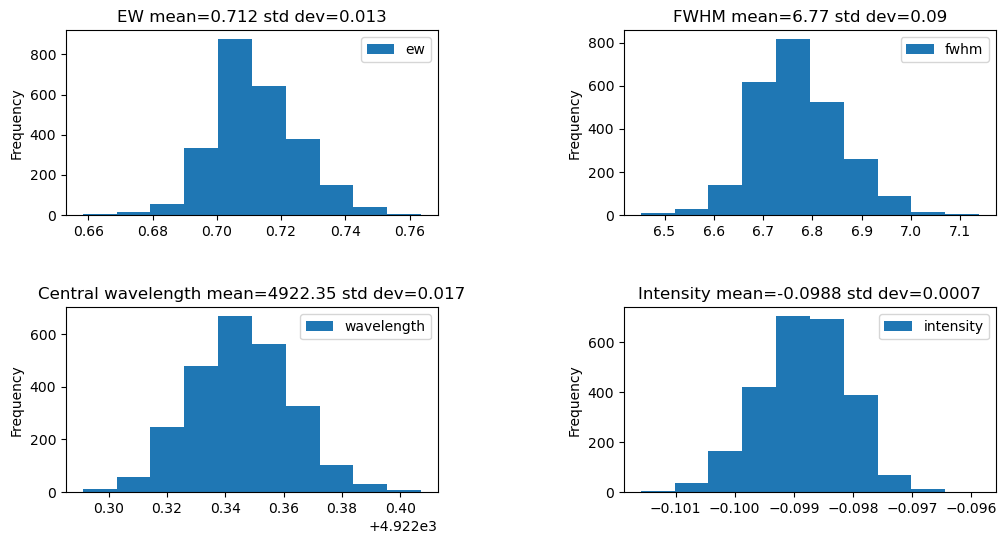

#### He I 4922 re-fit with best parameters

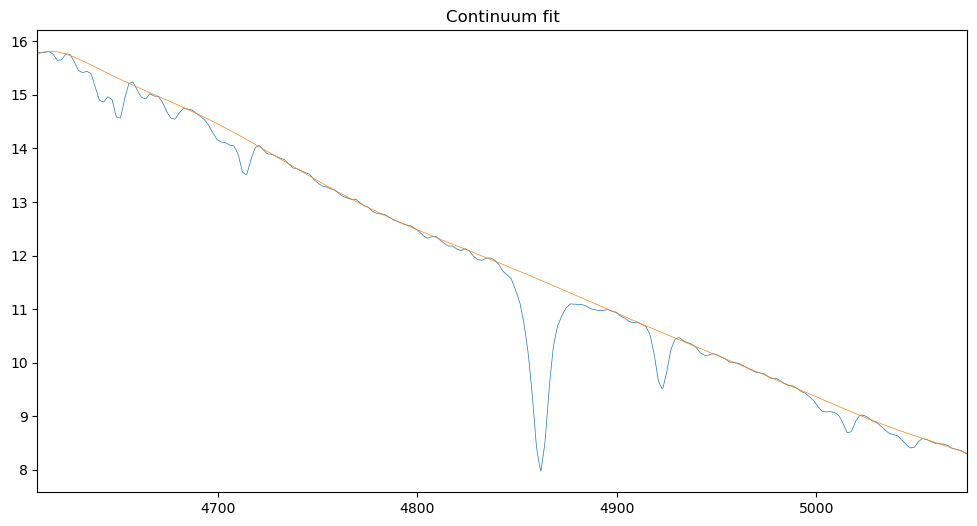

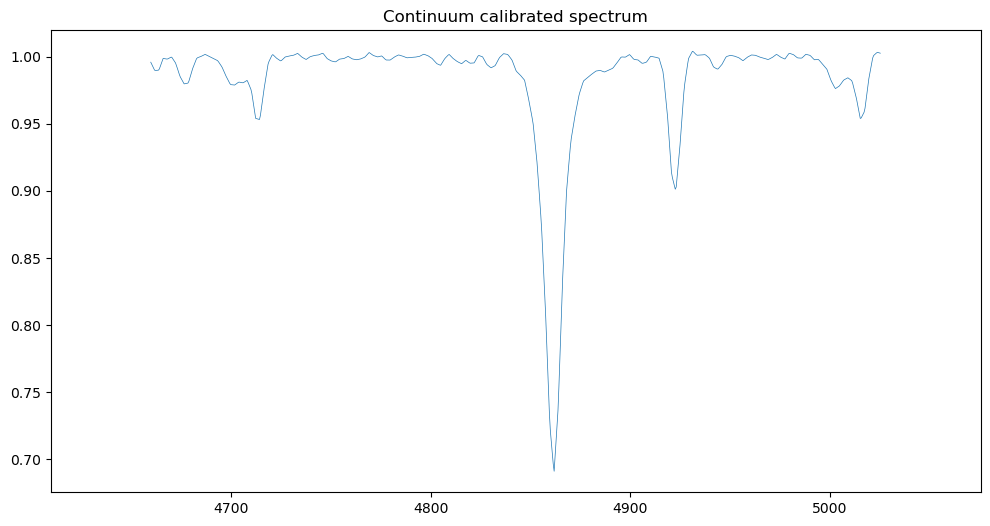

amp = -0.09864466584831806 
mu = 4922.340174143693 
sigma = 2.866578389804176 
offset = 1.0 
chi2 =  5.364882500933765e-05


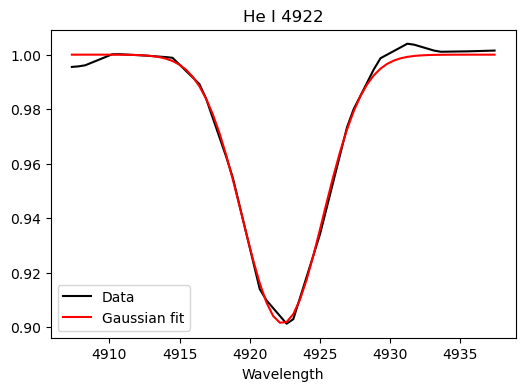

Lambda =  4922.340174143693 Eq Width = 0.7088059633732096 FWHM =  6.7507921079888344 Intensity =  -0.09864466584831806


### Measuring He I 6678

#### He I 6678 preliminary fit

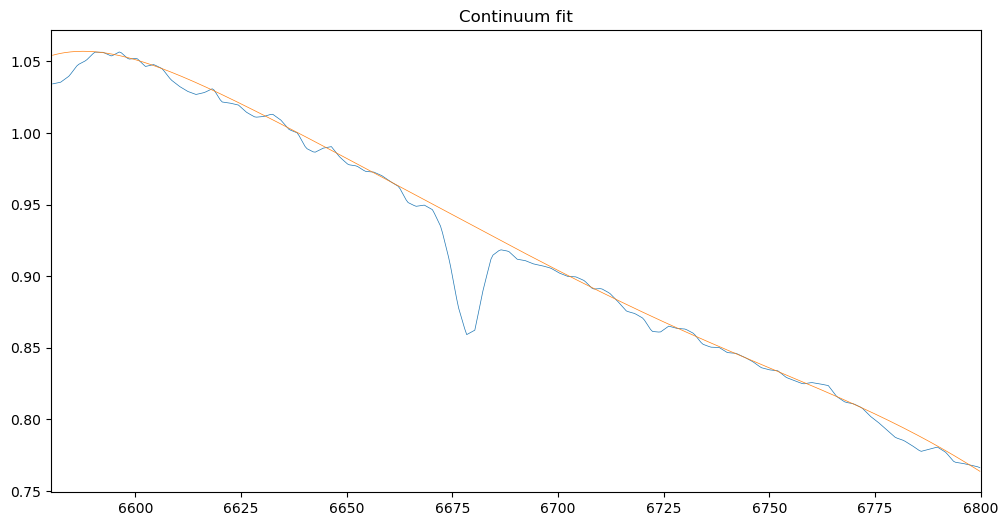

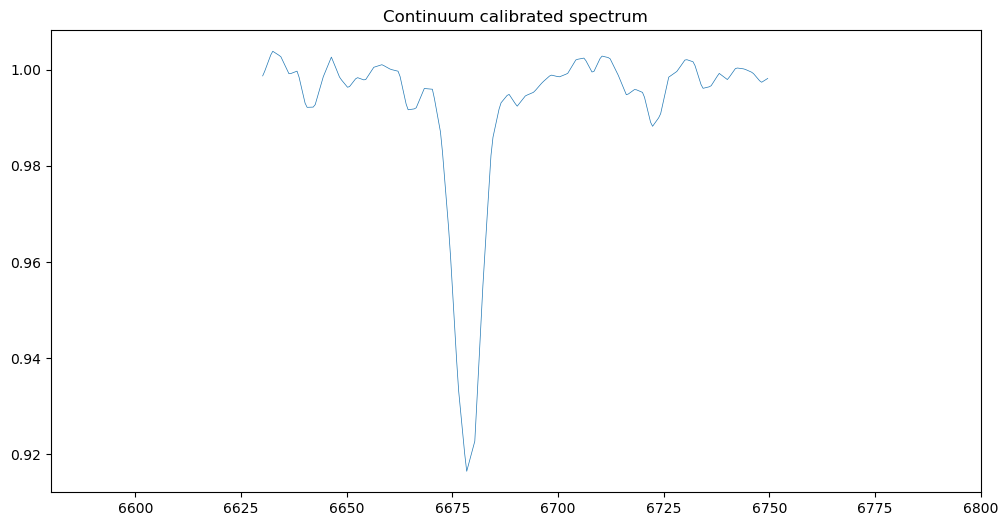

amp = -0.08243951140965655 
mu = 6678.6439102151 
sigma = 3.3548774053222004 
offset = 1.0 
chi2 =  8.51587064631515e-05


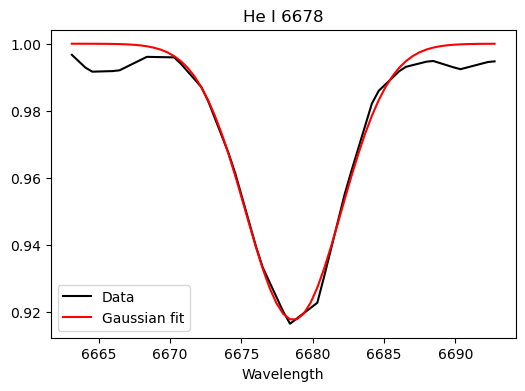

Lambda =  6678.6439102151 Eq Width = 0.6932693467730657 FWHM =  7.900736289533782 Intensity =  -0.08243951140965655


#### He I 6678 optimization

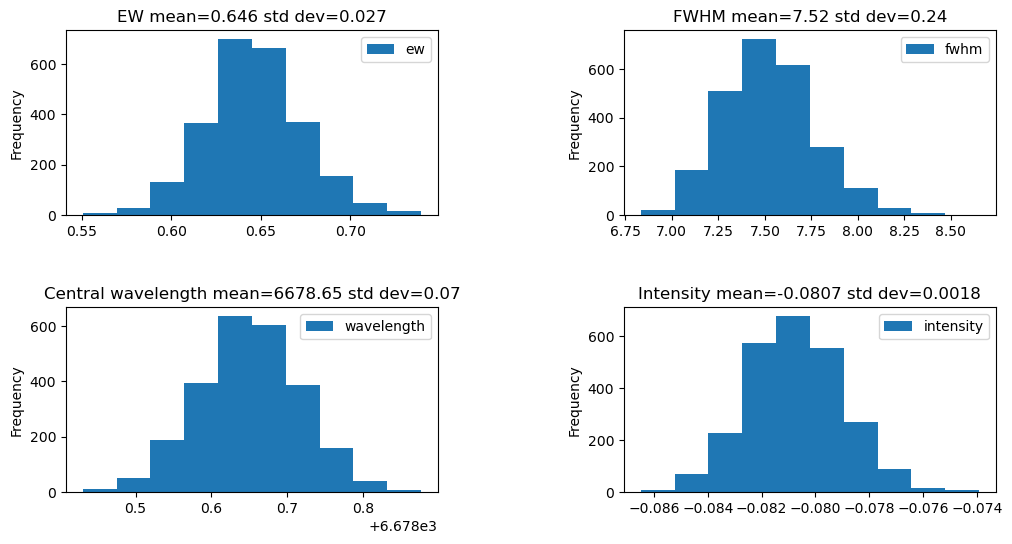

#### He I 6678 re-fit with best parameters

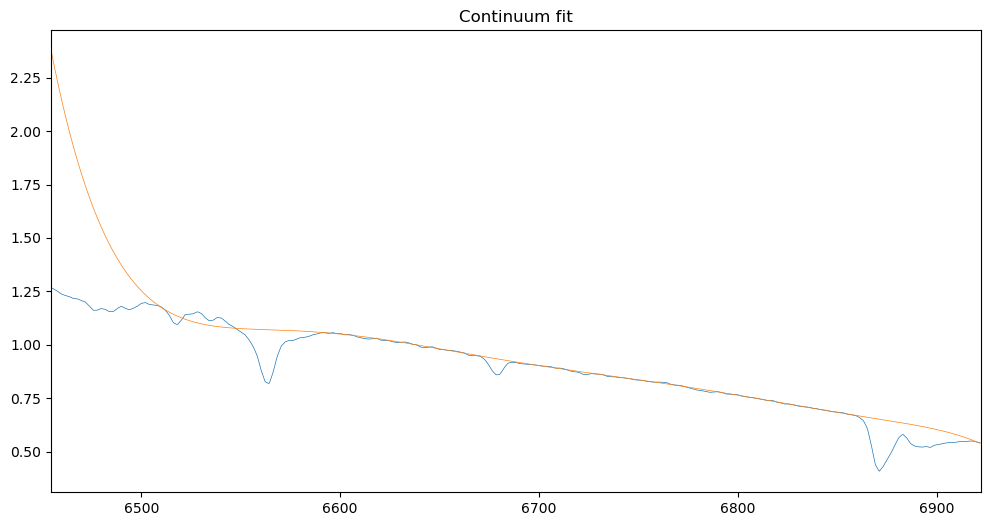

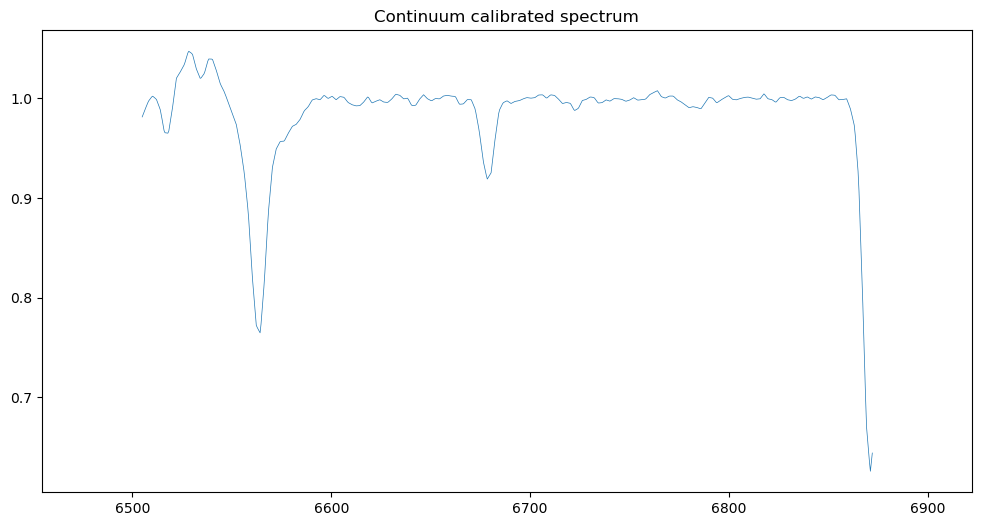

amp = -0.08078177018723702 
mu = 6678.648404823453 
sigma = 3.197952623969896 
offset = 1.0 
chi2 =  7.029763242367846e-05


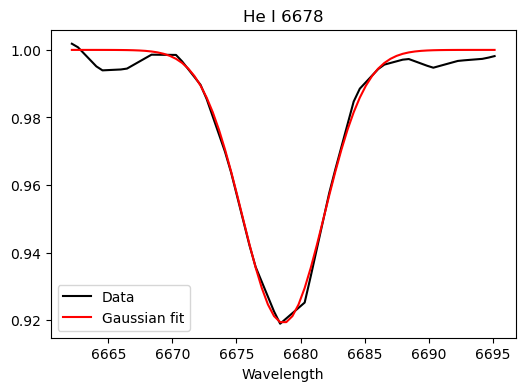

Lambda =  6678.648404823453 Eq Width = 0.6475530086188378 FWHM =  7.531178429449105 Intensity =  -0.08078177018723702


In [31]:
summary_results = pd.DataFrame(columns=("line_name","wavelength","delta_wavelength","ew","delta_ew","fwhm","delta_fwhm","intensity","delta_intensity"))

i = 0

for measuring_line in measuring_lines:
    results = measure_line(wl, flux, measuring_line, show_param_dependencies=SHOW_PARAM_DEPENDENCIES)
    summary_results.loc[i] = results
    i = i + 1

## Measure All Blends

### Measuring He I/Mg II 4471-81

Blended lines= [{'name': 'He I 4471', 'wavelength': 4471.0}, {'name': 'Mg II 4481', 'wavelength': 4481.0}, {'name': 'Unknown 4490', 'wavelength': 4490.0}]


#### He I/Mg II 4471-81 preliminary fit

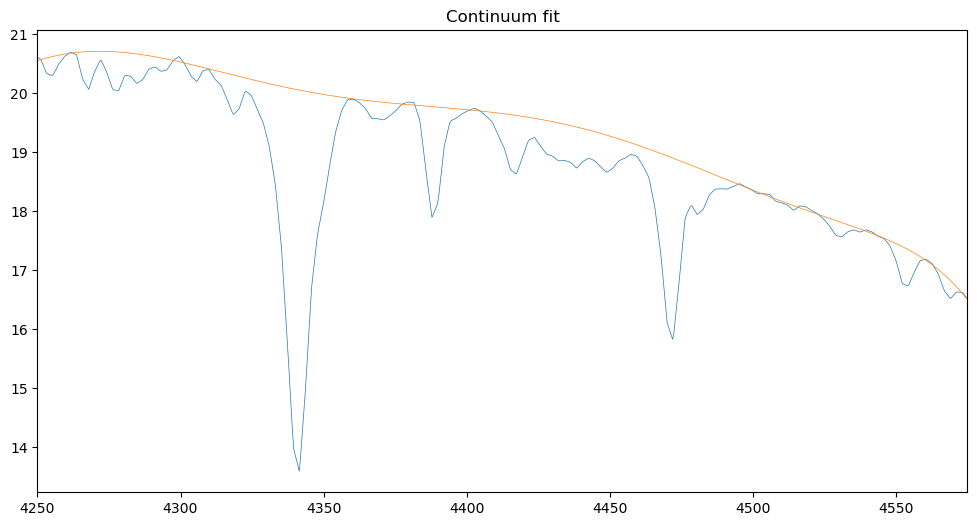

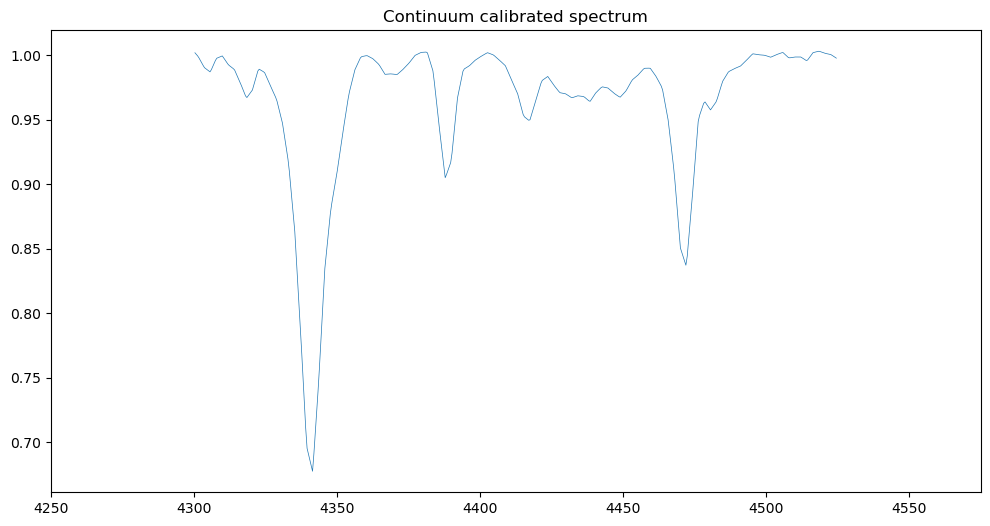

Fit window = (4445.3, 4515.7)
He I 4471 (gauss)
amp = -0.15450733394322452 
mu = 4471.230248504763 
sigma = 3.636004348337122 
offset = 1.0 
chi2 = 0.01790326608569018


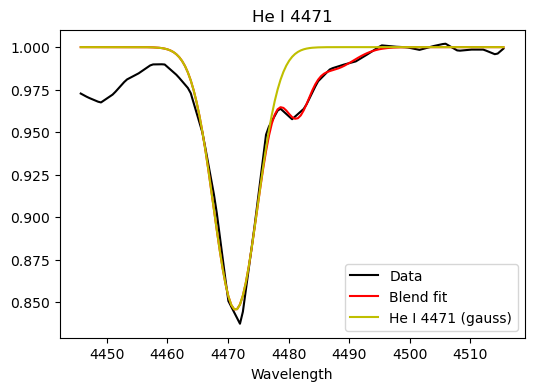

Mg II 4481 (gauss)
amp = -0.0348762123729498 
mu = 4481.321973883892 
sigma = 2.0623069198085817 
offset = 1.0 
chi2 = 0.01790326608569018


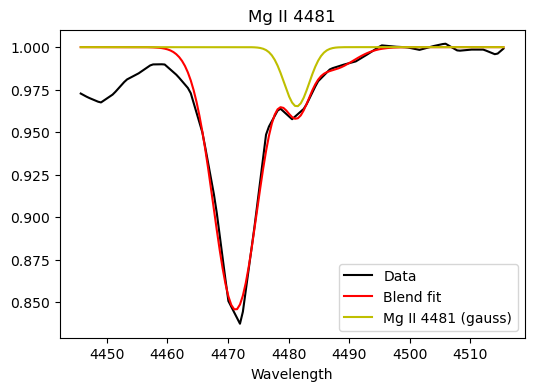

Unknown 4490 (gauss)
amp = -0.013037886822325895 
mu = 4487.000000256654 
sigma = 3.6786121455094904 
offset = 1.0 
chi2 = 0.01790326608569018


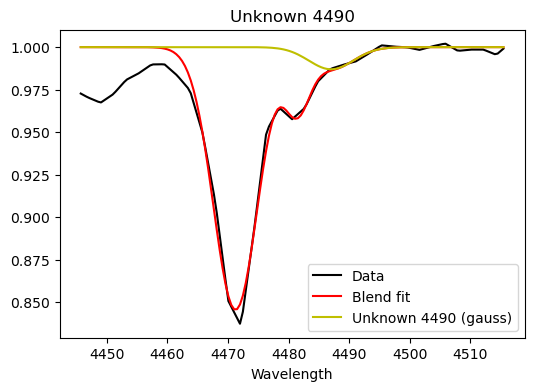

#### He I/Mg II 4471-81 optimization

#### Plotting results for He I 4471

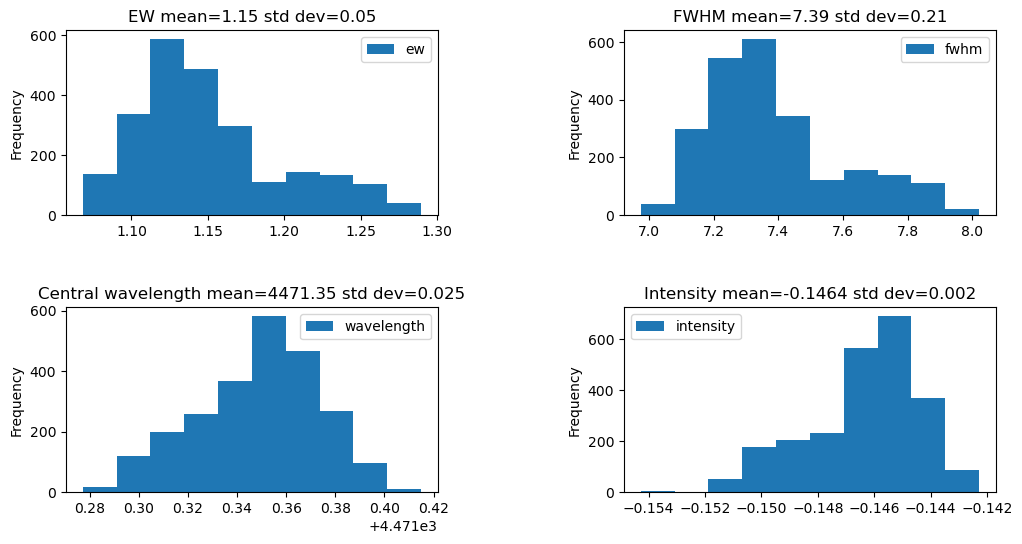

#### Plotting results for Mg II 4481

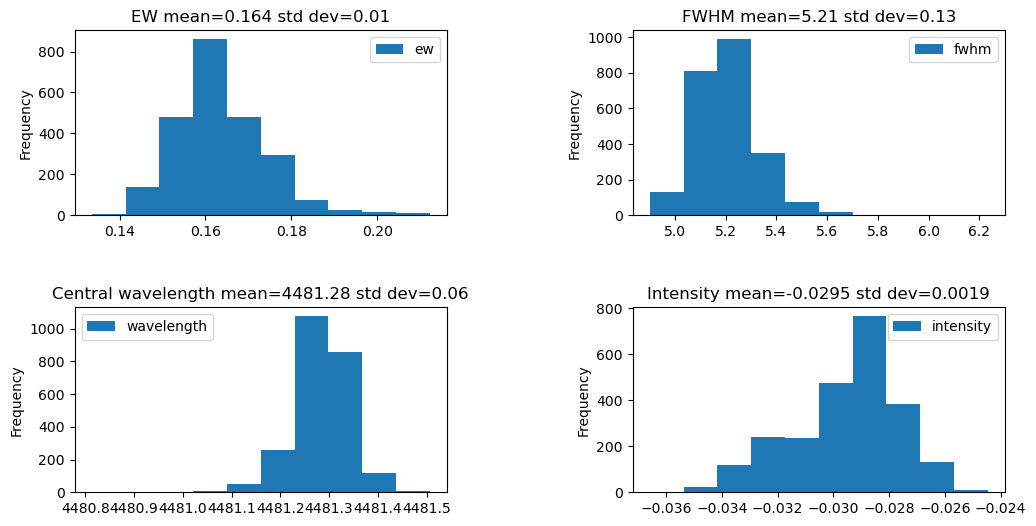

#### Plotting results for Unknown 4490

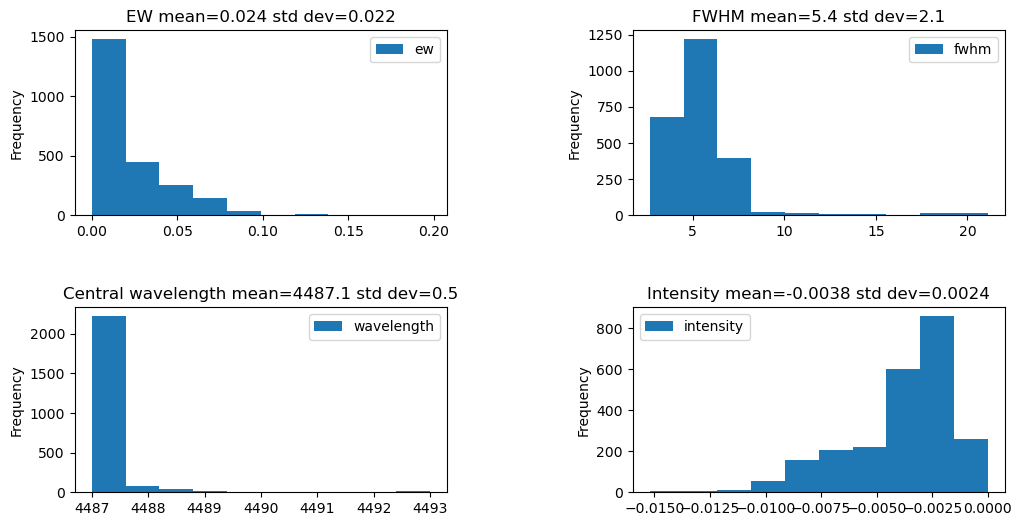

#### He I/Mg II 4471-81 re-fit with best parameters

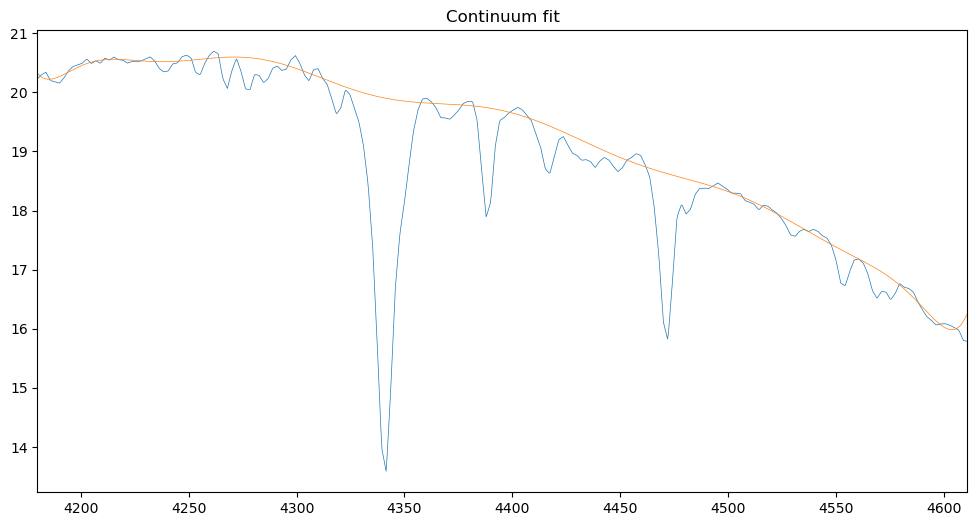

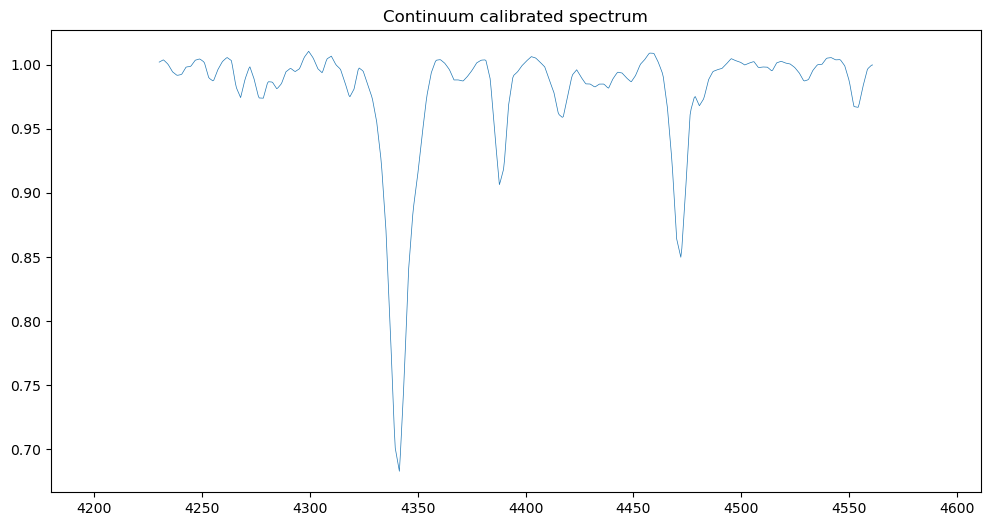

He I 4471 (gauss)
amp = -0.14651511455708738 
mu = 4471.350982778548 
sigma = 3.1442994253670618 
offset = 1.0 
chi2 = 0.0028920213694196106


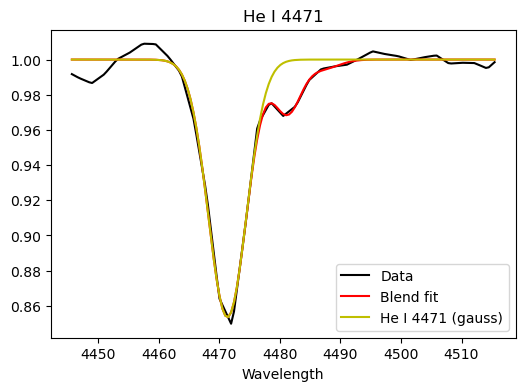

Mg II 4481 (gauss)
amp = -0.030046956067800765 
mu = 4481.239308484064 
sigma = 2.1855308078140117 
offset = 1.0 
chi2 = 0.0028920213694196106


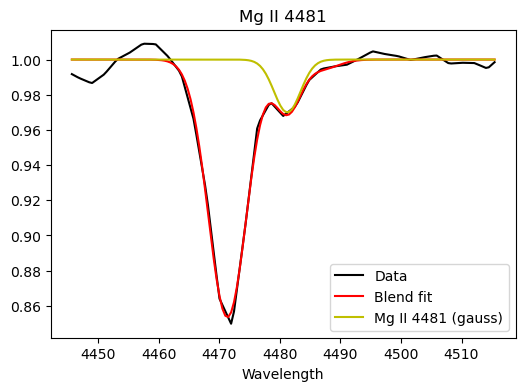

Unknown 4490 (gauss)
amp = -0.005252736006358429 
mu = 4487.000000763273 
sigma = 2.697917561788439 
offset = 1.0 
chi2 = 0.0028920213694196106


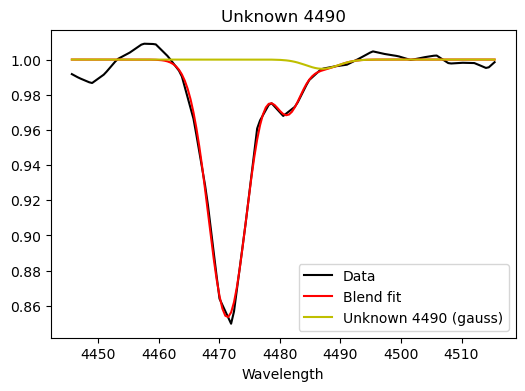

### Measuring He I 4713

Blended lines= [{'name': 'O II 4699', 'wavelength': 4699.0}, {'name': 'O II 4705', 'wavelength': 4705.0}, {'name': 'He I 4713', 'wavelength': 4713.0}]


#### He I 4713 preliminary fit

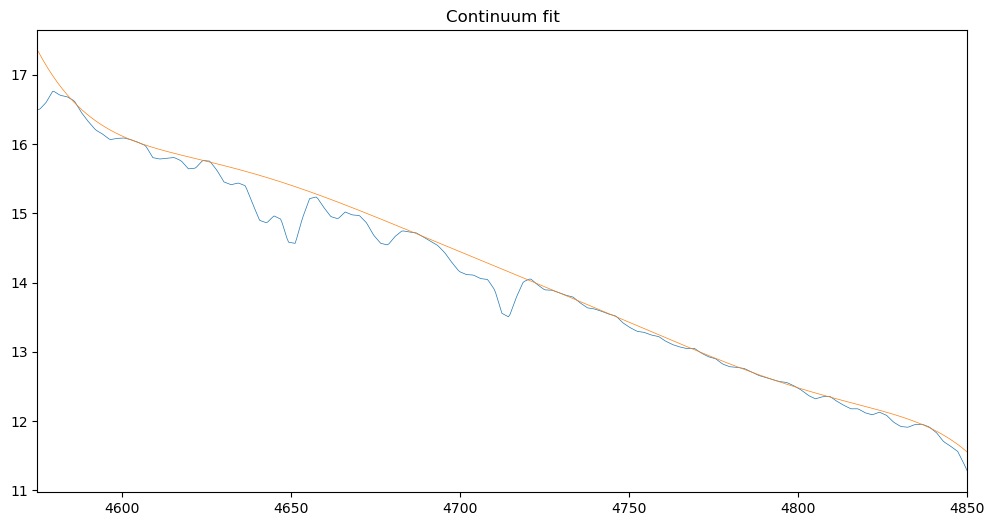

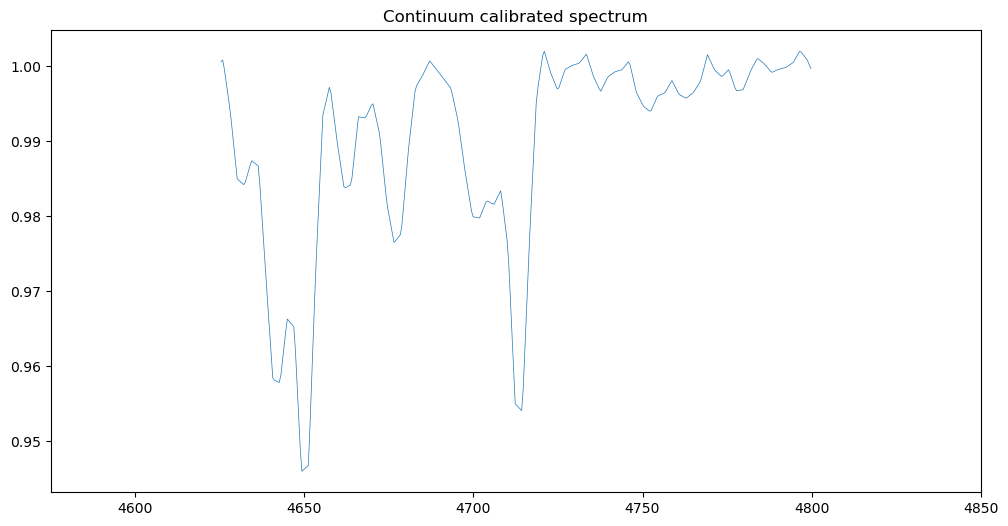

Fit window = (4671.6, 4740.4)
O II 4699 (gauss)
amp = -0.01993013236388111 
mu = 4700.755317119897 
sigma = 3.8767629219369697 
offset = 1.0 
chi2 = 0.006974345707211995


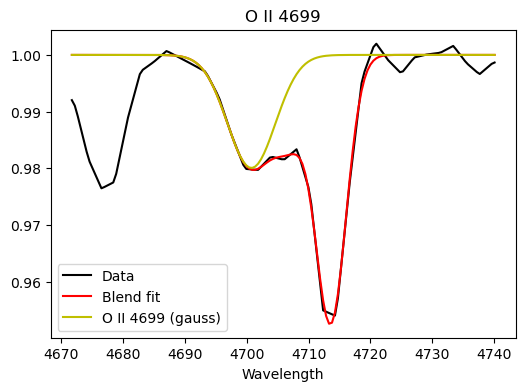

O II 4705 (gauss)
amp = -0.010651835578702685 
mu = 4707.231950641922 
sigma = 2.4231151531634905 
offset = 1.0 
chi2 = 0.006974345707211995


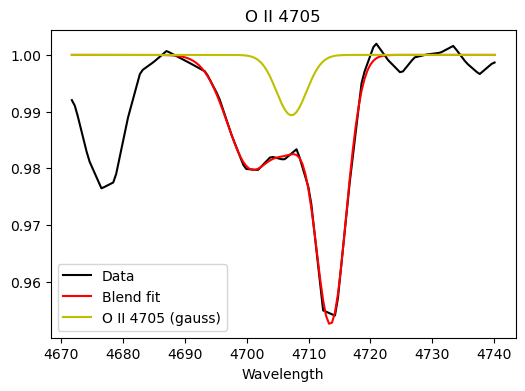

He I 4713 (gauss)
amp = -0.047044977244948896 
mu = 4713.5503616350115 
sigma = 2.5003258897255556 
offset = 1.0 
chi2 = 0.006974345707211995


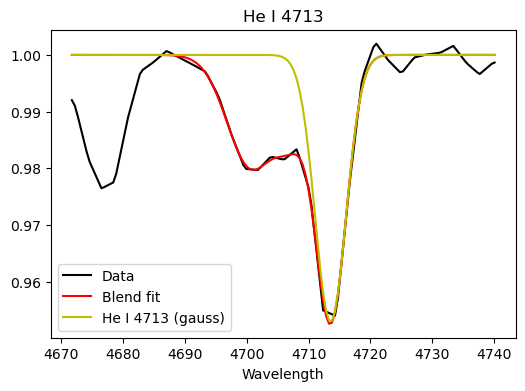

#### He I 4713 optimization

#### Plotting results for O II 4699

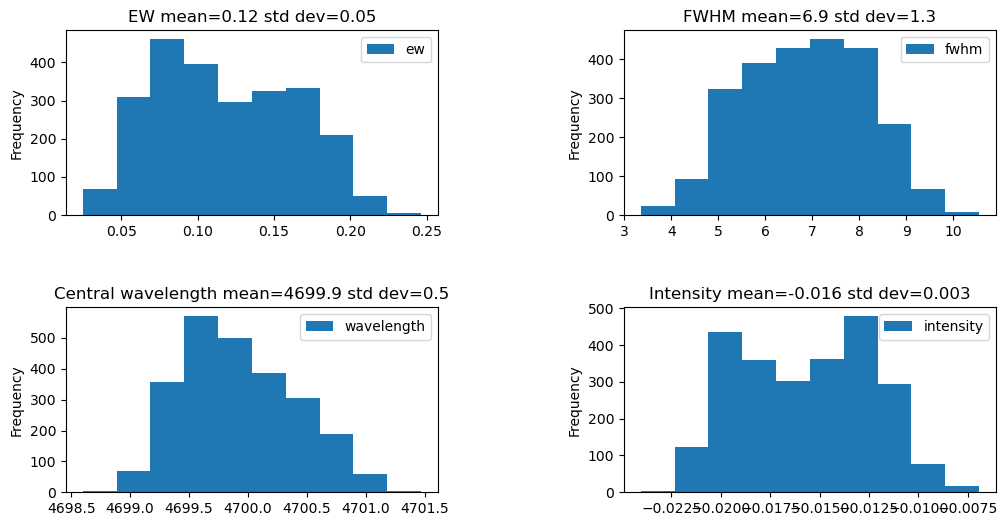

#### Plotting results for O II 4705

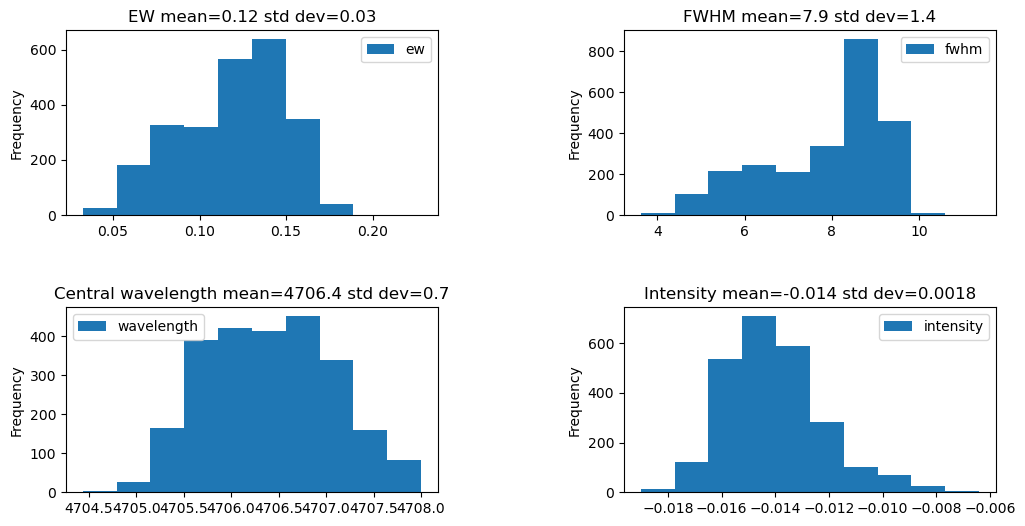

#### Plotting results for He I 4713

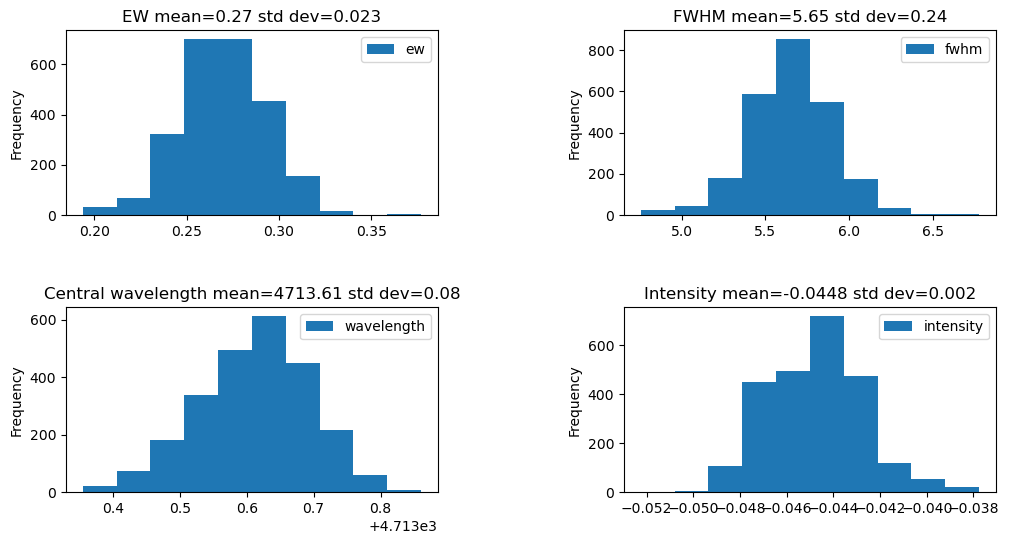

#### He I 4713 re-fit with best parameters

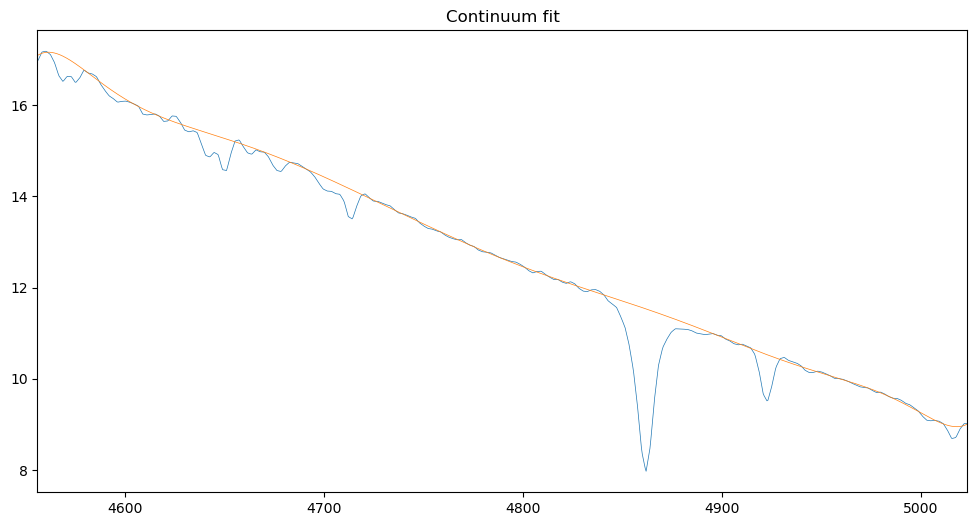

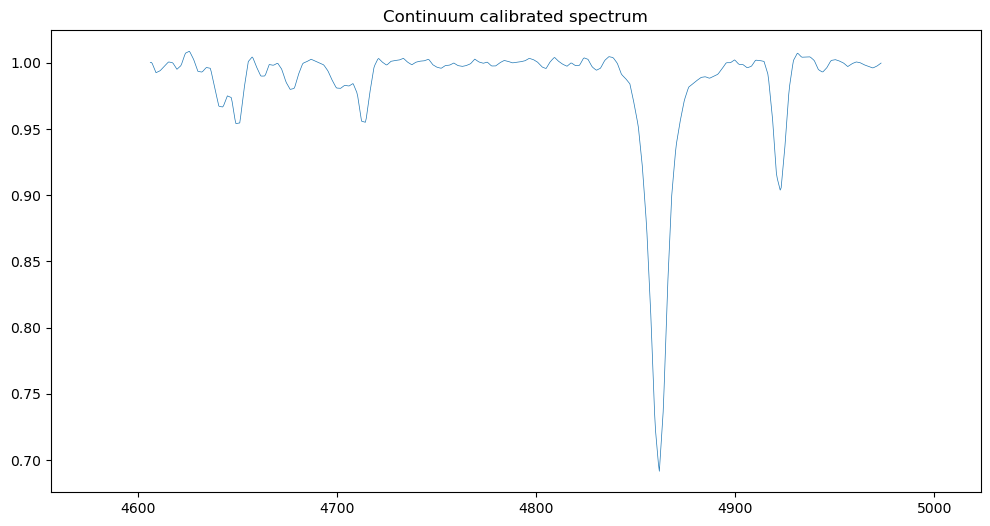

O II 4699 (gauss)
amp = -0.015610992466813904 
mu = 4699.661880463364 
sigma = 2.990966925611445 
offset = 1.0 
chi2 = 0.004705508565095167


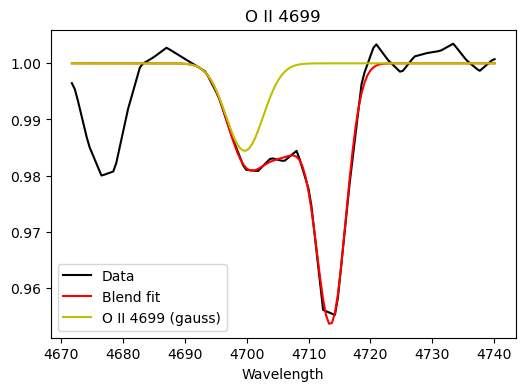

O II 4705 (gauss)
amp = -0.014989119705902679 
mu = 4706.469502716569 
sigma = 3.694775721067384 
offset = 1.0 
chi2 = 0.004705508565095167


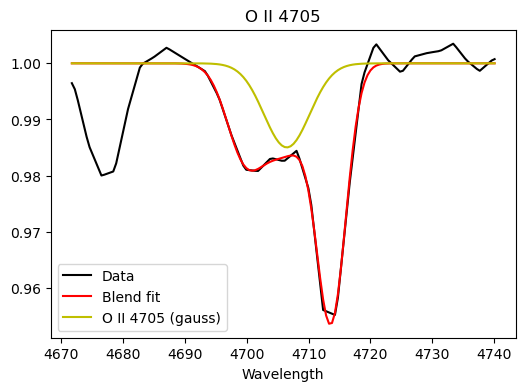

He I 4713 (gauss)
amp = -0.0442129104599062 
mu = 4713.66533940104 
sigma = 2.3692130856974676 
offset = 1.0 
chi2 = 0.004705508565095167


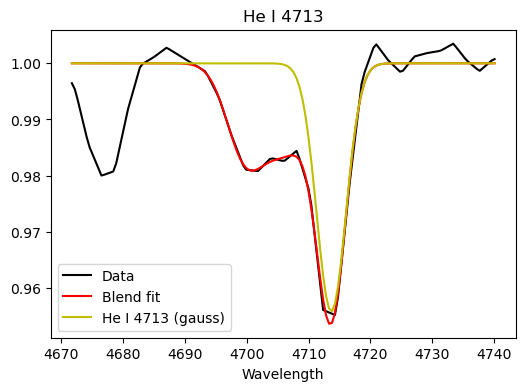

### Measuring H delta / He I 4121-4144

Blended lines= [{'name': 'O II 4072', 'wavelength': 4072.0}, {'name': 'O II 4076', 'wavelength': 4076.0}, {'name': 'O II 4089', 'wavelength': 4089.0}, {'name': 'H delta', 'wavelength': 4101.0, 'model': 'voigt'}, {'name': 'He I 4121', 'wavelength': 4121.0}, {'name': 'O II 4133', 'wavelength': 4133.0}, {'name': 'He I 4144', 'wavelength': 4144.0}, {'name': 'Unknown 4153', 'wavelength': 4153.0}]


#### H delta / He I 4121-4144 preliminary fit

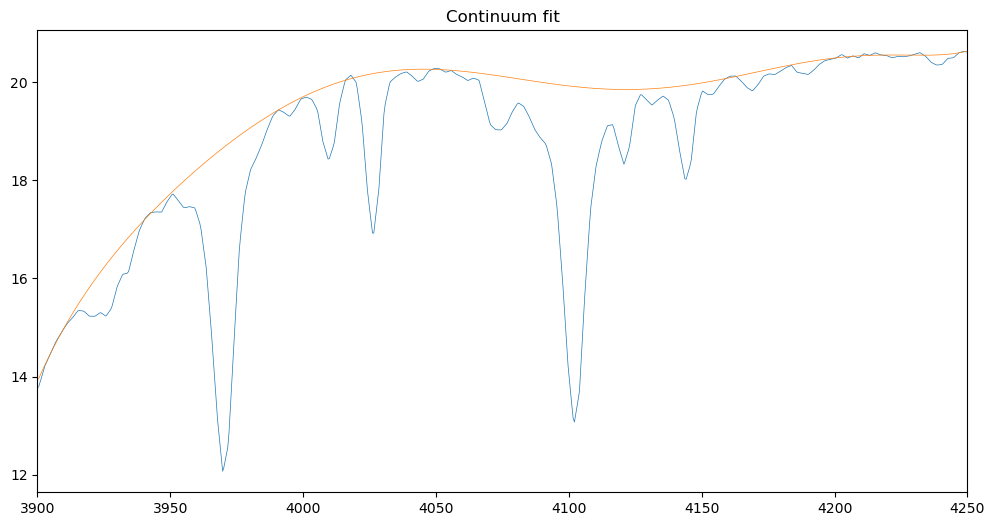

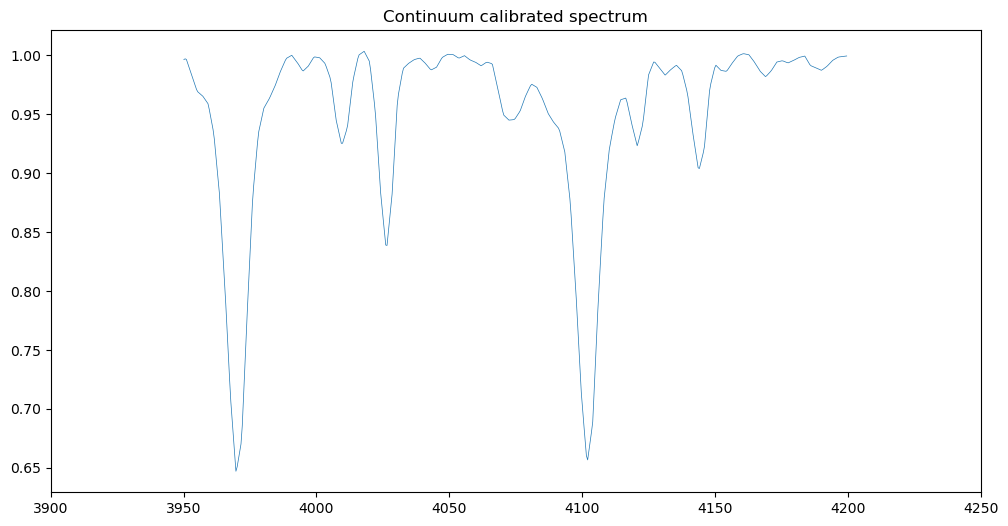

Fit window = (3970.8, 4200.0)
O II 4072 (gauss)
amp = -0.020810531771252153 
mu = 4070.200113642379 
sigma = 1.856396628711074 
offset = 1.0 
chi2 = 1.0503900428910569


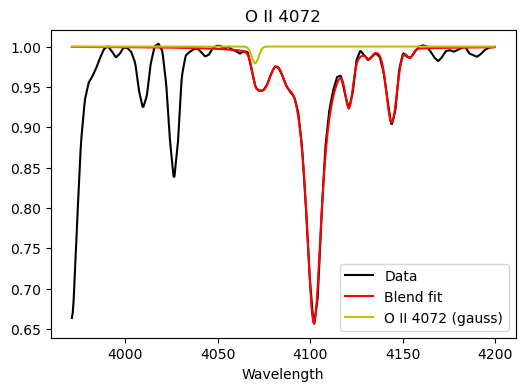

O II 4076 (gauss)
amp = -0.04216923506580296 
mu = 4074.511657686129 
sigma = 3.4766472246631204 
offset = 1.0 
chi2 = 1.0503900428910569


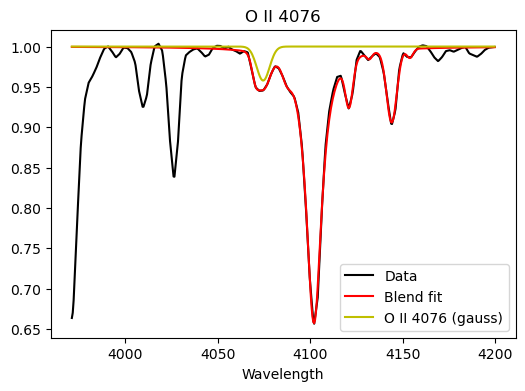

O II 4089 (gauss)
amp = -0.015963549583652946 
mu = 4087.234654410417 
sigma = 2.443515675884507 
offset = 1.0 
chi2 = 1.0503900428910569


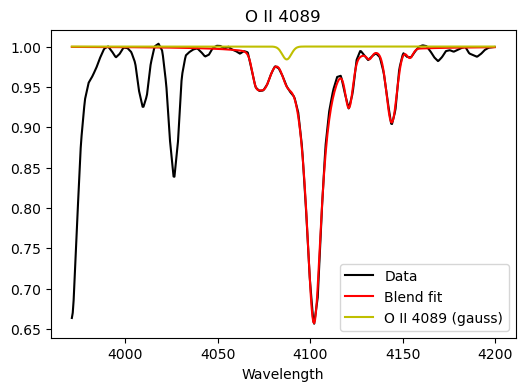

H delta (voigt)
amp = -5.302016298265738 
mu = 4101.963870507664 
sigma = 1.0243536905208426 
gamma = 4.717427396373645 
offset = 1.0 
chi2 = 1.0503900428910569


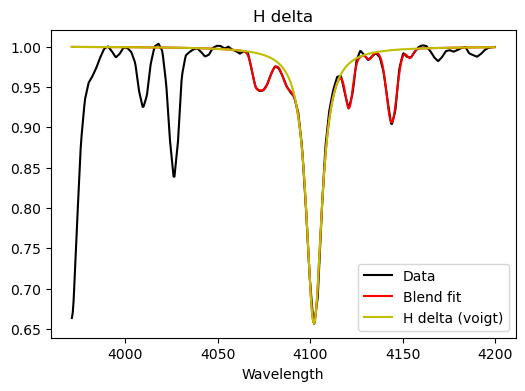

He I 4121 (gauss)
amp = -0.05514676651351103 
mu = 4120.95536919821 
sigma = 2.022041353949556 
offset = 1.0 
chi2 = 1.0503900428910569


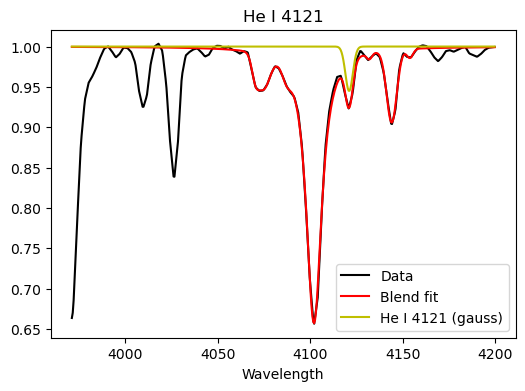

O II 4133 (gauss)
amp = -0.007224898101408829 
mu = 4131.900181715379 
sigma = 1.4089751442729388 
offset = 1.0 
chi2 = 1.0503900428910569


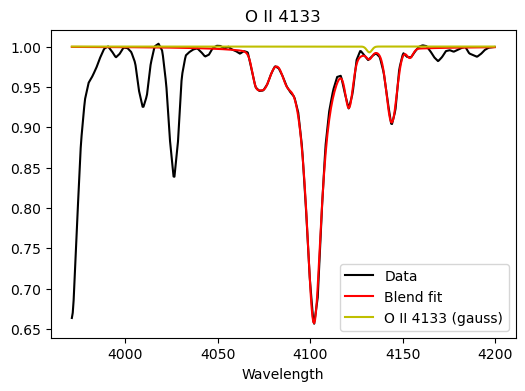

He I 4144 (gauss)
amp = -0.08977097884331112 
mu = 4143.974952636363 
sigma = 2.743815674325228 
offset = 1.0 
chi2 = 1.0503900428910569


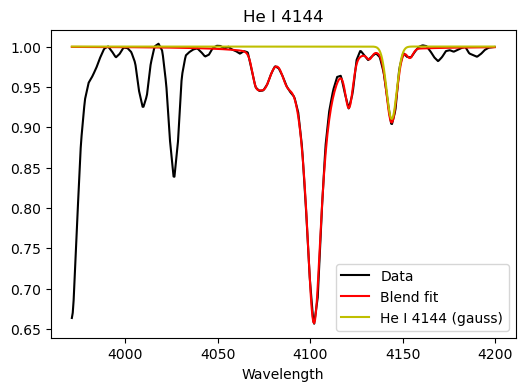

Unknown 4153 (gauss)
amp = -0.011204237873993158 
mu = 4153.7954931703125 
sigma = 1.6741085071864208 
offset = 1.0 
chi2 = 1.0503900428910569


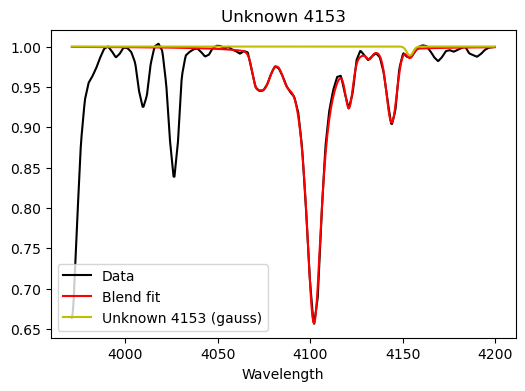

#### H delta / He I 4121-4144 optimization

#### Plotting results for O II 4072

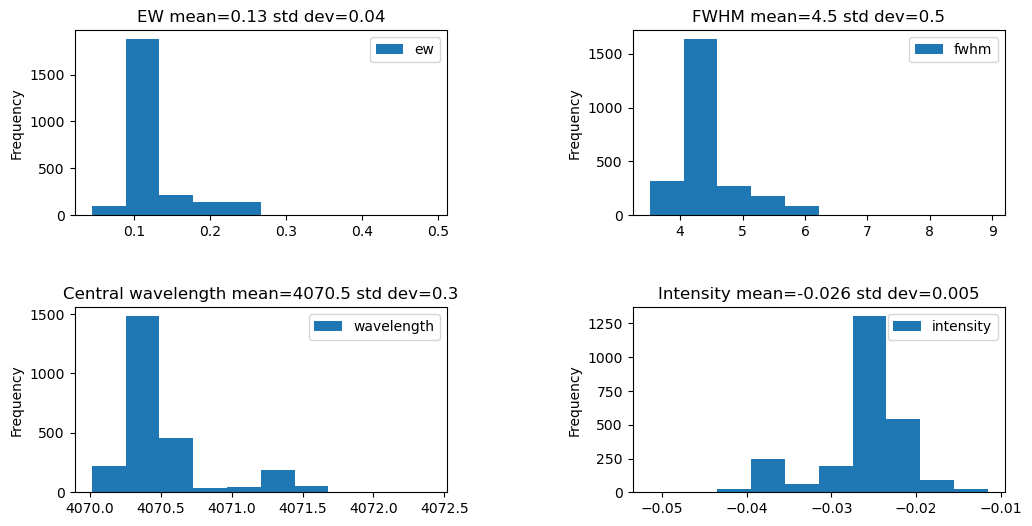

#### Plotting results for O II 4076

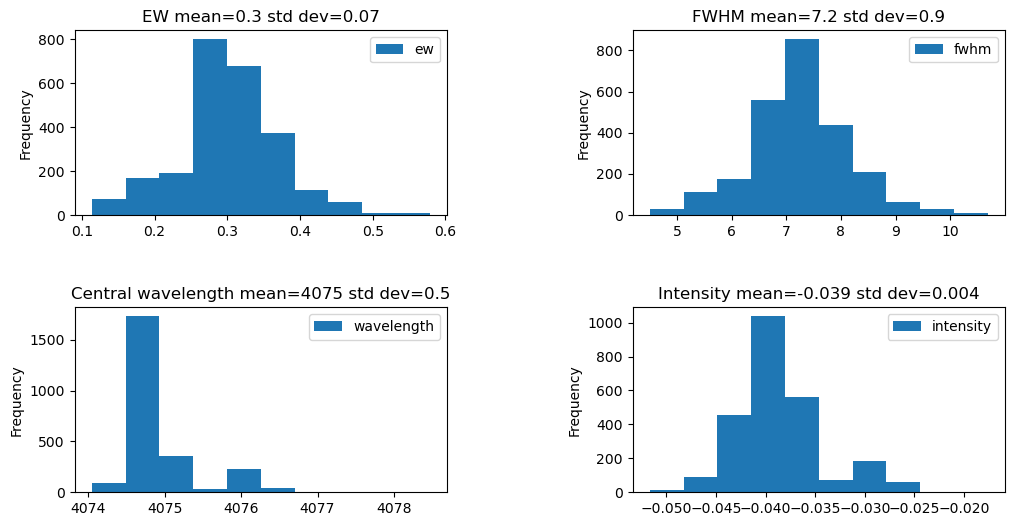

#### Plotting results for O II 4089

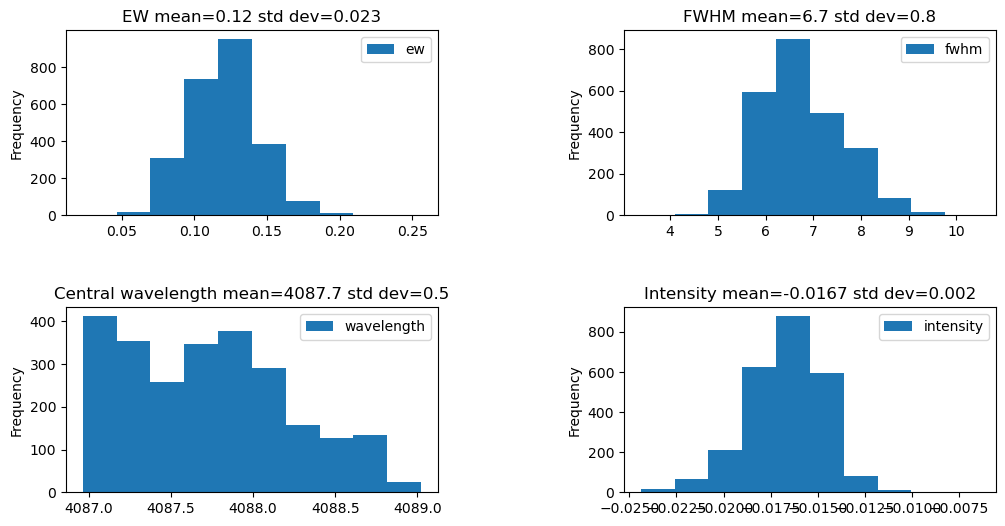

#### Plotting results for H delta

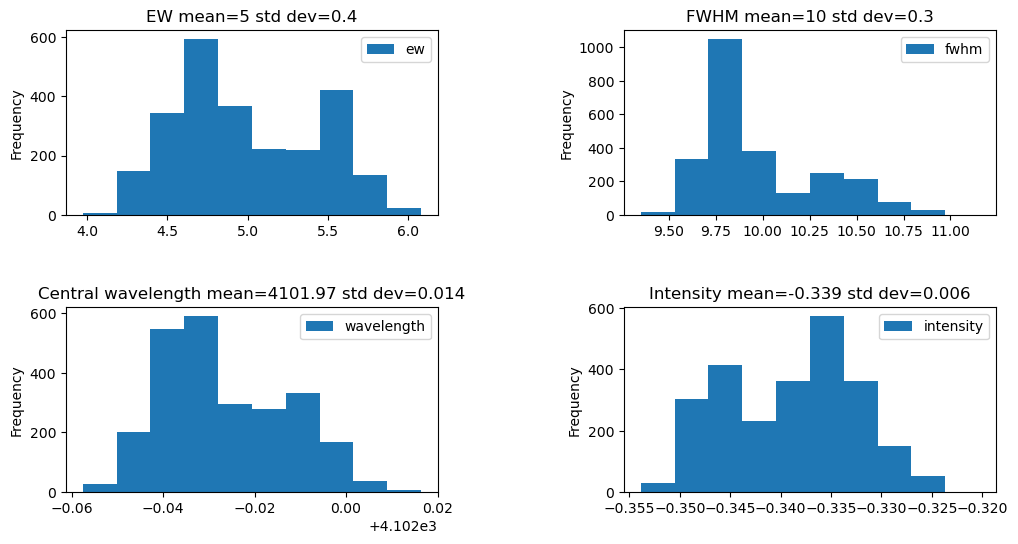

#### Plotting results for He I 4121

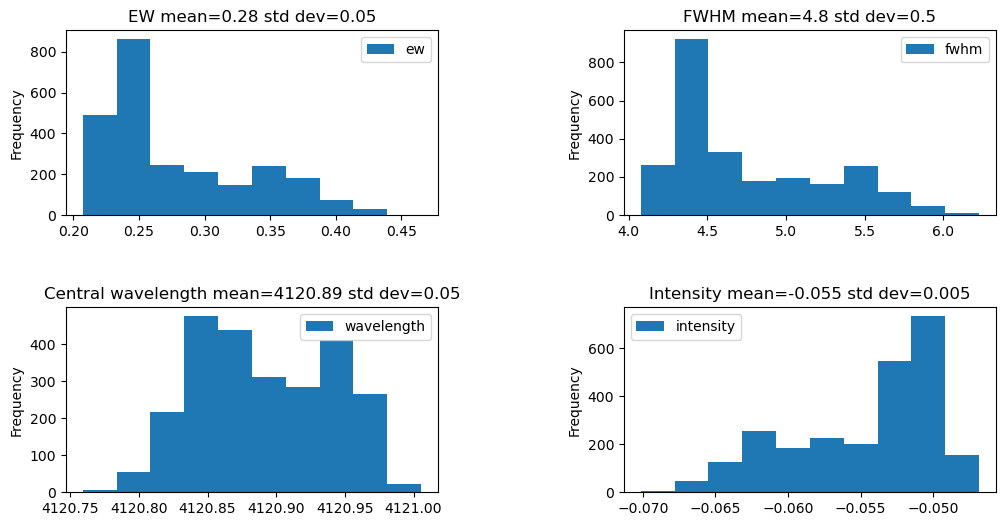

#### Plotting results for O II 4133

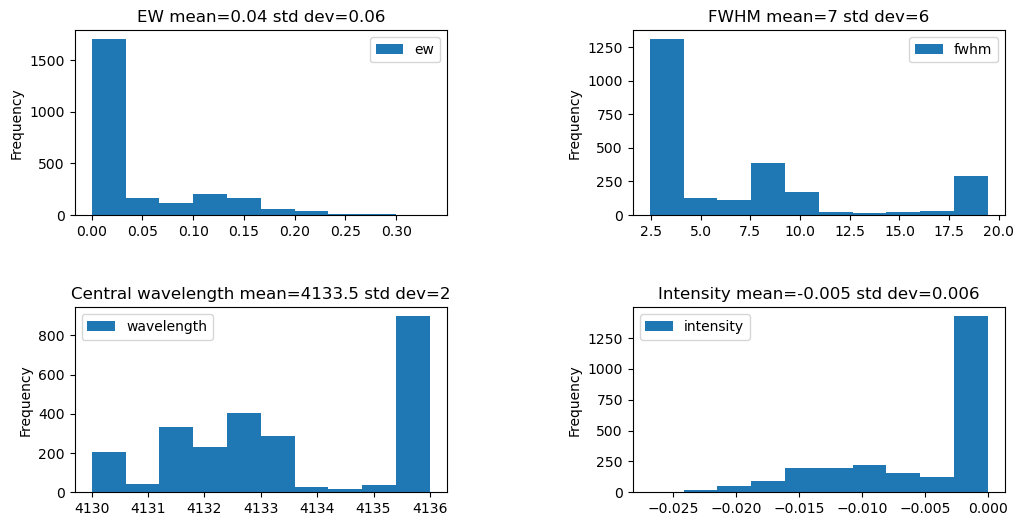

#### Plotting results for He I 4144

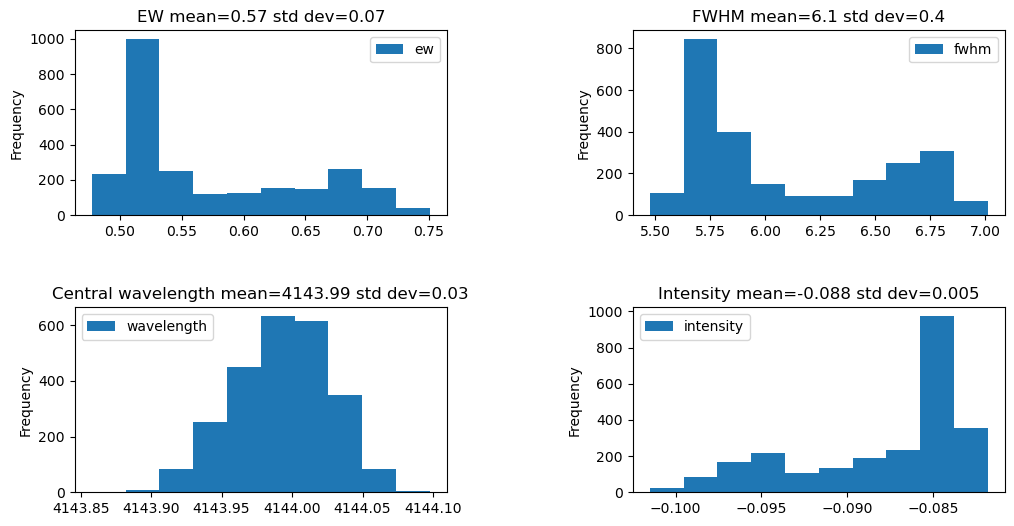

#### Plotting results for Unknown 4153

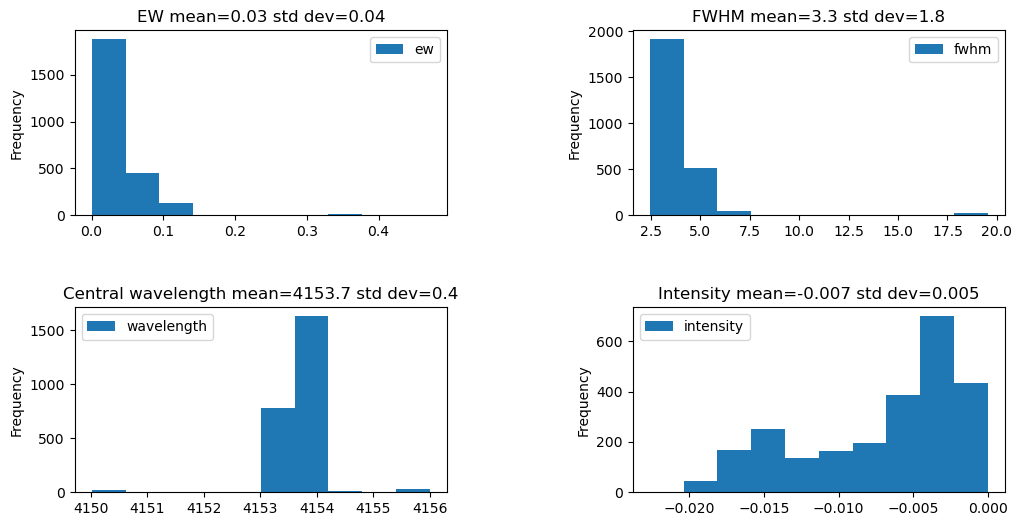

#### H delta / He I 4121-4144 re-fit with best parameters

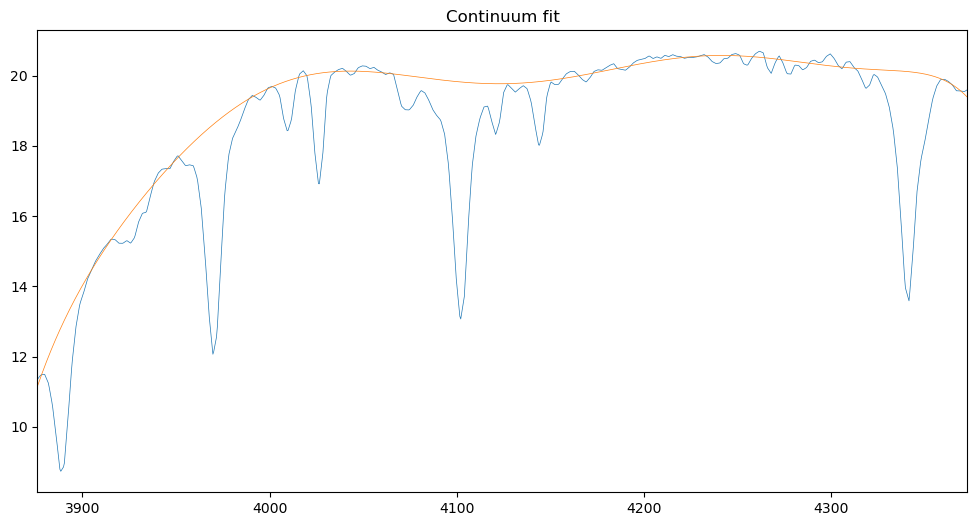

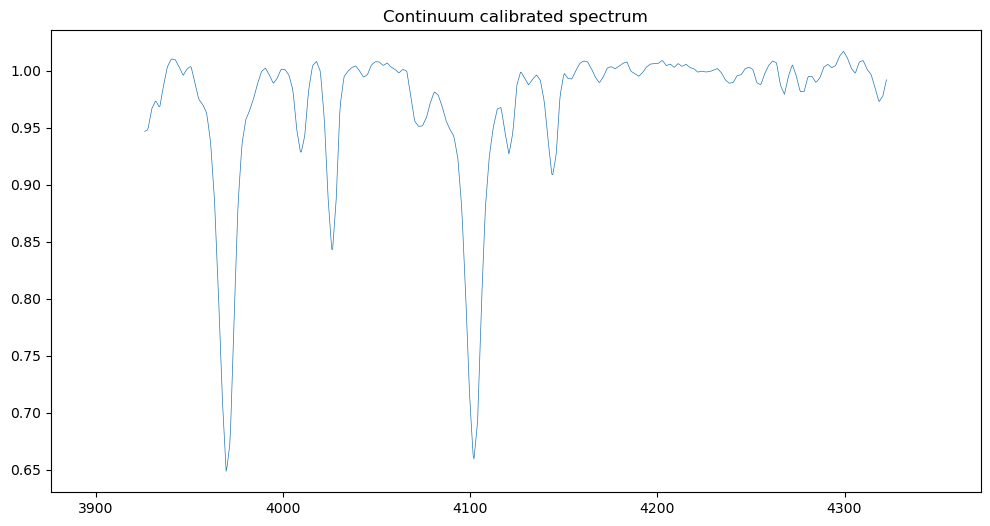

O II 4072 (gauss)
amp = -0.024560652860247 
mu = 4070.464510601159 
sigma = 1.7301829166705849 
offset = 1.0 
chi2 = 1.0126976578349722


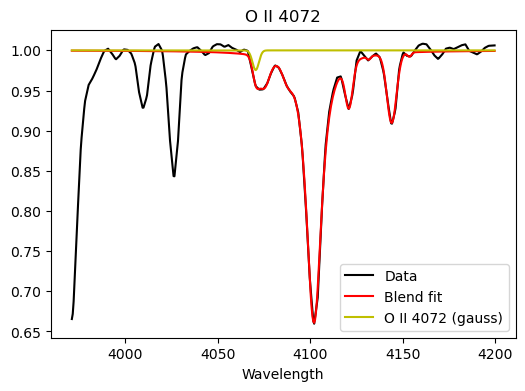

O II 4076 (gauss)
amp = -0.037851735748481115 
mu = 4074.8114500524152 
sigma = 2.97663515397756 
offset = 1.0 
chi2 = 1.0126976578349722


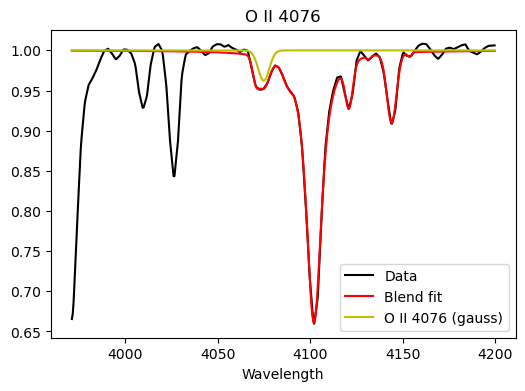

O II 4089 (gauss)
amp = -0.015158353414722537 
mu = 4087.632377567004 
sigma = 2.5450261696658996 
offset = 1.0 
chi2 = 1.0126976578349722


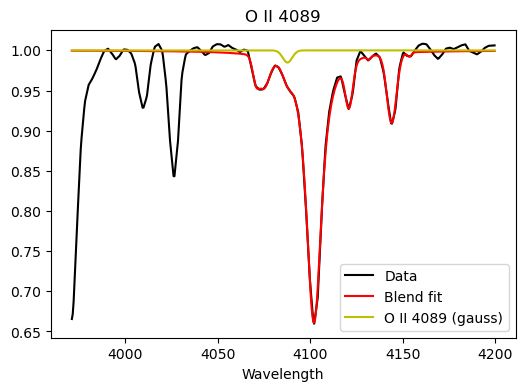

H delta (voigt)
amp = -4.998299712084622 
mu = 4101.974575411851 
sigma = 1.5977462685616108 
gamma = 4.189039969974241 
offset = 1.0 
chi2 = 1.0126976578349722


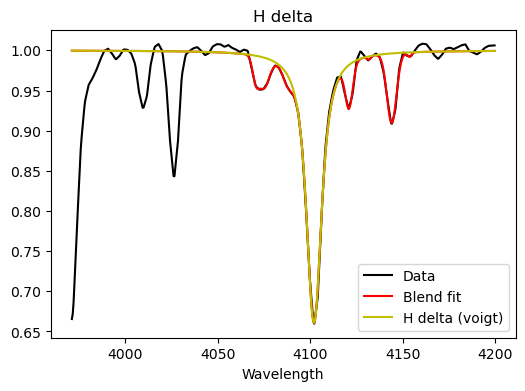

He I 4121 (gauss)
amp = -0.05445998908560698 
mu = 4120.899644191019 
sigma = 1.9995607516338423 
offset = 1.0 
chi2 = 1.0126976578349722


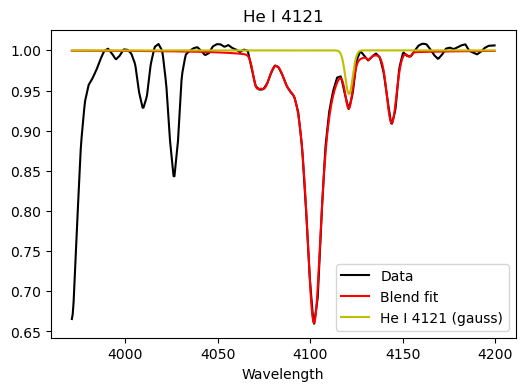

O II 4133 (gauss)
amp = -0.004183134325859055 
mu = 4131.636159879696 
sigma = 1.0323657984684695 
offset = 1.0 
chi2 = 1.0126976578349722


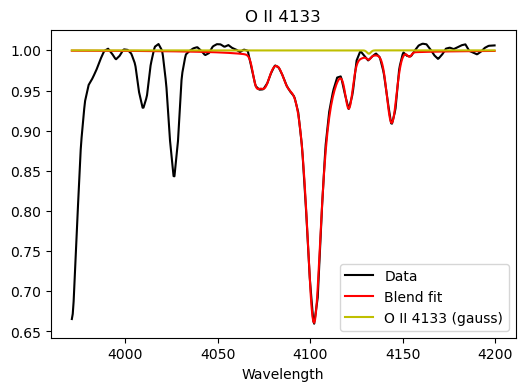

He I 4144 (gauss)
amp = -0.0867663093590132 
mu = 4143.96771494321 
sigma = 2.5781565958510706 
offset = 1.0 
chi2 = 1.0126976578349722


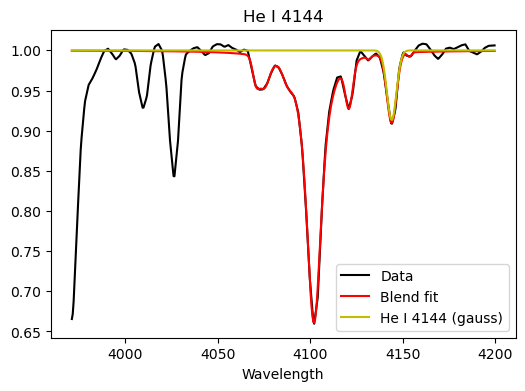

Unknown 4153 (gauss)
amp = -0.00546051443790865 
mu = 4153.555699383741 
sigma = 1.0792208882724492 
offset = 1.0 
chi2 = 1.0126976578349722


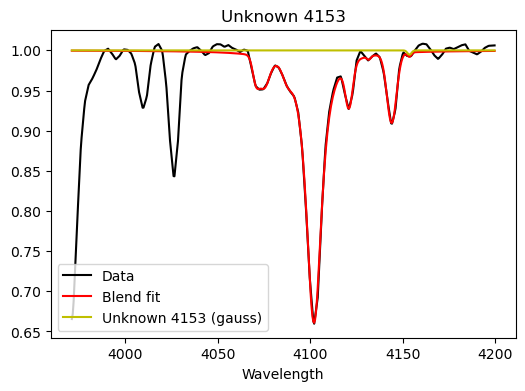

### Measuring H gamma

Blended lines= [{'name': 'O II 4320', 'wavelength': 4320.0}, {'name': 'H gamma', 'wavelength': 4341.0, 'model': 'voigt'}, {'name': 'O II 4349', 'wavelength': 4349.0}, {'name': 'O II 4367', 'wavelength': 4367.0}]


#### H gamma preliminary fit

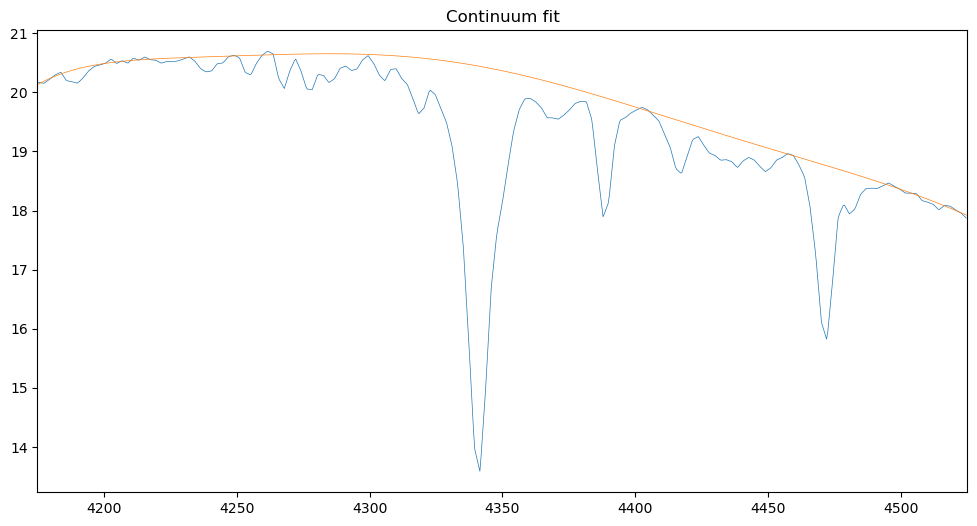

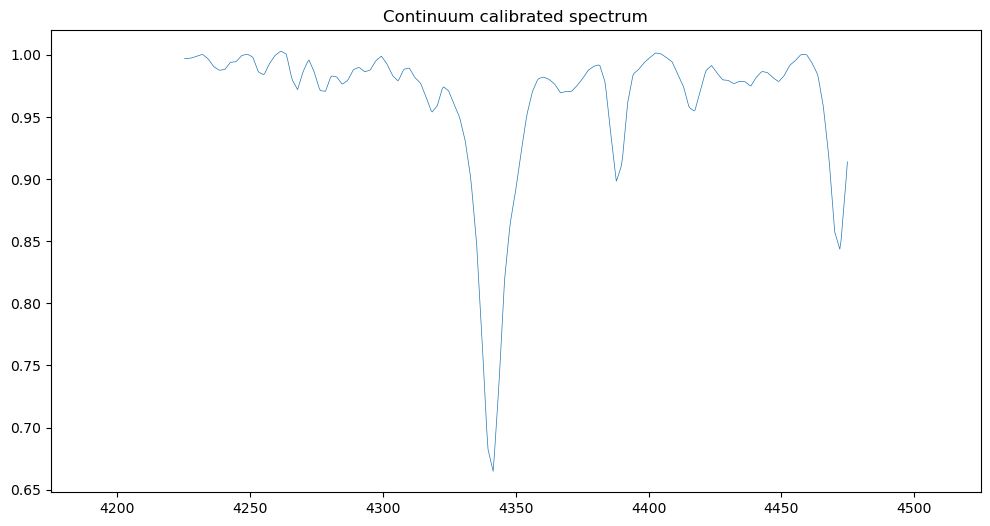

Fit window = (4261.2, 4425.8)
O II 4320 (gauss)
amp = -0.02673238392084355 
mu = 4317.874079288831 
sigma = 2.6491672905123473 
offset = 1.0 
chi2 = 0.1355455006820617


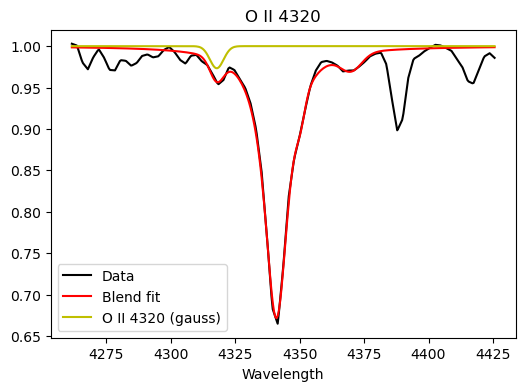

H gamma (voigt)
amp = -5.602034275313792 
mu = 4340.987398583872 
sigma = 1.0843012364181344 
gamma = 5.2189662790951274 
offset = 1.0 
chi2 = 0.1355455006820617


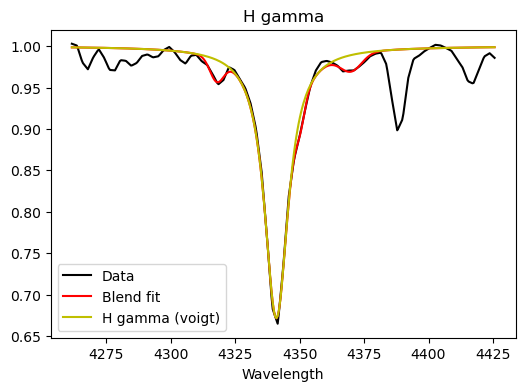

O II 4349 (gauss)
amp = -0.02209642674870814 
mu = 4350.3752608603345 
sigma = 1.8002854966479247 
offset = 1.0 
chi2 = 0.1355455006820617


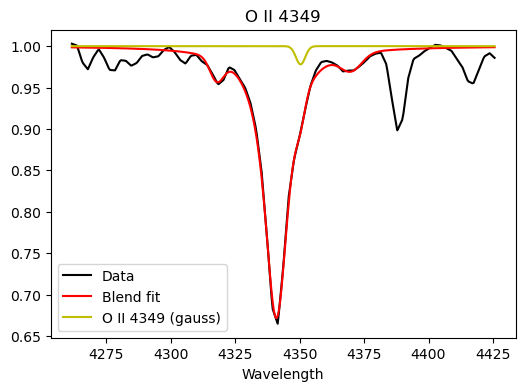

O II 4367 (gauss)
amp = -0.02005590981413983 
mu = 4369.999999999999 
sigma = 4.083698330235726 
offset = 1.0 
chi2 = 0.1355455006820617


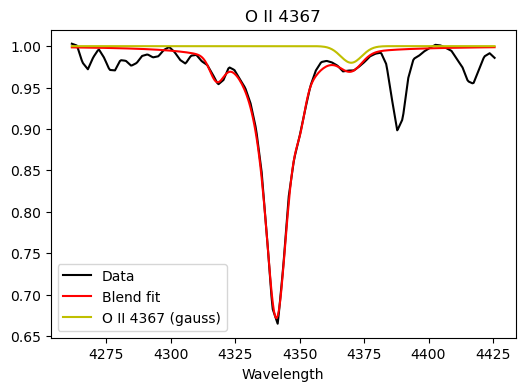

#### H gamma optimization

#### Plotting results for O II 4320

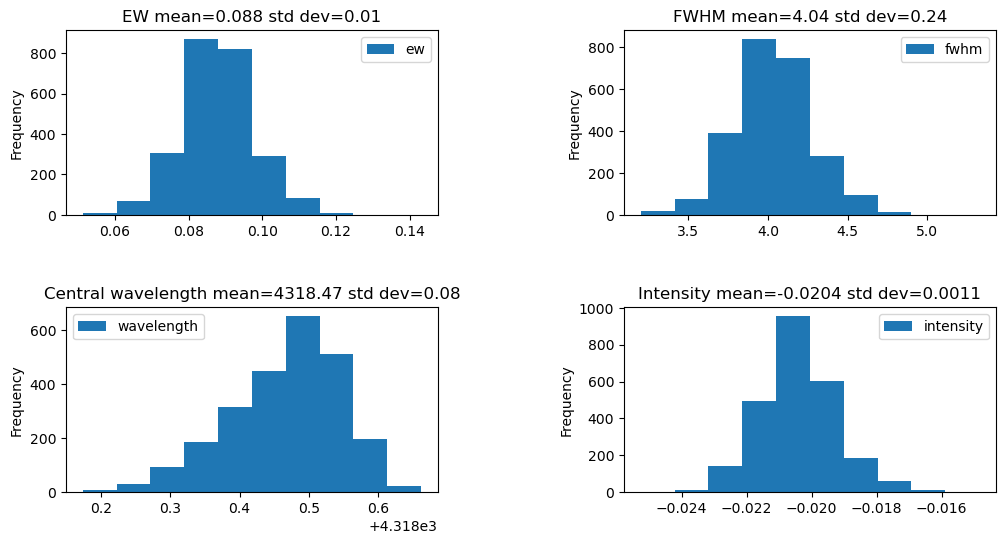

#### Plotting results for H gamma

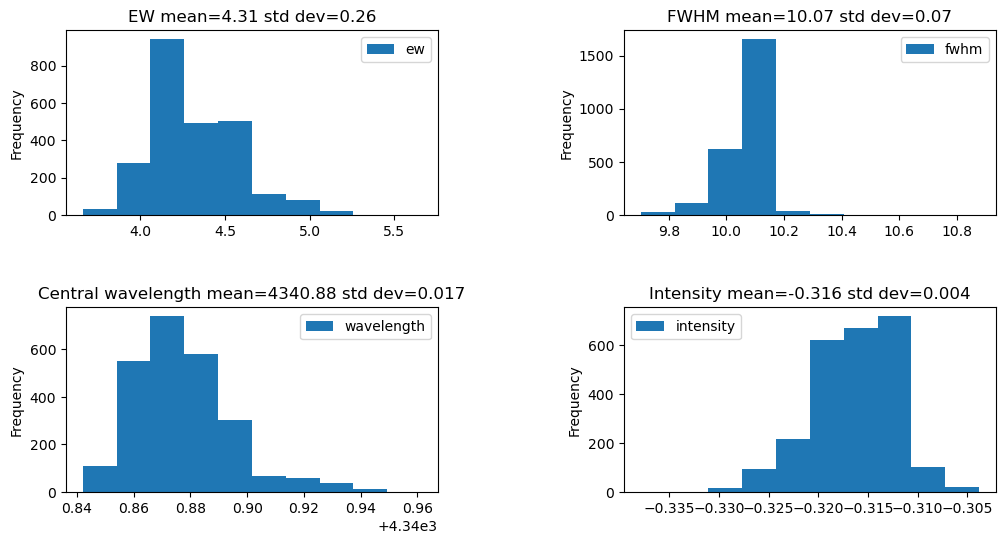

#### Plotting results for O II 4349

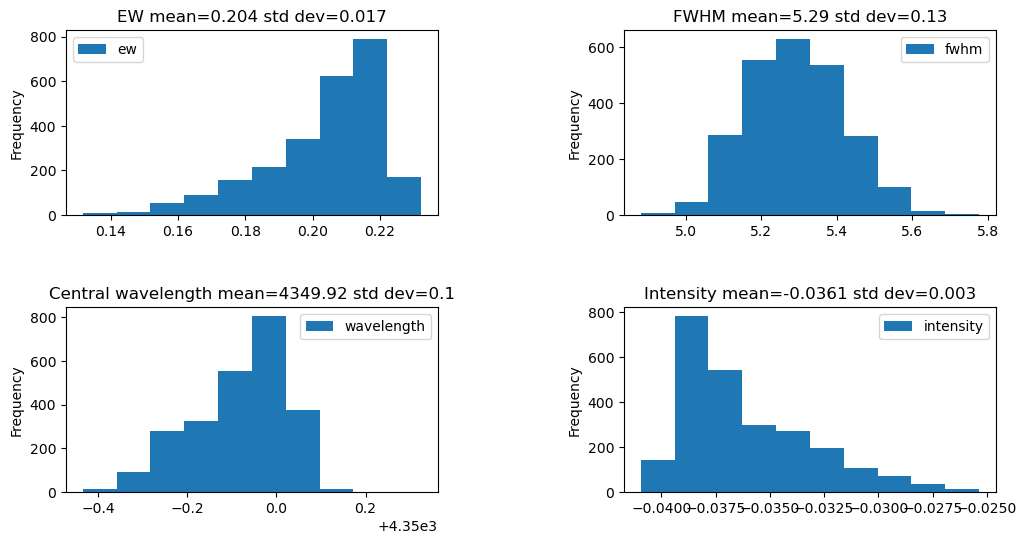

#### Plotting results for O II 4367

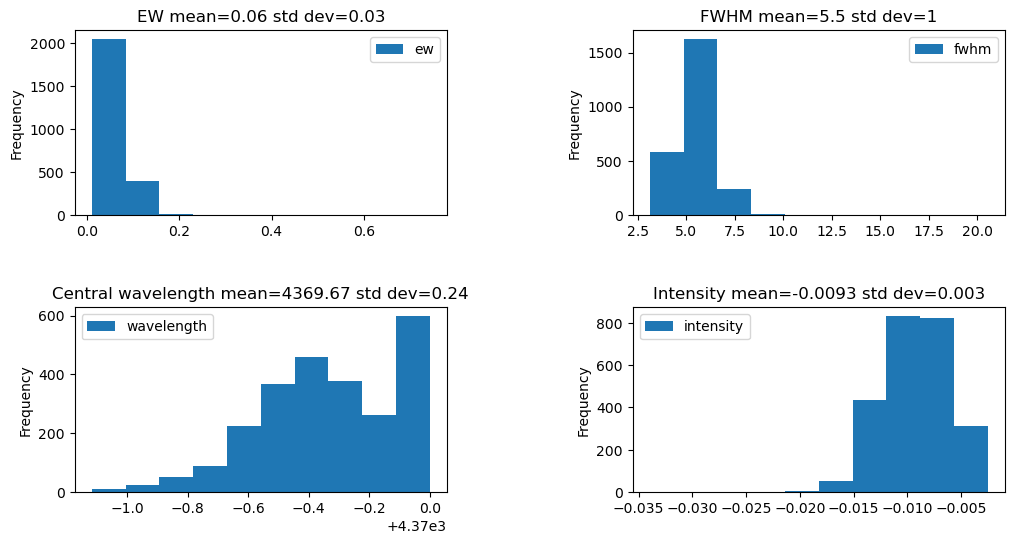

#### H gamma re-fit with best parameters

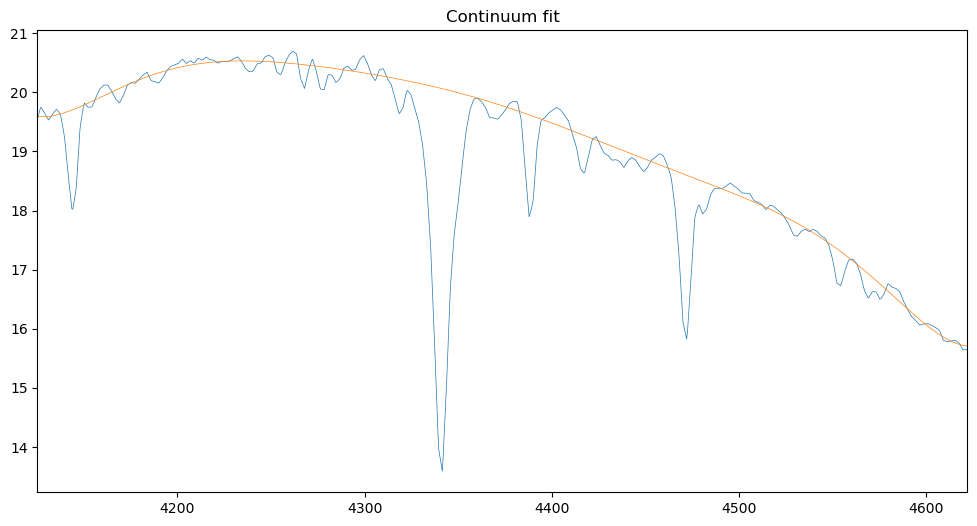

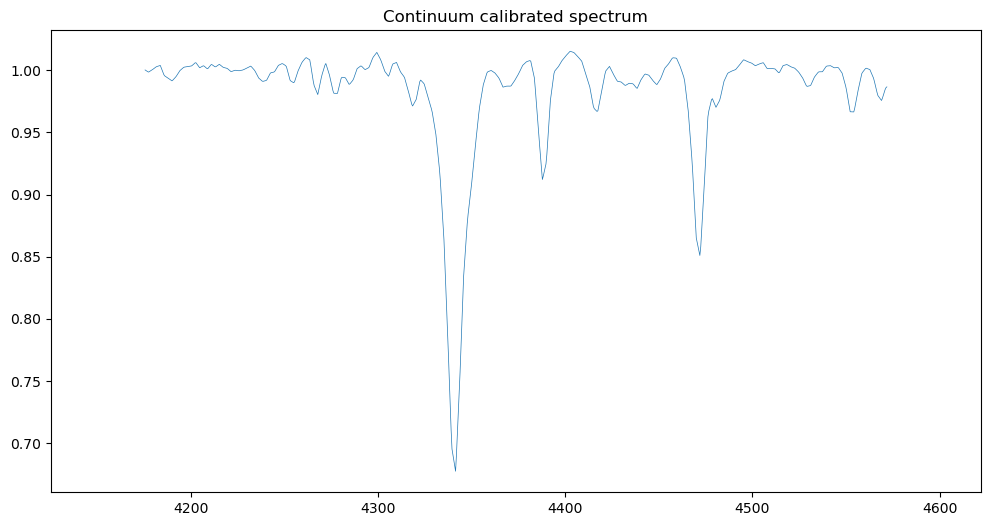

O II 4320 (gauss)
amp = -0.020521995917870937 
mu = 4318.487871838601 
sigma = 1.7176196228451834 
offset = 1.0 
chi2 = 0.08996959655170758


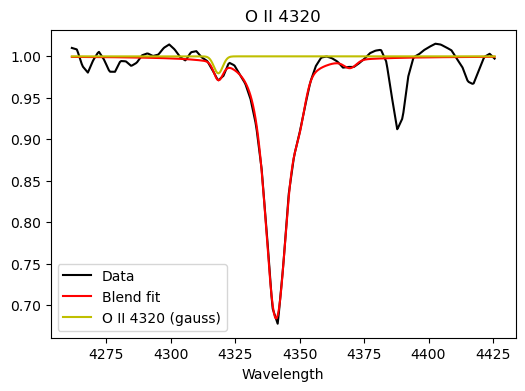

H gamma (voigt)
amp = -4.307644895389913 
mu = 4340.873256481547 
sigma = 2.681124547093775 
gamma = 2.9822172217620344 
offset = 1.0 
chi2 = 0.08996959655170758


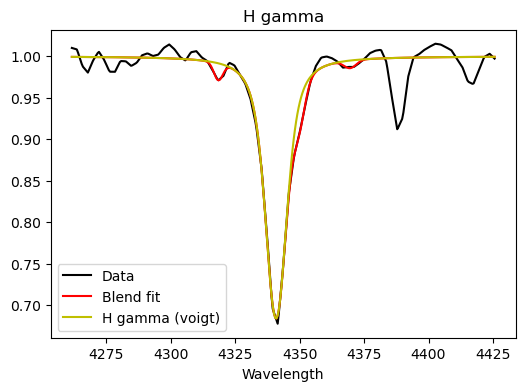

O II 4349 (gauss)
amp = -0.03675112270448562 
mu = 4349.937040688104 
sigma = 2.263403829916559 
offset = 1.0 
chi2 = 0.08996959655170758


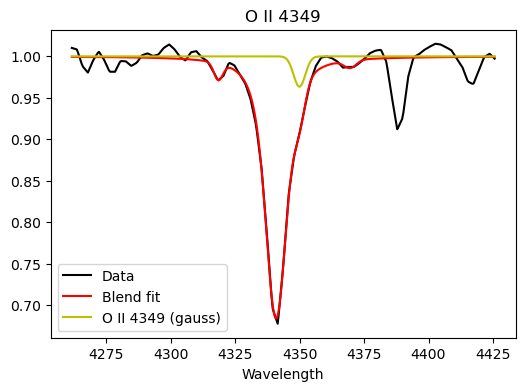

O II 4367 (gauss)
amp = -0.009244514181694414 
mu = 4369.616196124049 
sigma = 2.3292097653032493 
offset = 1.0 
chi2 = 0.08996959655170758


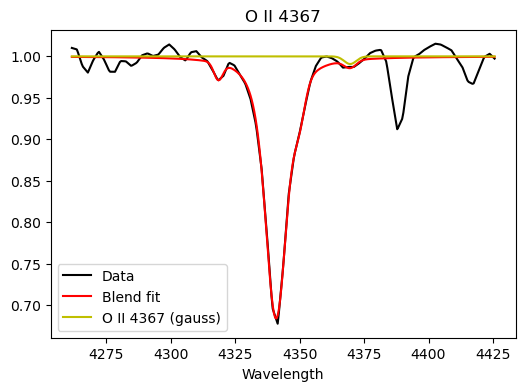

### Measuring H alfa

Blended lines= [{'name': 'Unknown 6535', 'wavelength': 6535.0}, {'name': 'H alfa', 'wavelength': 6563.0, 'model': 'voigt'}, {'name': 'C II 6578', 'wavelength': 6578.0}, {'name': 'C II 6583', 'wavelength': 6583.0}]


#### H alfa preliminary fit

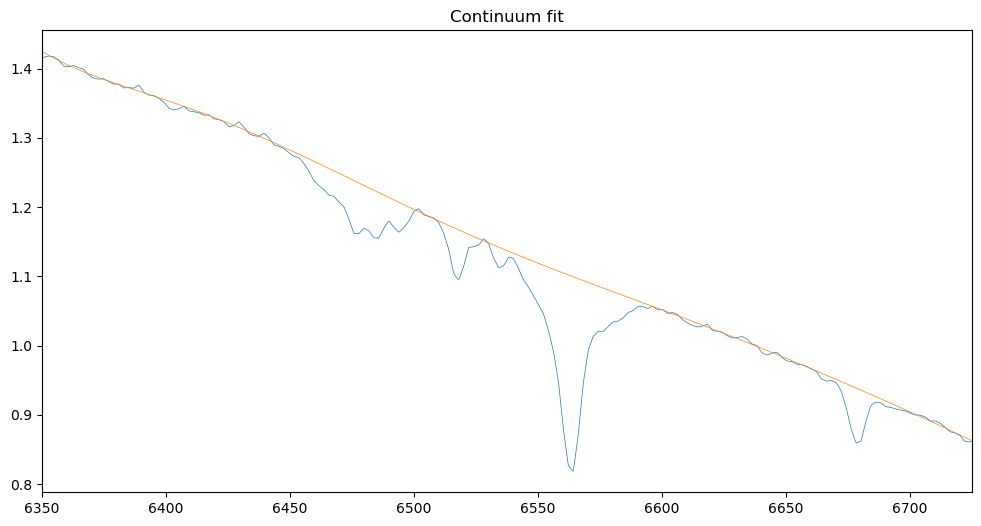

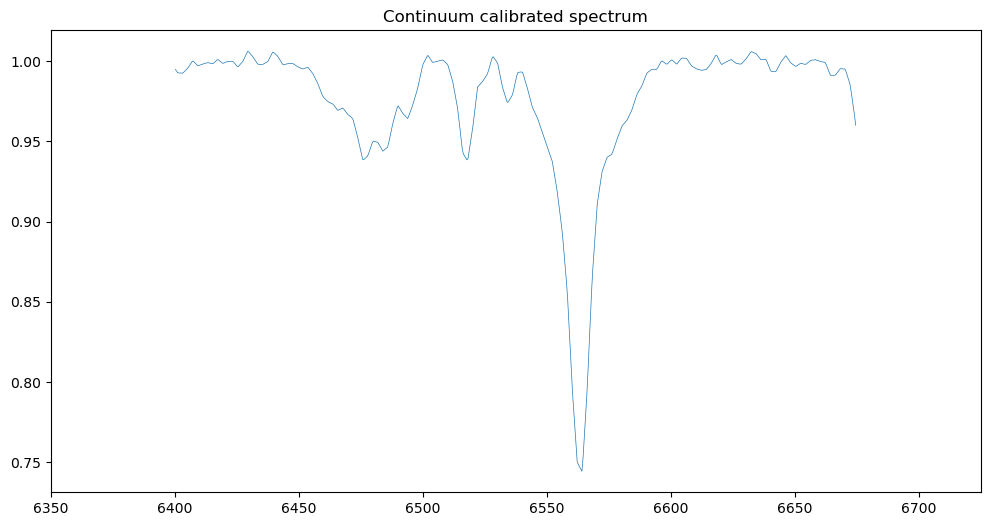

Fit window = (6475.0, 6643.0)
Unknown 6535 (gauss)
amp = -0.01574856623486913 
mu = 6534.316164759357 
sigma = 1.632321718496316 
offset = 1.0 
chi2 = 0.1352030925842513


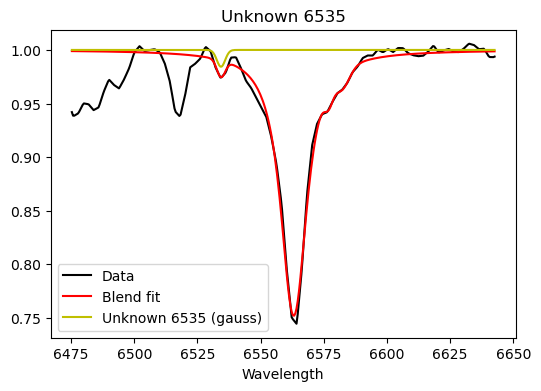

H alfa (voigt)
amp = -4.677313203895274 
mu = 6563.092093573201 
sigma = 1.6393155988510055 
gamma = 5.577715322703153 
offset = 1.0 
chi2 = 0.1352030925842513


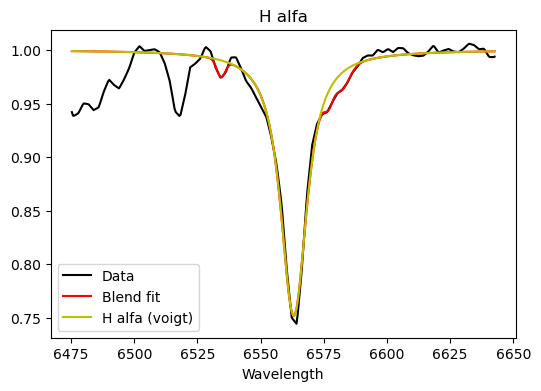

C II 6578 (gauss)
amp = -0.014620318991330247 
mu = 6576.867743749804 
sigma = 1.6436958401421482 
offset = 1.0 
chi2 = 0.1352030925842513


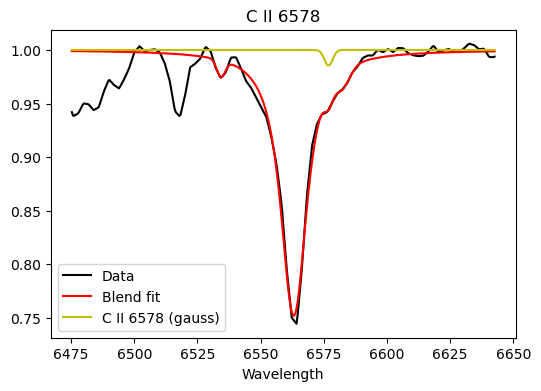

C II 6583 (gauss)
amp = -0.01618217956391007 
mu = 6582.26933337676 
sigma = 2.957392987887014 
offset = 1.0 
chi2 = 0.1352030925842513


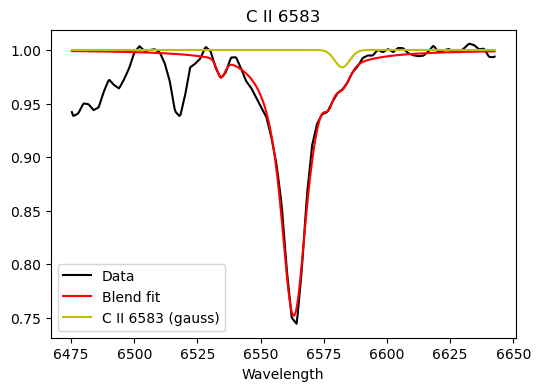

#### H alfa optimization

#### Plotting results for Unknown 6535

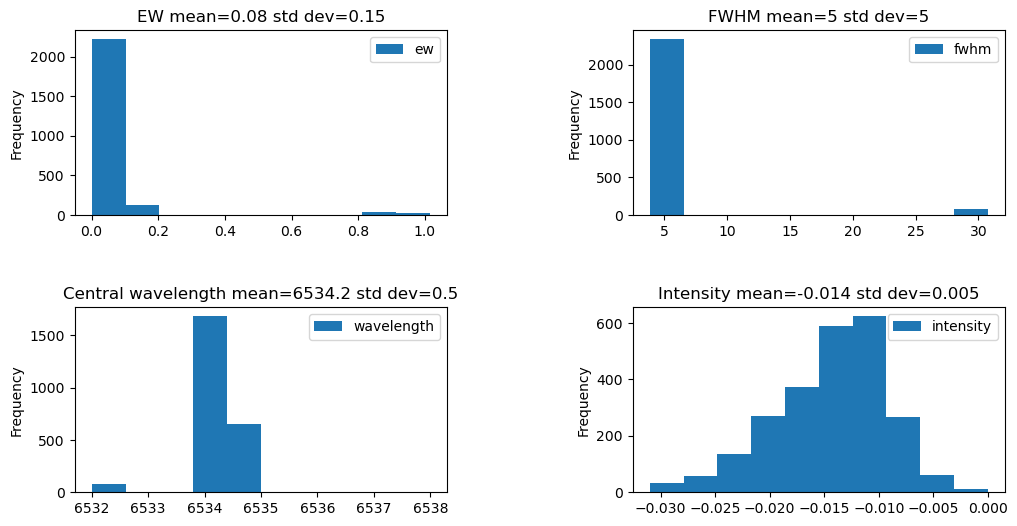

#### Plotting results for H alfa

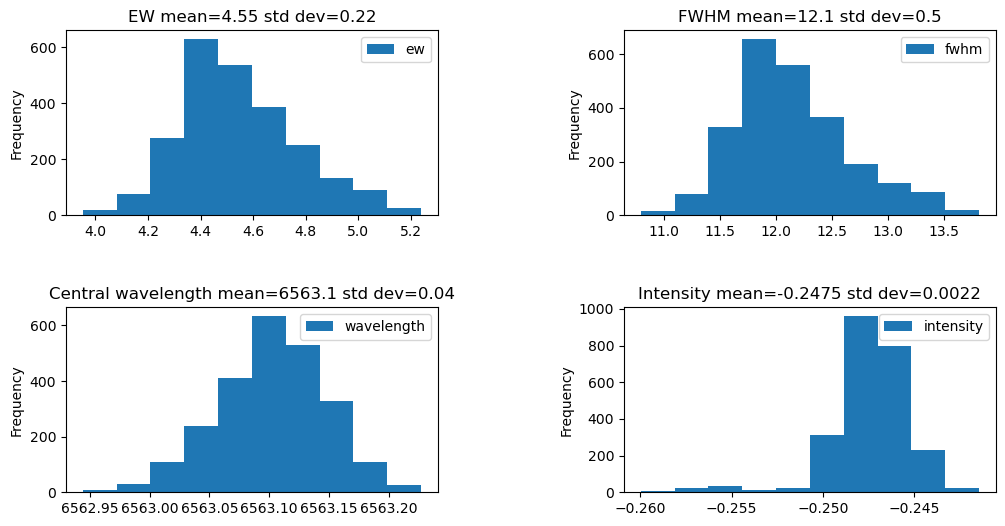

#### Plotting results for C II 6578

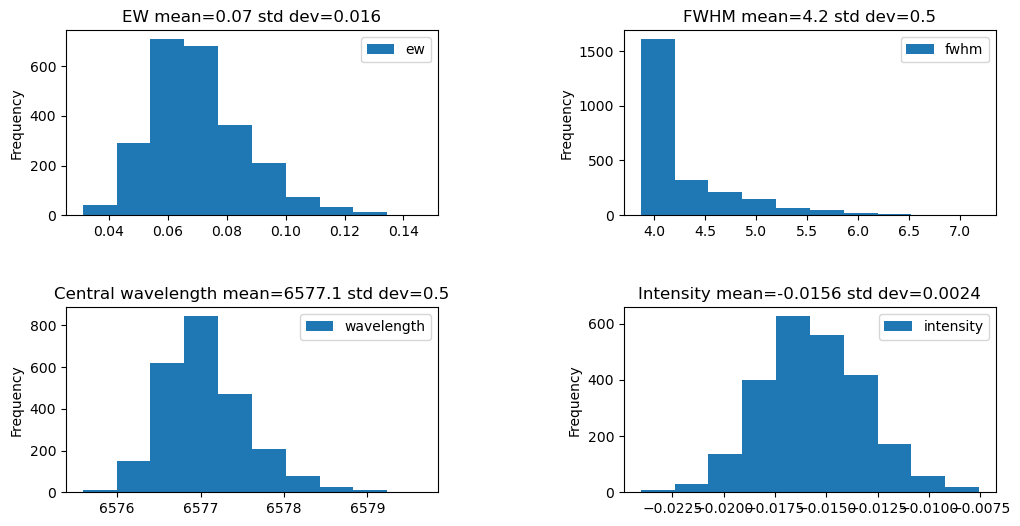

#### Plotting results for C II 6583

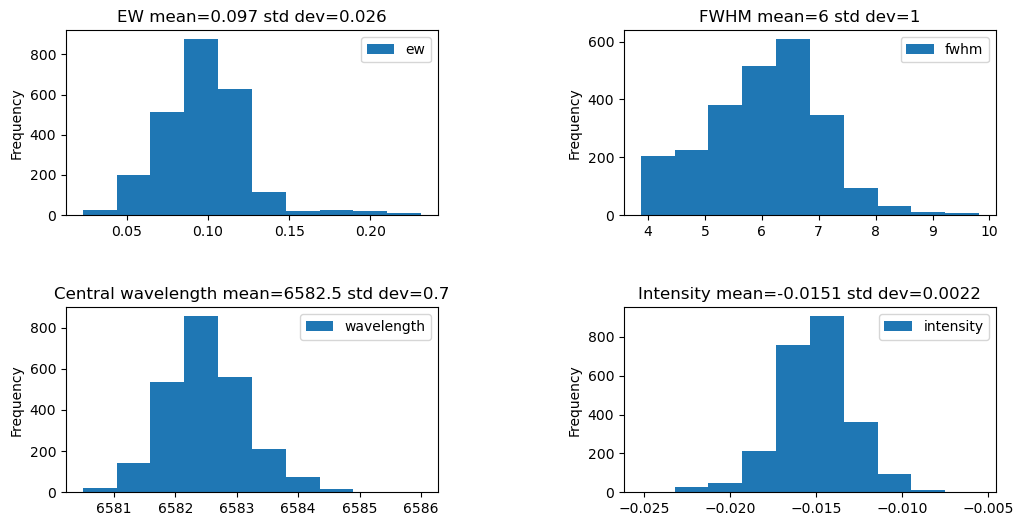

#### H alfa re-fit with best parameters

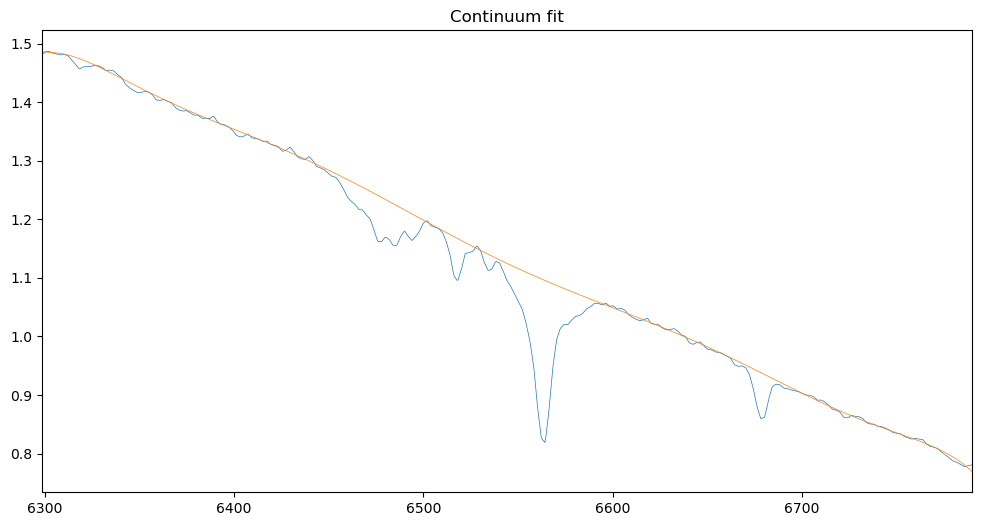

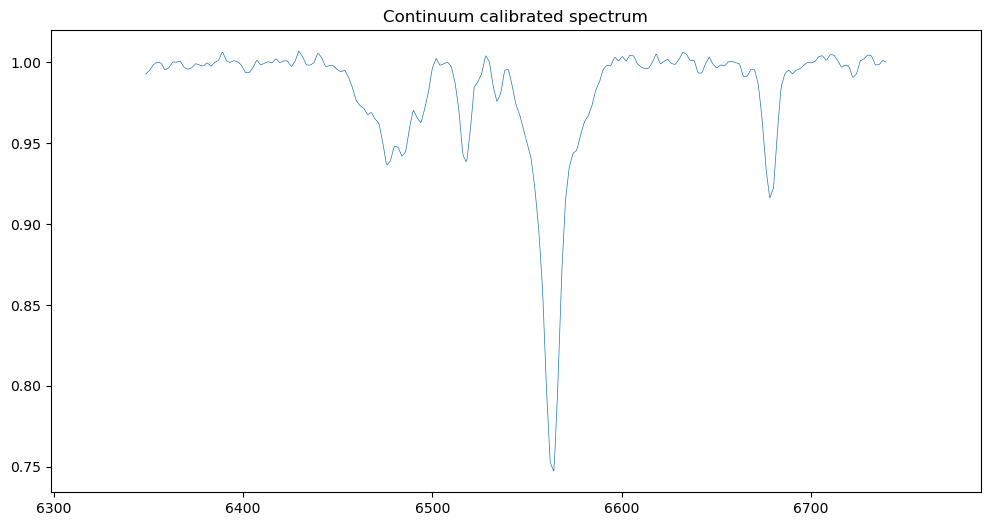

Unknown 6535 (gauss)
amp = -0.014258274891293308 
mu = 6534.298301791321 
sigma = 1.632321718496316 
offset = 1.0 
chi2 = 0.1440215610407594


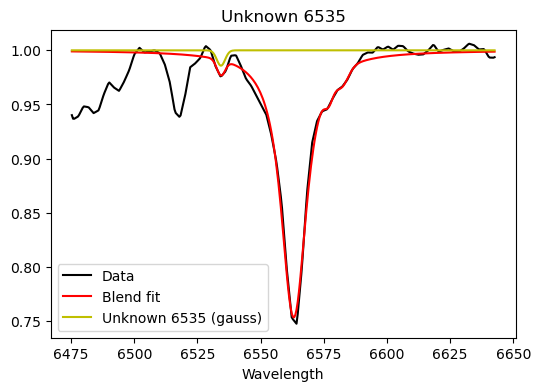

H alfa (voigt)
amp = -4.502400405578327 
mu = 6563.095611184402 
sigma = 1.6393155988510055 
gamma = 5.368800507599182 
offset = 1.0 
chi2 = 0.1440215610407594


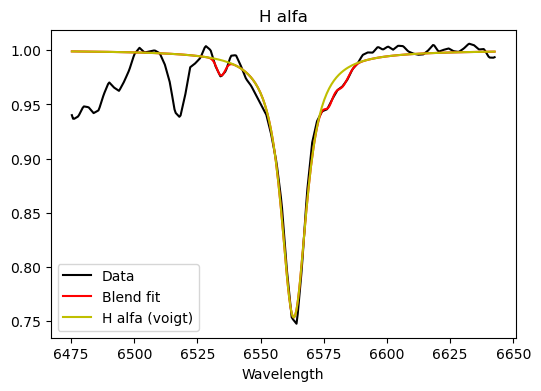

C II 6578 (gauss)
amp = -0.014656049632756421 
mu = 6576.913208989046 
sigma = 1.65900506985225 
offset = 1.0 
chi2 = 0.1440215610407594


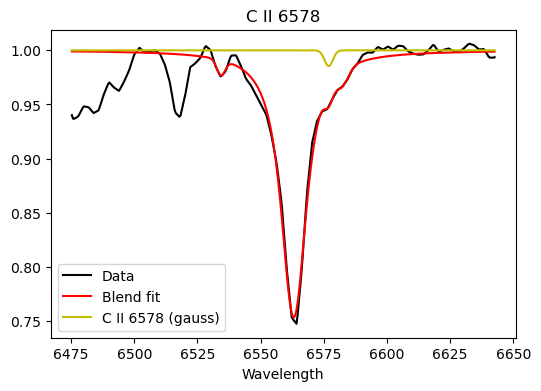

C II 6583 (gauss)
amp = -0.014160453693761135 
mu = 6582.149883940031 
sigma = 2.6039021398954016 
offset = 1.0 
chi2 = 0.1440215610407594


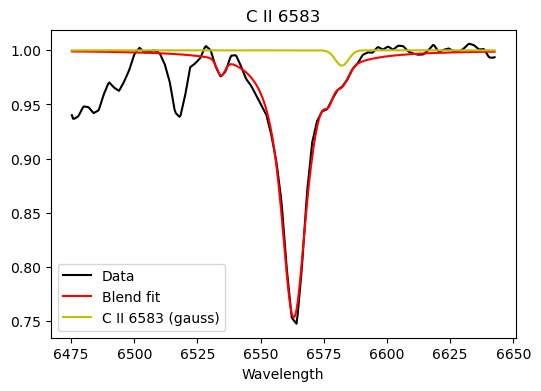

### Measuring S III 4254 / C II 4267

Blended lines= [{'name': 'Unknown 4242', 'wavelength': 4242.0}, {'name': 'S III 4254', 'wavelength': 4254.0}, {'name': 'C II 4267', 'wavelength': 4267.0}, {'name': 'Unknown 4277', 'wavelength': 4277.0}, {'name': 'Unknown 4286', 'wavelength': 4286.0}]


#### S III 4254 / C II 4267 preliminary fit

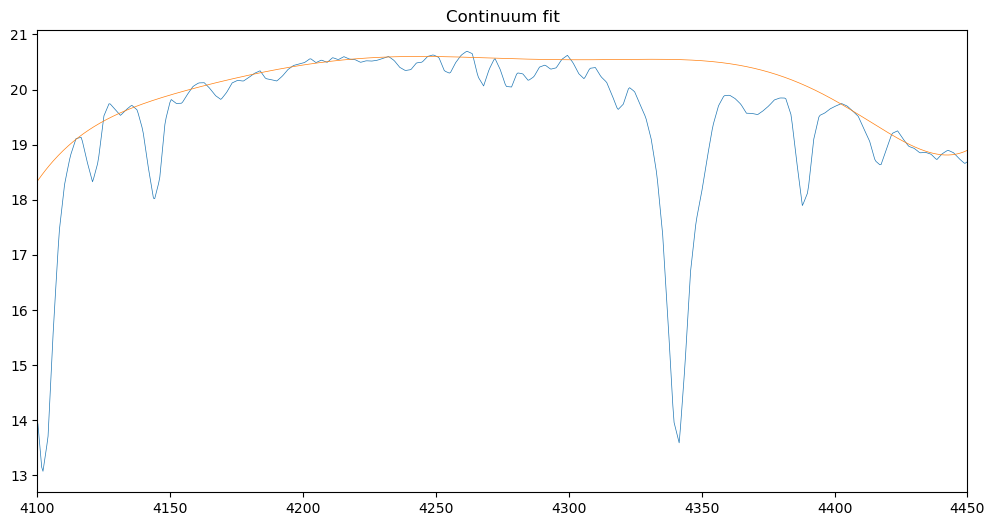

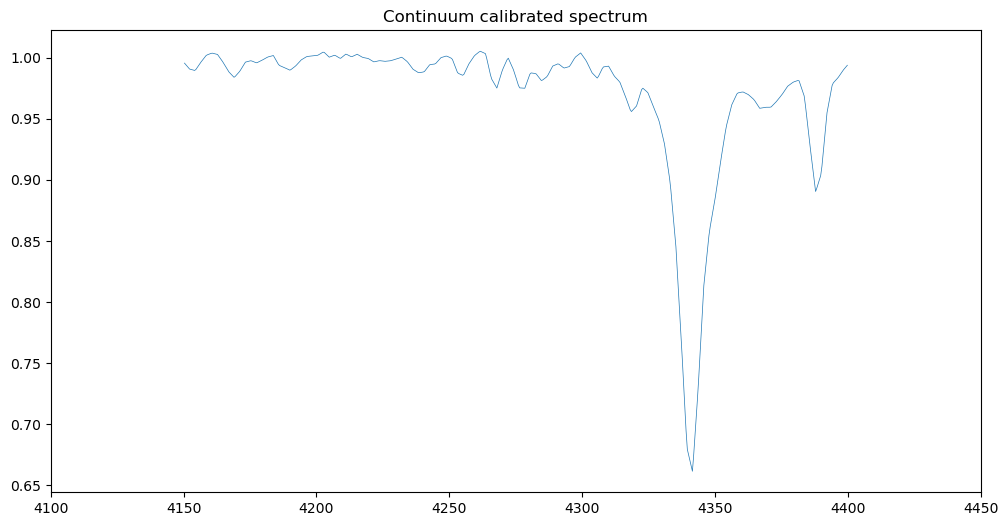

Fit window = (4187.0, 4341.0)
Unknown 4242 (gauss)
amp = -0.01229537001175629 
mu = 4239.173452829585 
sigma = 3.277453035008413 
offset = 1.0 
chi2 = 0.9671846531220684


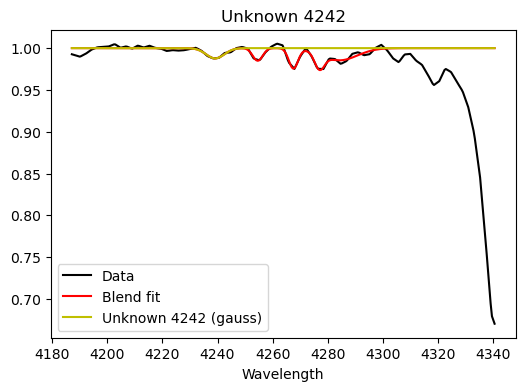

S III 4254 (gauss)
amp = -0.01511806632837492 
mu = 4254.5841130829585 
sigma = 1.8063705114558084 
offset = 1.0 
chi2 = 0.9671846531220684


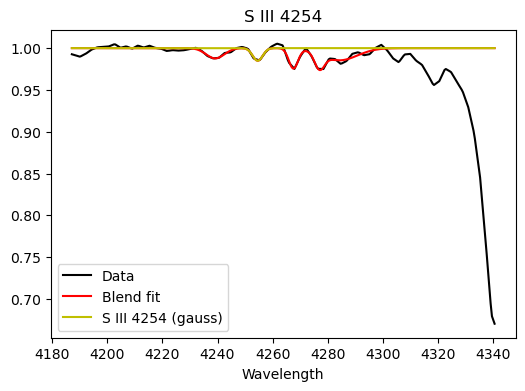

C II 4267 (gauss)
amp = -0.023964180422751797 
mu = 4267.533001931229 
sigma = 1.6538335843816472 
offset = 1.0 
chi2 = 0.9671846531220684


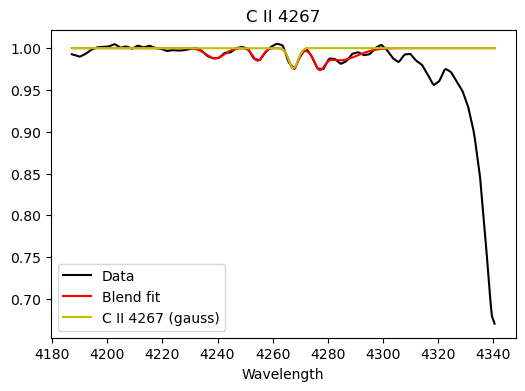

Unknown 4277 (gauss)
amp = -0.018233120065256188 
mu = 4276.98782494272 
sigma = 1.7511769929784406 
offset = 1.0 
chi2 = 0.9671846531220684


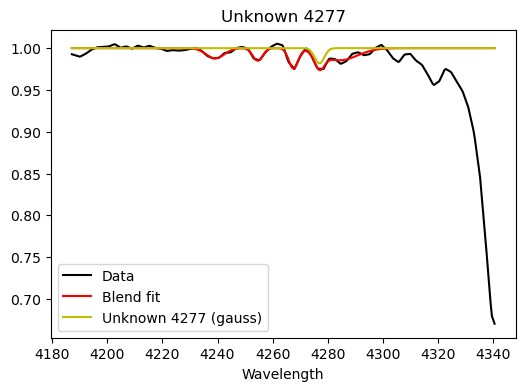

Unknown 4286 (gauss)
amp = -0.014612649758694205 
mu = 4284.172047089731 
sigma = 6.536368025600674 
offset = 1.0 
chi2 = 0.9671846531220684


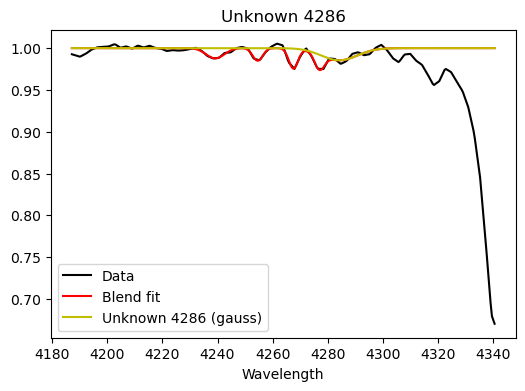

#### S III 4254 / C II 4267 optimization

#### Plotting results for Unknown 4242

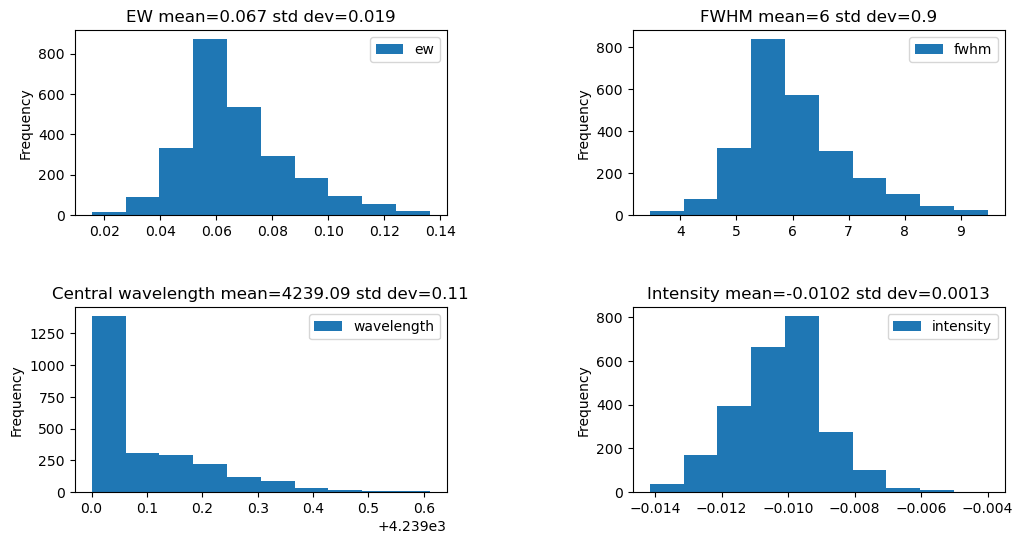

#### Plotting results for S III 4254

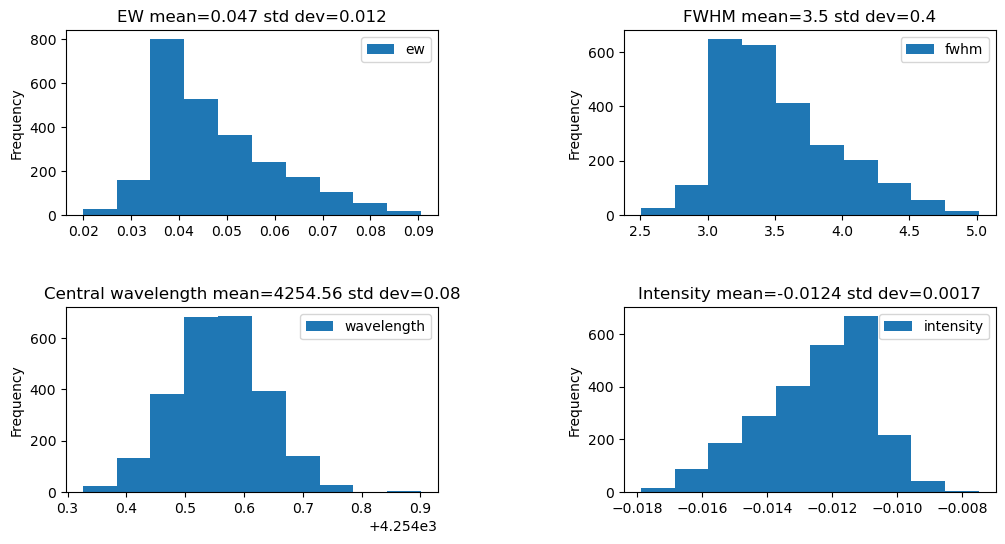

#### Plotting results for C II 4267

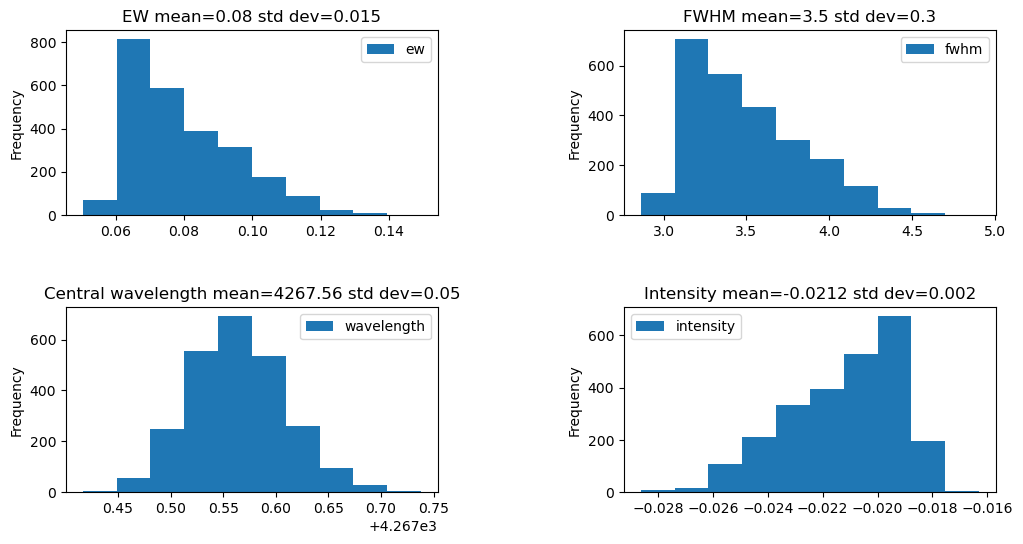

#### Plotting results for Unknown 4277

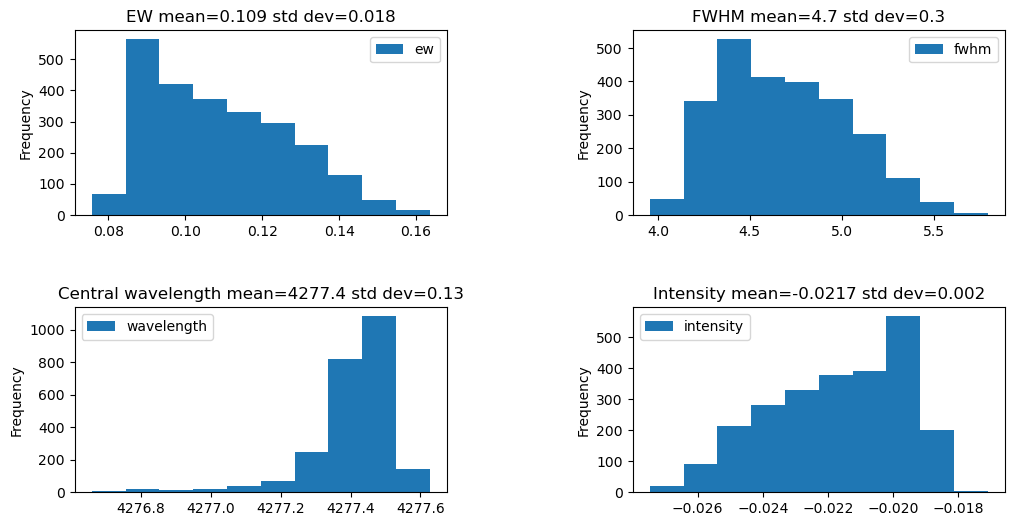

#### Plotting results for Unknown 4286

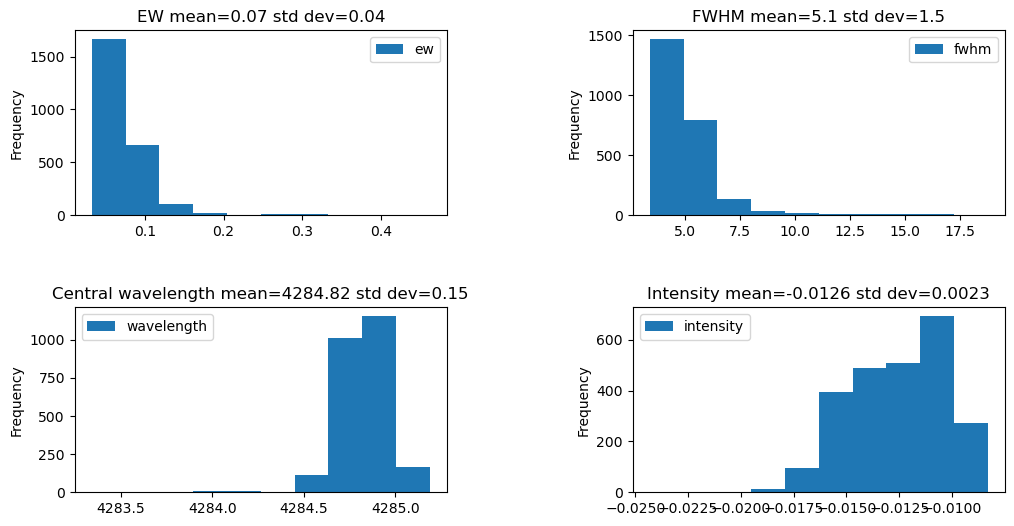

#### S III 4254 / C II 4267 re-fit with best parameters

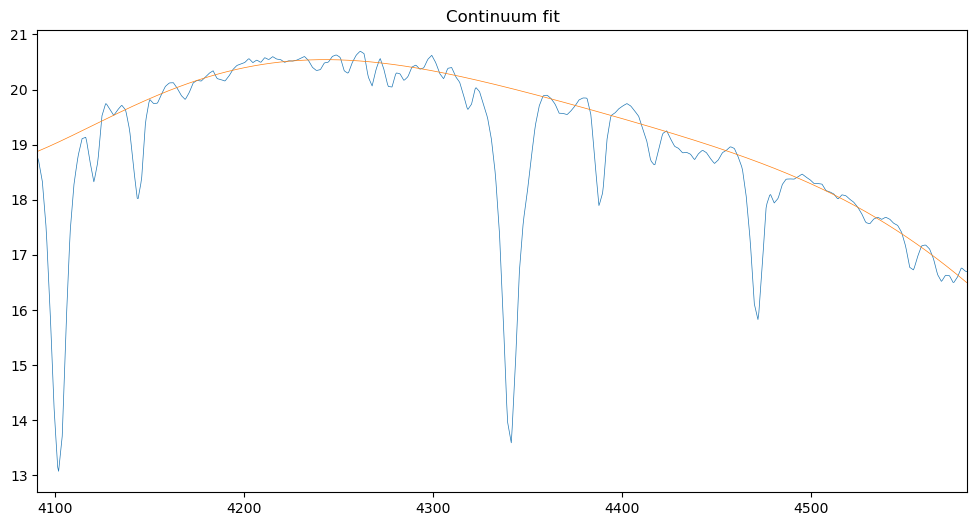

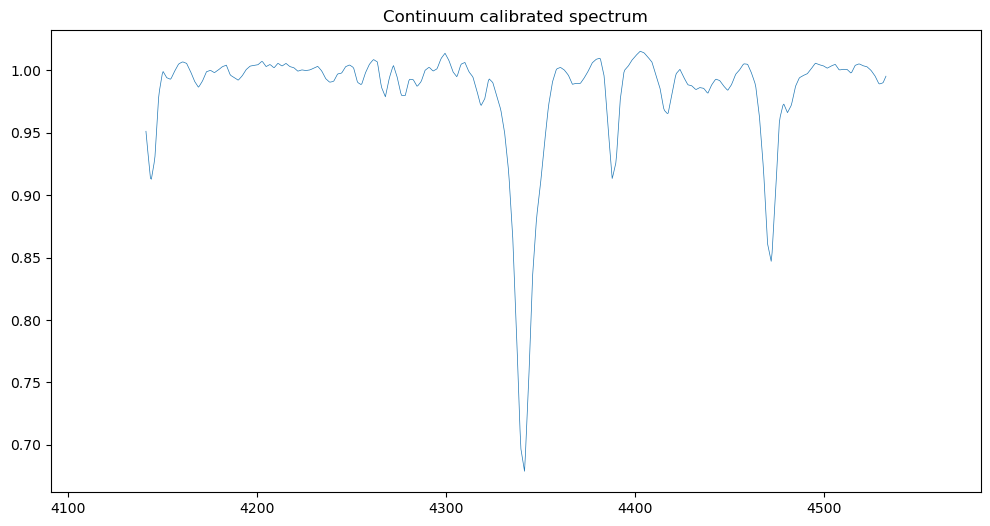

Unknown 4242 (gauss)
amp = -0.009987779704077675 
mu = 4239.056577399529 
sigma = 2.4428249976507033 
offset = 1.0 
chi2 = 0.7888270358255458


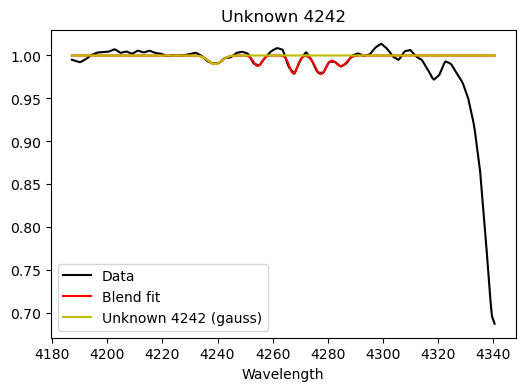

S III 4254 (gauss)
amp = -0.012286951748320325 
mu = 4254.557302034964 
sigma = 1.4736345608125296 
offset = 1.0 
chi2 = 0.7888270358255458


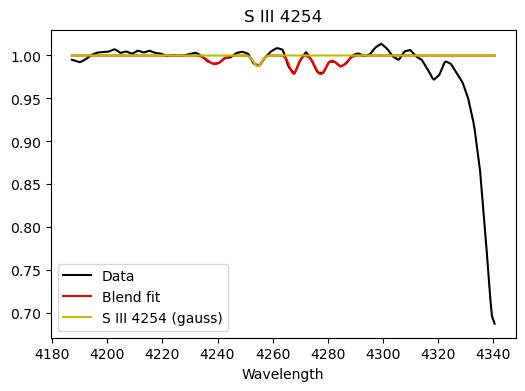

C II 4267 (gauss)
amp = -0.021034834344885456 
mu = 4267.562712819952 
sigma = 1.4696141500156865 
offset = 1.0 
chi2 = 0.7888270358255458


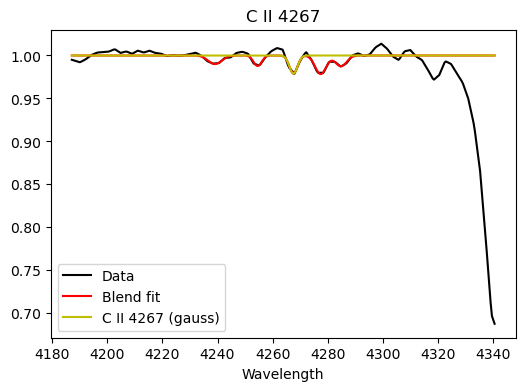

Unknown 4277 (gauss)
amp = -0.021699926110833666 
mu = 4277.445360089657 
sigma = 2.0004901891101503 
offset = 1.0 
chi2 = 0.7888270358255458


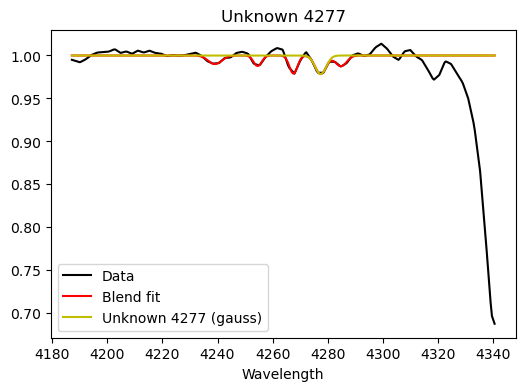

Unknown 4286 (gauss)
amp = -0.012532664623672647 
mu = 4284.824132582343 
sigma = 2.027877764598822 
offset = 1.0 
chi2 = 0.7888270358255458


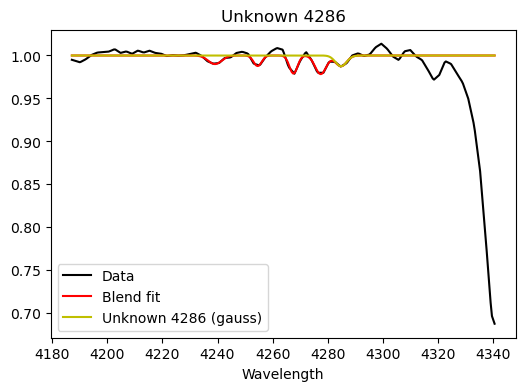

### Measuring He I 5016

Blended lines= [{'name': 'N II 5005', 'wavelength': 5005.0}, {'name': 'He I 5016', 'wavelength': 5016.0}, {'name': 'Unknown 5025', 'wavelength': 5025.0}, {'name': 'Unknown 5035', 'wavelength': 5035.0}, {'name': 'He I 5048', 'wavelength': 5048.0}, {'name': 'He I 5055', 'wavelength': 5055.0}]


#### He I 5016 preliminary fit

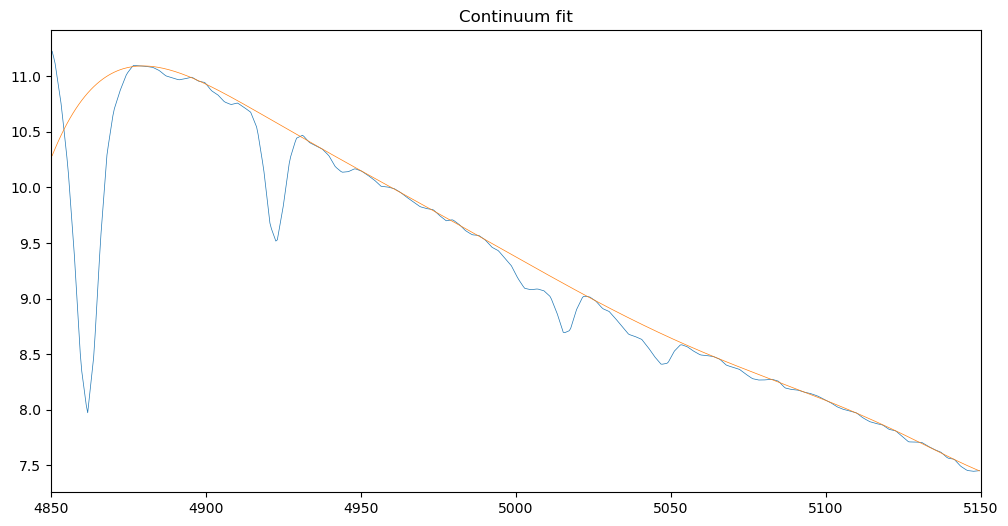

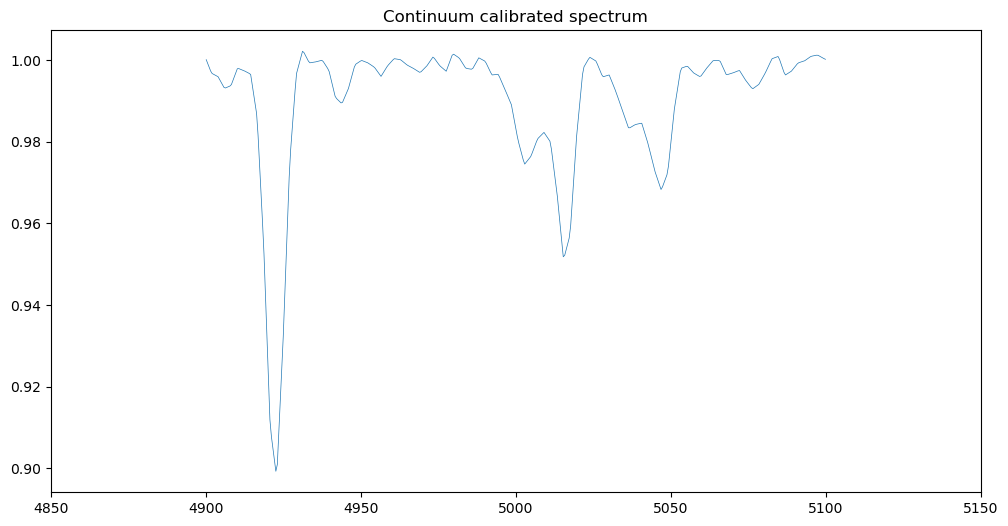

Fit window = (4942.5, 5100.0)
N II 5005 (gauss)
amp = -0.024033514806723128 
mu = 5004.358529032985 
sigma = 5.165944723176624 
offset = 1.0 
chi2 = 0.001826814048269251


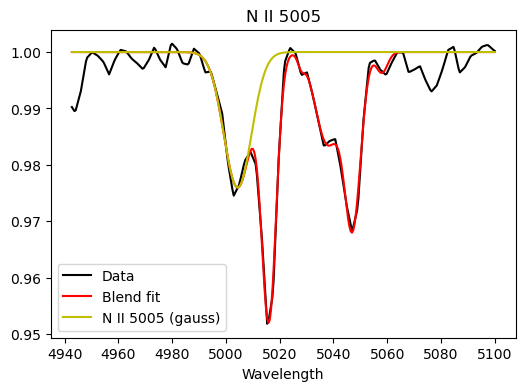

He I 5016 (gauss)
amp = -0.0461054320398073 
mu = 5016.008665003915 
sigma = 2.70779707158308 
offset = 1.0 
chi2 = 0.001826814048269251


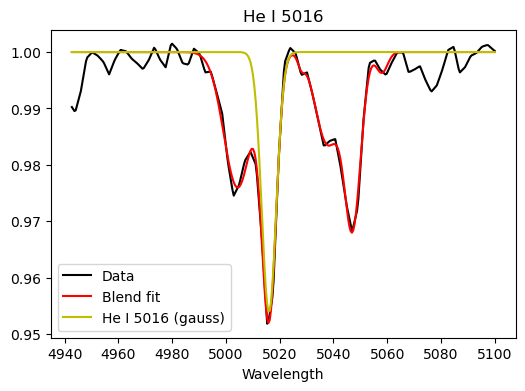

Unknown 5025 (gauss)
amp = -0.001934102257322714 
mu = 5027.999999999999 
sigma = 1.255151742225553 
offset = 1.0 
chi2 = 0.001826814048269251


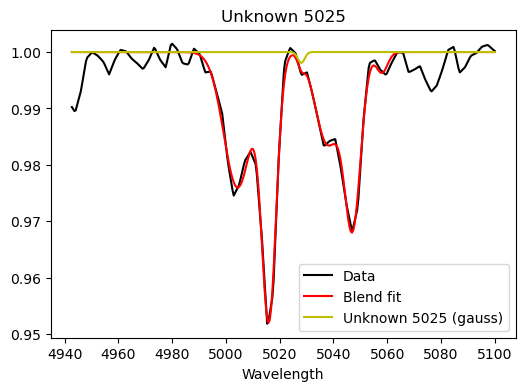

Unknown 5035 (gauss)
amp = -0.016272422084158175 
mu = 5037.810308629627 
sigma = 4.4917814887362795 
offset = 1.0 
chi2 = 0.001826814048269251


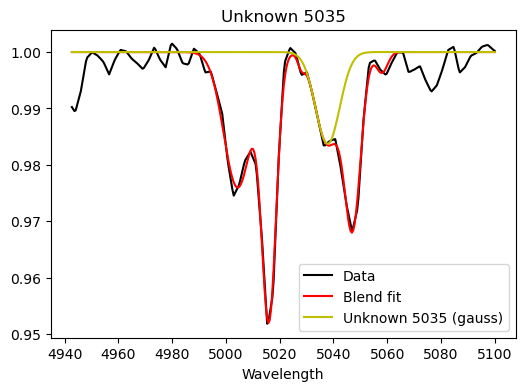

He I 5048 (gauss)
amp = -0.030010364290045874 
mu = 5047.124467726079 
sigma = 3.0254913559234566 
offset = 1.0 
chi2 = 0.001826814048269251


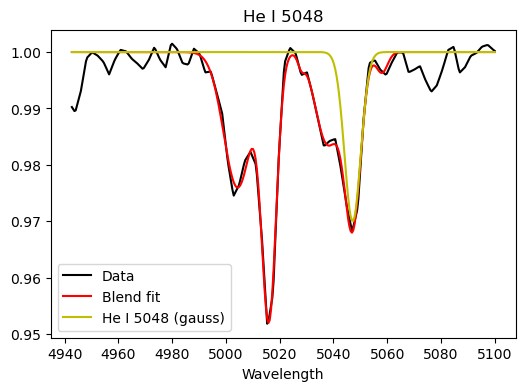

He I 5055 (gauss)
amp = -0.0036649941801297245 
mu = 5057.999999999999 
sigma = 2.113188134118696 
offset = 1.0 
chi2 = 0.001826814048269251


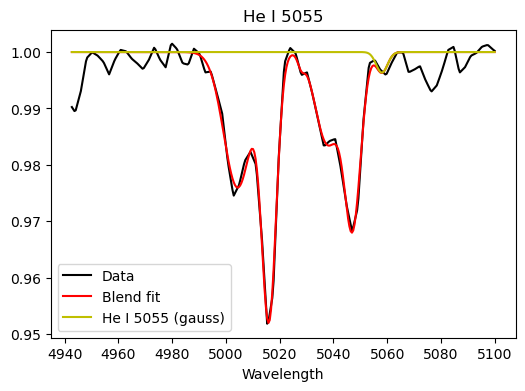

#### He I 5016 optimization

#### Plotting results for N II 5005

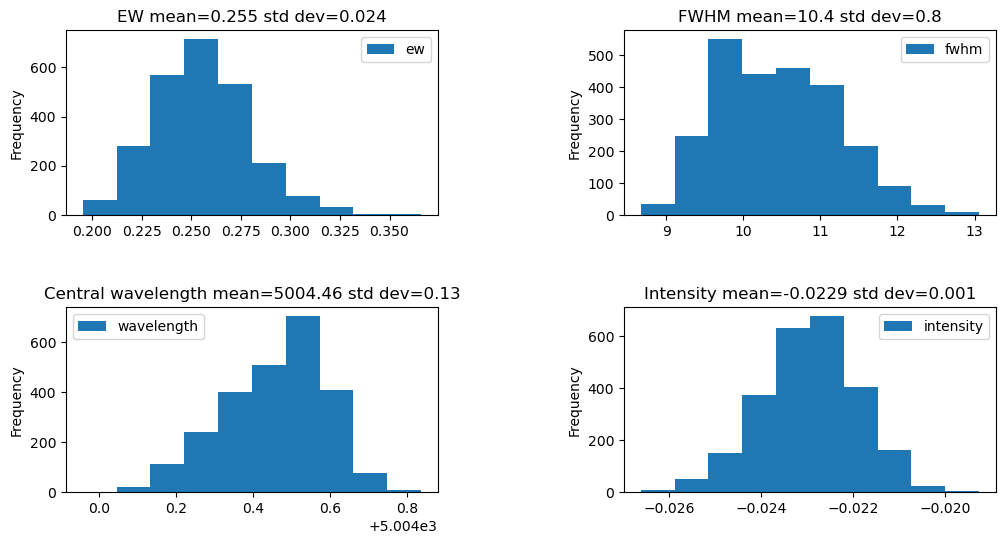

#### Plotting results for He I 5016

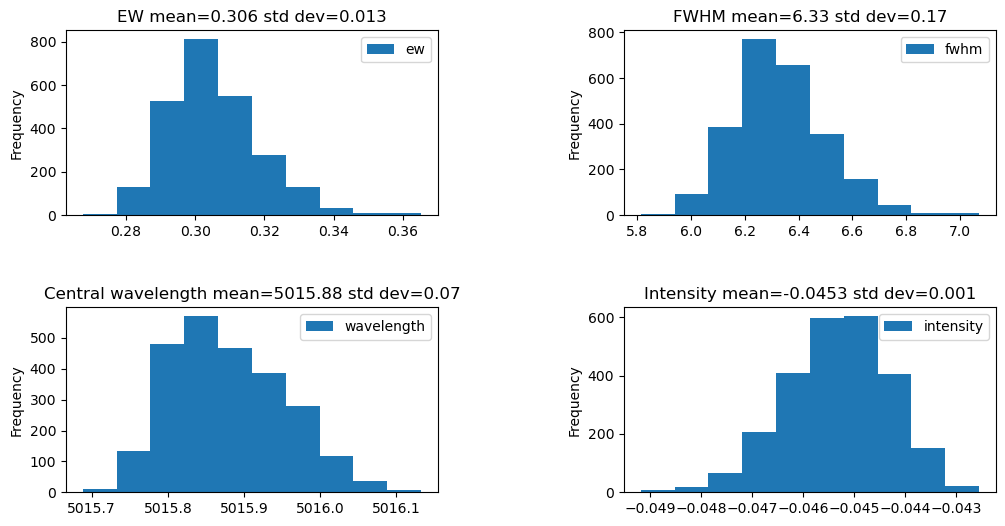

#### Plotting results for Unknown 5025

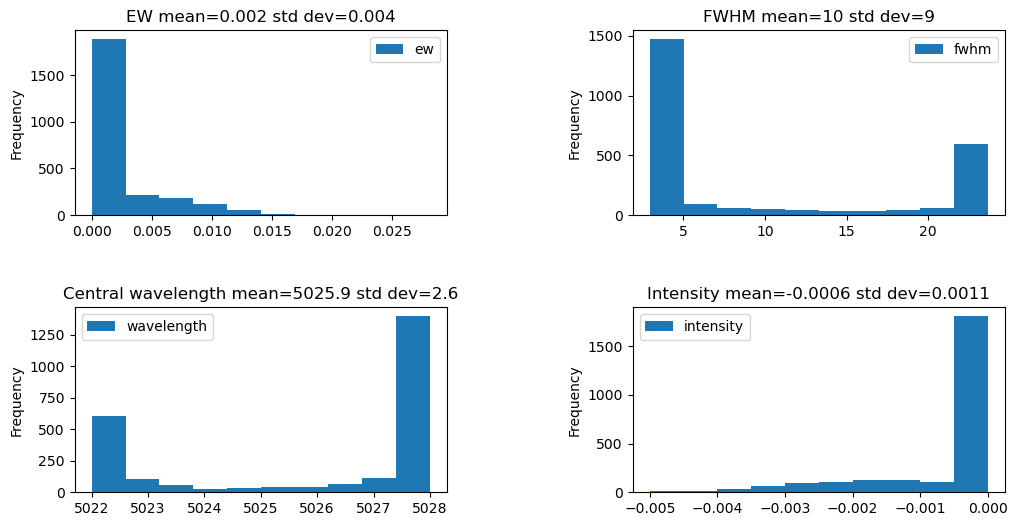

#### Plotting results for Unknown 5035

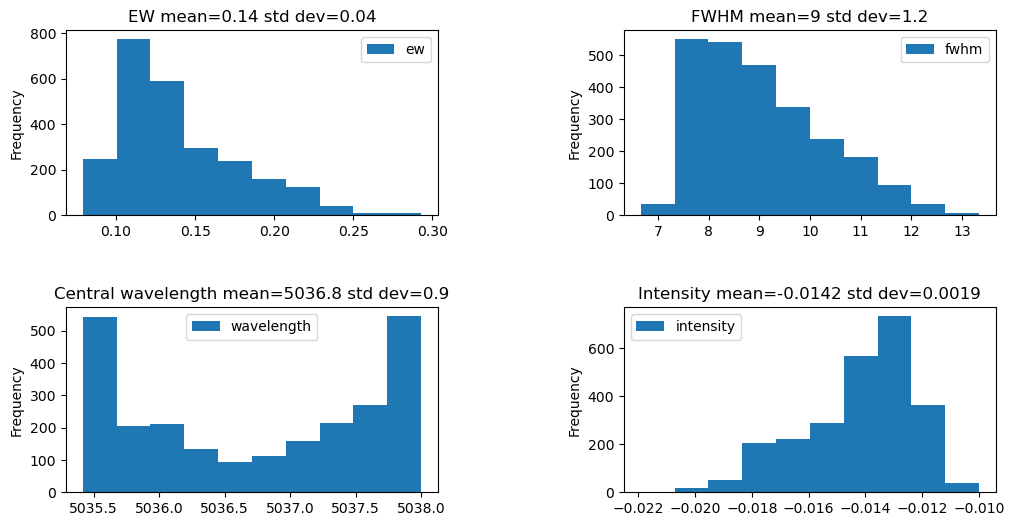

#### Plotting results for He I 5048

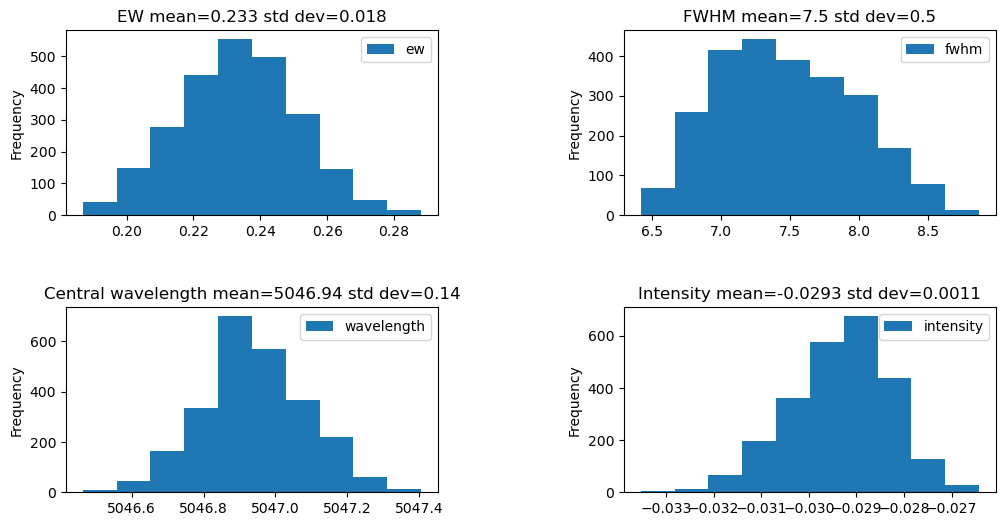

#### Plotting results for He I 5055

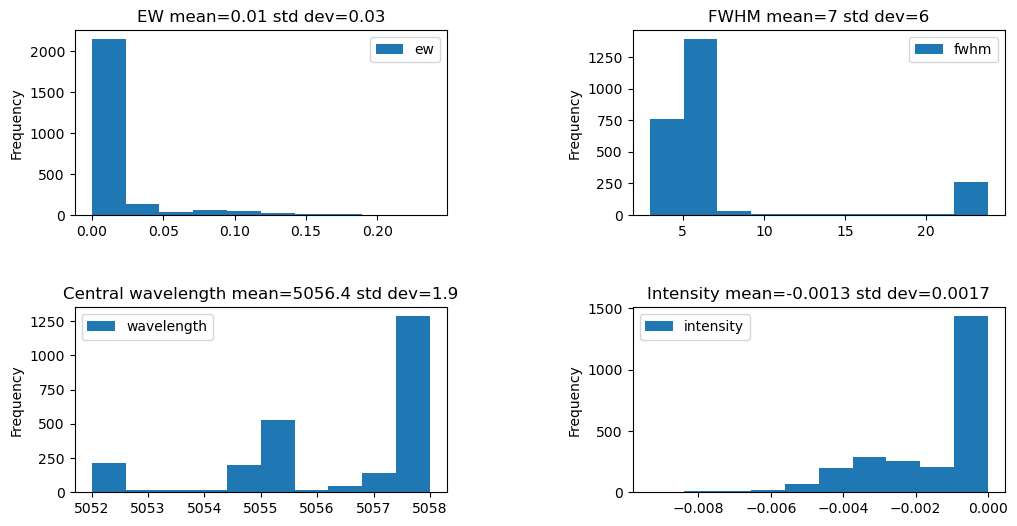

#### He I 5016 re-fit with best parameters

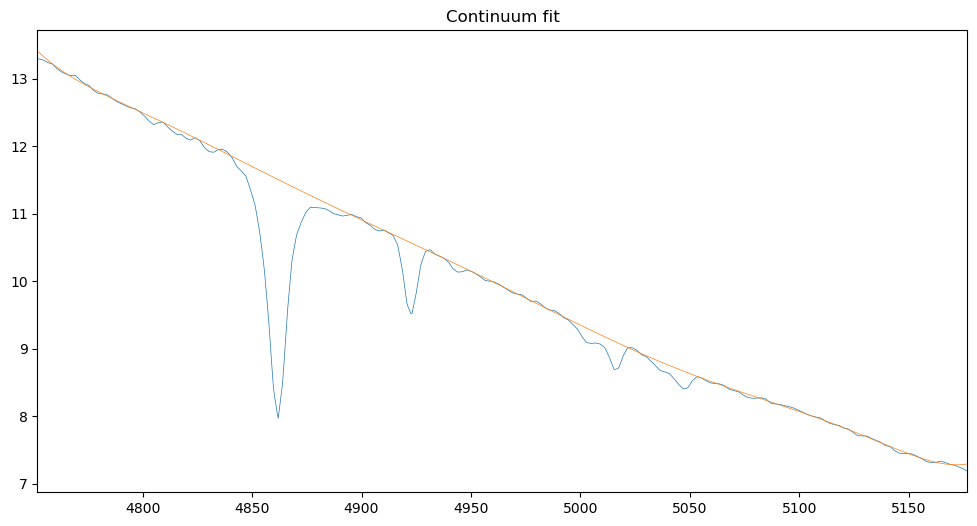

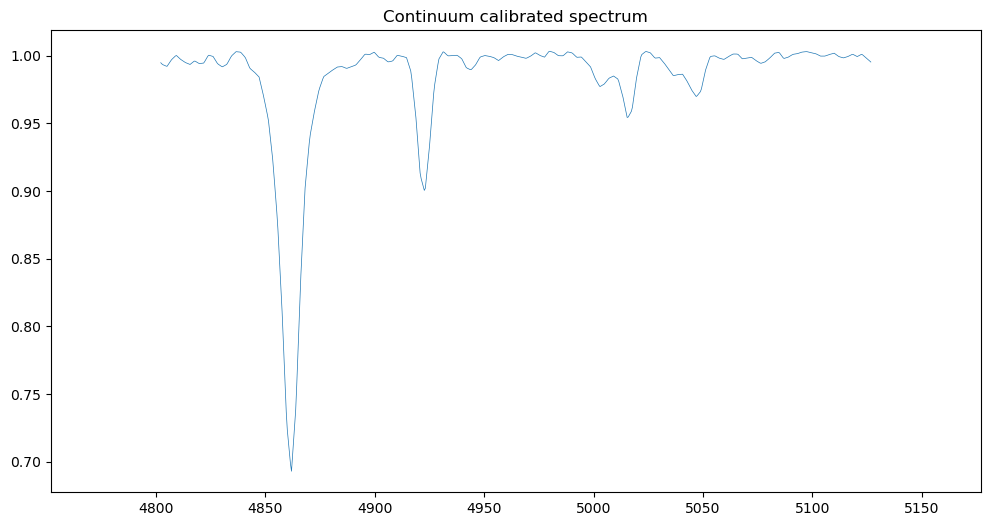

N II 5005 (gauss)
amp = -0.023033042722125568 
mu = 5004.526956006715 
sigma = 4.035851213982379 
offset = 1.0 
chi2 = 0.0019758556221726063


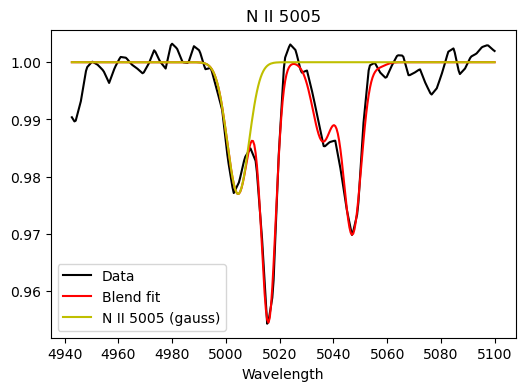

He I 5016 (gauss)
amp = -0.04503990442687996 
mu = 5015.8096284766325 
sigma = 2.7126142681069614 
offset = 1.0 
chi2 = 0.0019758556221726063


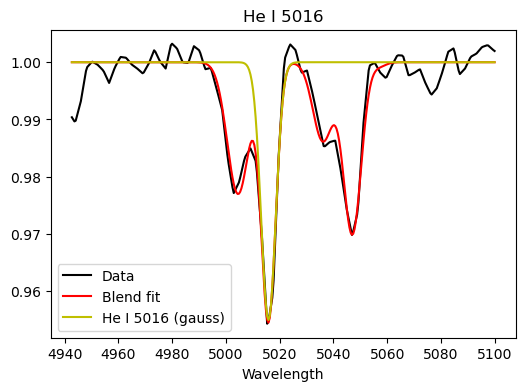

Unknown 5025 (gauss)
amp = -3.4673142465016917e-22 
mu = 5027.961223337344 
sigma = 1.2613635587293128 
offset = 1.0 
chi2 = 0.0019758556221726063


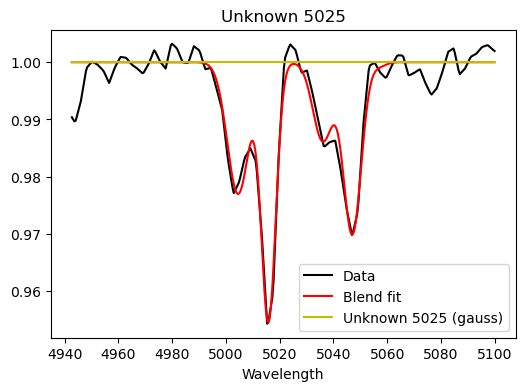

Unknown 5035 (gauss)
amp = -0.01375915446363924 
mu = 5036.044052041938 
sigma = 3.694657091439742 
offset = 1.0 
chi2 = 0.0019758556221726063


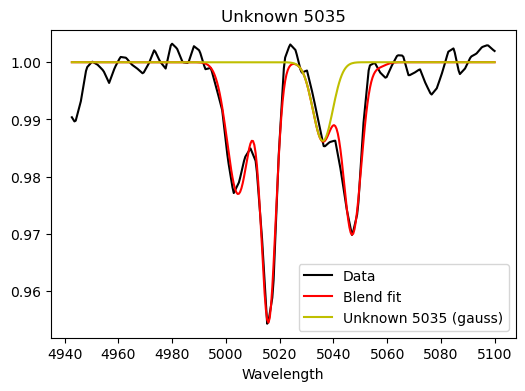

He I 5048 (gauss)
amp = -0.02999134157572281 
mu = 5046.998777520226 
sigma = 3.3202503029547232 
offset = 1.0 
chi2 = 0.0019758556221726063


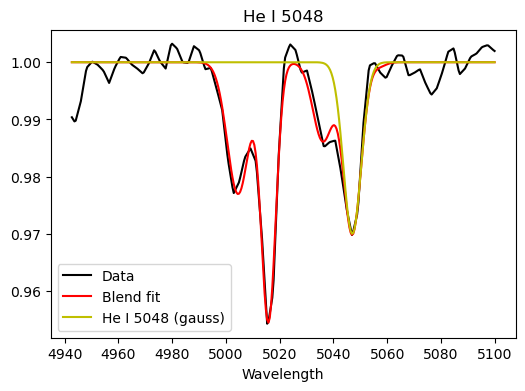

He I 5055 (gauss)
amp = -0.0006901070878590769 
mu = 5057.166239969514 
sigma = 2.3928447357852476 
offset = 1.0 
chi2 = 0.0019758556221726063


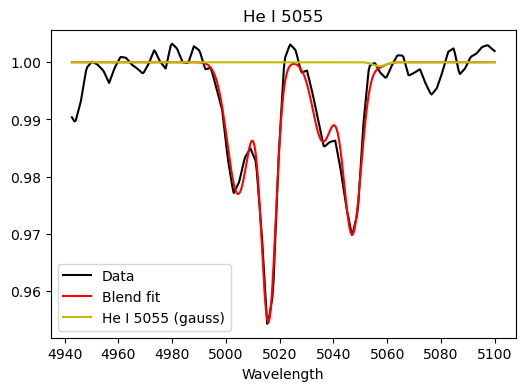

In [32]:
for measuring_blend in measuring_blends:
    results = measure_blend(wl, flux, measuring_blend, show_param_dependencies=SHOW_PARAM_DEPENDENCIES)
    summary_results = pd.concat([summary_results, results], axis=0)

## Summary Results

In [33]:
summary_results = summary_results.sort_values(by=["wavelength"], ascending=False)

summary_results


,line_name,wavelength,delta_wavelength,ew,delta_ew,fwhm,delta_fwhm,intensity,delta_intensity
5,He I 6678,6678.651117,0.067028,0.646452,0.026574,7.522081,0.244541,-0.080736,0.001766
3,C II 6583,6582.51811,0.665539,0.09742,0.025683,6.024048,1.010934,-0.015052,0.002171
2,C II 6578,6577.064475,0.510743,0.070348,0.016375,4.200225,0.496542,-0.015627,0.002444
1,H alfa,6563.102491,0.044712,4.545601,0.22114,12.139205,0.506356,-0.24746,0.00218
0,Unknown 6535,6534.226125,0.455505,0.084036,0.145752,4.793677,4.804663,-0.01434,0.005127
5,He I 5055,5056.399029,1.915145,0.01387,0.030011,7.355241,5.838105,-0.001348,0.001736
4,He I 5048,5046.942071,0.144157,0.233387,0.01764,7.473407,0.487999,-0.029337,0.001056
3,Unknown 5035,5036.764849,0.926033,0.139055,0.037928,9.046341,1.226055,-0.014214,0.001948
2,Unknown 5025,5025.947846,2.560172,0.0019,0.003622,9.525688,8.749576,-0.000577,0.001062
1,He I 5016,5015.878854,0.073639,0.305508,0.013149,6.330814,0.165896,-0.045324,0.001011


In [34]:
summary_results.to_csv("line_measured_sigma_cas_20250919.csv")